# Modulación LoRa (FSCM)

Este notebook modela en Python la capa física de LoRa a partir del análisis de L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960), *IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017. Se implementan el transmisor y el receptor que describe el paper, con la forma del *chirp* que transmite LoRa, se mide la tasa de error de bits (BER) en un canal plano y en uno selectivo en frecuencia, se comparan cinco métodos para detectar el comienzo de una trama, dos de ellos basados en estimar la respuesta al impulso del canal, y, por último, se prueba el receptor con un SDR.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |

### Modulación LoRa

LoRa es la capa física de LoRaWAN, una red pensada para dispositivos de Internet de las cosas (IoT) que envían pocos datos a gran distancia y con bajo consumo. Su modulación está [patentada](https://patents.google.com/patent/US8406275B2/en) y, hasta el análisis de Vangelista, no tenía una descripción matemática publicada. Vangelista la describe como una modulación por corrimiento de frecuencia de un *chirp*, FSCM (*Frequency Shift Chirp Modulation*).

### Contenidos

1. [Modelo del sistema](#1.-Modelo-del-sistema)
2. [Transmisión](#2.-Transmisión)
3. [Recepción](#3.-Recepción)
4. [Modelo de canal ruidoso](#4.-Modelo-de-canal-ruidoso)
5. [Detección de una trama](#5.-Detección-de-una-trama)
6. [Prueba en el SDR](#6.-Prueba-en-el-SDR)
7. [Anexo A: la Ec. 2 del paper](#Anexo-A:-la-Ec.-2-del-paper)
8. [Anexo B: prueba en el SDR](#Anexo-B:-prueba-en-el-SDR)
9. [Anexo C: ejes para profundizar](#Anexo-C:-ejes-para-profundizar)

## 1. Modelo del sistema

Como en el paper, el sistema se modela en banda base y en tiempo discreto. Con un ancho de banda $B$ se transmite una muestra, o *chip*, cada $T = 1/B$. El *spreading factor* $SF$ es la cantidad de bits que lleva cada símbolo, de modo que hay $2^{SF}$ símbolos posibles, y cada símbolo dura $2^{SF}$ *chips*, $T_s = 2^{SF}\,T$. Aumentar $SF$ en uno agrega un bit por símbolo pero duplica su duración, así que se transmite más lento a cambio de más energía por símbolo.

![Diagrama de bloques del sistema](diagramas/sistema.svg)

El codificador agrupa los bits de a $SF$ y convierte cada grupo en un símbolo $s(nT_s)$ (Ec. 1), y el conformador de onda genera el *chirp* $c(nT_s + kT)$ de cada símbolo. Ambos bloques se desarrollan en *Transmisión*. El canal filtra la señal con su respuesta al impulso $h$ y le suma ruido blanco gaussiano (AWGN), como se describe en *Modelo de canal ruidoso*. En el receptor, el demodulador estima cada símbolo a partir de la señal recibida y el decodificador lo vuelve a convertir en bits (ver *Recepción*).

El modelo asume que el receptor sabe dónde empieza cada símbolo. En *Detección de una trama* se deja de lado esa suposición y el receptor tiene que encontrar el comienzo de la trama en la señal recibida.

In [1]:
from contextlib import contextmanager
from functools import cache
from math import comb
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.axes import Axes

# Generador de números aleatorios del notebook, con semilla fija: las ejecuciones siempre utilizan
# los mismos valores aleatorios. Todas las funciones aleatorias (bits, símbolos y ruido) lo usan
rng = np.random.default_rng(0)


@contextmanager
def rng_aislado():
    """
    Bloque `with` que no altera los valores aleatorios de las secciones siguientes: al salir, el
    generador vuelve al estado que tenía al entrar.
    """

    estado = rng.bit_generator.state
    yield
    rng.bit_generator.state = estado

In [2]:
# Funciones auxiliares para los gráficos del notebook

NFFT = 16  # Muestras por ventana de la FFT de los espectrogramas
PUNTOS_POR_CHIP = 16  # Puntos por chip de las curvas que reconstruiría un DAC ideal


def graficar_espectrograma(ax: Axes, x: np.ndarray, B: float) -> None:
    """
    Dibuja el espectrograma de x, con el eje horizontal en muestras.

    Parámetros:
        ax: Ejes donde se dibuja.
        x: Señal.
        B: Ancho de banda y frecuencia de muestreo, en Hz.
    """

    # Los NFFT/2 ceros de cada lado dan una ventana centrada en cada muestra, también en los
    # bordes
    ceros = np.zeros(NFFT // 2)
    ax.specgram(
        np.concatenate([ceros, x, ceros]),
        NFFT=NFFT,
        noverlap=NFFT - 1,
        Fs=B / 1e3,
        sides="twosided",
        scale="linear",
        xextent=(0, x.size),
    )
    ax.set(ylabel="Frecuencia (kHz)")


def reconstruir_como_dac(x: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Reconstruye una señal entre muestras, como lo haría un DAC ideal.

    Parámetros:
        x: Muestras de la señal, una por chip.

    Devuelve:
        El tiempo, en chips, y la señal reconstruida, con PUNTOS_POR_CHIP puntos por chip. La señal
        pasa por las muestras y tiene frecuencias en la banda centrada, entre -B/2 y B/2.
    """

    # Cada muestra se convierte en un pulso sinc centrado en su instante, y la señal es la suma de
    # todos los pulsos. Cada sinc vale 1 en su muestra y 0 en las demás, así que la suma pasa por
    # las muestras. Además el sinc solo tiene frecuencias entre -B/2 y B/2, como la salida del
    # filtro de un DAC
    t = np.arange(x.size * PUNTOS_POR_CHIP) / PUNTOS_POR_CHIP  # Tiempo en chips
    x_fino = np.zeros(t.size, dtype=complex)
    for n, x_n in enumerate(x):
        x_fino += x_n * np.sinc(t - n)
    return t, x_fino


def graficar_real_e_imaginaria(
    ax_real: Axes,
    ax_imag: Axes,
    x: np.ndarray,
    nombre: str,
) -> None:
    """
    Dibuja la parte real y la parte imaginaria de una señal: la curva del DAC y las muestras.

    Parámetros:
        ax_real: Ejes de la parte real.
        ax_imag: Ejes de la parte imaginaria.
        x: Muestras de la señal.
        nombre: Nombre de la señal para los títulos, como "$r(nT_s + kT)$".
    """

    # Cada parte en sus ejes: los puntos son las muestras y la curva azul es la señal que
    # reconstruiría un DAC ideal a partir de ellas
    t, x_fino = reconstruir_como_dac(x)

    partes = [(ax_real, np.real, "Parte real"), (ax_imag, np.imag, "Parte imaginaria")]
    for ax, parte, titulo in partes:
        ax.plot(t, parte(x_fino), lw=0.6)
        ax.plot(parte(x), "k.", ms=3)
        ax.set(title=f"{titulo} de {nombre}", ylabel="Amplitud")


def marcar_limites(ax: Axes, posiciones) -> None:
    """
    Dibuja líneas verticales de separación.

    Parámetros:
        ax: Ejes donde se dibuja.
        posiciones: Posiciones de las líneas, en muestras.
    """

    # Blancas sobre un espectrograma (fondo oscuro) y negras en el resto
    for x in posiciones:
        ax.axvline(x, color="w" if ax.images else "k", ls="--", lw=0.8)


def graficar_periodograma(ax: Axes, P: np.ndarray, s: int, SF: int, B: float) -> int:
    """
    Dibuja el periodograma de un símbolo y marca el símbolo transmitido y el decidido.

    Parámetros:
        ax: Ejes donde se dibuja.
        P: Periodograma |<r, c|s=q>|^2, un valor por q.
        s: Símbolo transmitido.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        El símbolo decidido: el q de mayor potencia.
    """

    # El bin del símbolo transmitido va en rojo y el del decidido en azul (violeta si coinciden)
    N = 2**SF
    s_decidido = int(np.argmax(P))

    ax.stem(P, linefmt="g-", markerfmt="g.", basefmt=" ")
    colores = {s: "tab:purple"} if s == s_decidido else {s: "tab:red", s_decidido: "tab:blue"}
    for q, color in colores.items():
        tallo = ax.stem([q], [P[q]], linefmt=color, markerfmt=".", basefmt=" ")
        tallo.markerline.set_color(color)
        tallo.stemlines.set_linewidth(2.5)  # Tapa la línea verde del mismo bin
    ax.set(xlabel="q (índice de la FFT)", ylabel="Potencia")

    # Eje superior en frecuencia: el bin q corresponde a q B / 2^SF
    kHz_por_bin = B / N / 1e3
    eje_frecuencia = ax.secondary_xaxis(
        "top",
        functions=(lambda q: np.asarray(q) * kHz_por_bin, lambda f: np.asarray(f) / kHz_por_bin),
    )
    eje_frecuencia.set_xlabel("Frecuencia (kHz)")
    return s_decidido


def graficar_tasa_de_error(
    ax: Axes,
    SNRs_dB: np.ndarray,
    errores: np.ndarray,
    pruebas: np.ndarray,
    marcador: str = "o",
    min_errores: int = 100,
    **estilo,
) -> None:
    """
    Dibuja una tasa de error (BER o FER) vs SNR, con el intervalo de confianza de cada punto.

    Parámetros:
        ax: Ejes donde dibujar.
        SNRs_dB: SNR de cada punto, en dB.
        errores: Errores contados en cada SNR (bits o tramas).
        pruebas: Bits o tramas simulados en cada SNR.
        marcador: Marcador de los puntos.
        min_errores: Errores con los que la estimación de un punto se considera confiable.
        **estilo: Estilo de la línea (color, label, ms, ls).
    """

    # La tasa de cada punto es errores / pruebas. El segmento vertical es su intervalo de confianza
    # del 95 %: las tasas p para las que los errores contados quedan a menos de z = 1.96 desvíos
    # de los esperados, n p, con la aproximación gaussiana de la cantidad de errores. Supone
    # pruebas independientes con la misma probabilidad de error
    SNRs_dB, n = np.asarray(SNRs_dB), np.asarray(pruebas)
    tasa = np.asarray(errores) / n
    z = 1.96
    centro = (tasa + z**2 / (2 * n)) / (1 + z**2 / n)
    mitad = z / (1 + z**2 / n) * np.sqrt(tasa * (1 - tasa) / n + z**2 / (4 * n**2))

    nombre = estilo.pop("label", None)
    (linea,) = ax.plot(SNRs_dB, tasa, **estilo)
    puntos = {"color": linea.get_color(), "ms": estilo.get("ms")}
    # Entrada de la leyenda con la línea y el marcador
    ax.plot([], [], marcador, ls=linea.get_linestyle(), label=nombre, **puntos)
    con_errores = tasa > 0  # Los puntos sin errores no entran en la escala logarítmica
    ax.vlines(
        SNRs_dB[con_errores],
        np.clip(centro - mitad, 0, 1)[con_errores],
        np.clip(centro + mitad, 0, 1)[con_errores],
        color=linea.get_color(),
        lw=1,
    )
    # Los puntos que no juntaron min_errores errores se dibujan huecos: son menos confiables
    confiable = np.asarray(errores) >= min_errores
    ax.plot(SNRs_dB[confiable], tasa[confiable], marcador, ls="none", **puntos)
    ax.plot(
        SNRs_dB[~confiable], tasa[~confiable], marcador, ls="none", mfc="none", alpha=0.4, **puntos
    )


def leyenda_puntos_huecos(ax: Axes, min_errores: int = 100) -> None:
    """
    Agrega a la leyenda la entrada de los puntos huecos de graficar_tasa_de_error.

    Parámetros:
        ax: Ejes donde se dibuja.
        min_errores: Errores con los que la estimación de un punto se considera confiable.
    """

    ax.plot(
        [], [], "o", color="gray", mfc="none", alpha=0.4, label=f"Menos de {min_errores} errores"
    )


## 2. Transmisión

El módulo transmisor se compone de un codificador y un conformador de onda.

### 2.1 Codificador

Para conformar la onda, los datos a transmitir primero se convierten al alfabeto que el conformador de onda toma como entrada. Los bits se agrupan en vectores $\bold{w}(nT_s)$ de longitud $SF$, y la Ec. 1 convierte cada vector en el símbolo $s(nT_s)$ que lo representa. En cada período $(nT_s, (n+1) T_s)$ se conforma la onda correspondiente a un símbolo distinto.

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

In [3]:
def codificador(bits: np.ndarray, SF: int) -> np.ndarray:
    """
    Convierte bits en símbolos según la Ec. 1.

    Parámetros:
        bits: Bits a transmitir; su cantidad tiene que ser múltiplo de SF.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Un símbolo por cada grupo de SF bits.
    """

    assert bits.size % SF == 0, "El número de bits debe ser múltiplo de SF"

    simbolos = []
    for inicio in range(0, bits.size, SF):
        w = bits[inicio : inicio + SF]  # Vector w(nT_s): los SF bits de un símbolo

        # Ec. 1: s(nT_s) es la suma de w_h 2^h, con h = 0..SF-1
        s = 0
        for h in range(SF):
            s += w[h] * 2**h
        simbolos.append(s)

    return np.array(simbolos)

### 2.2 Conformador de onda

Un *chirp* es una exponencial compleja cuya frecuencia varía linealmente en el tiempo. El conformador de onda representa cada símbolo con un *chirp* que recorre la banda una vez por símbolo, con una frecuencia inicial que depende del símbolo a transmitir.

El paper describe la señal de la Ec. 2 como un *chirp* cuya frecuencia en el *chip* $k$ del símbolo es:

$$
f(k) = \left[(s(nT_s) + k) \bmod 2^{SF}\right] \frac{B}{2^{SF}}
$$

La frecuencia crece $B/2^{SF}$ por *chip* desde $f_0 = s(nT_s)\,B/2^{SF}$ y, al llegar a $B$, la operación $\bmod 2^{SF}$ la devuelve a $0$, así que recorre la banda $[0, B]$. En LoRa la banda está centrada en la portadora, de modo que en banda base la frecuencia del *chirp* recorre $[-B/2, B/2]$ y, según la ecuación anterior, es $f(k) - B/2$ ([Chiani y Elzanaty, sección II](https://doi.org/10.1109/JIOT.2019.2919151)). Este trabajo usa la banda centrada.

La frecuencia es el avance de la fase por unidad de tiempo, así que la fase en $kT$ es la integral de la frecuencia desde el inicio del símbolo:

$$
\phi(kT) = 2\pi \int_0^{kT} \left[ f\!\left(\tfrac{\tau}{T}\right) - \frac{B}{2} \right] d\tau
$$

Con $T = 1/B$ la fase queda:

$$
\phi(kT) = 2\pi \left(s(nT_s) + \frac{k}{2}\right) \frac{k}{2^{SF}} - \pi k
$$

donde el término $-\pi k$ viene del corrimiento $-B/2$. Aplicado en la fase, equivale a un factor $e^{-j\pi k} = (-1)^k$. El *chirp* de LoRa resulta

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left(s(nT_s) + \frac{k}{2}\right) \frac{k}{2^{SF}}}\,(-1)^k
$$

donde el factor $1/\sqrt{2^{SF}}$ da energía 1 a cada símbolo. El factor $(-1)^k$ de la banda centrada tiene módulo 1 y es el mismo para todos los símbolos, por lo que no afecta ninguno de los resultados del paper de Vangelista.

La Ec. 2 del paper omite el factor $1/2$ del término cuadrático. En el *Anexo A* se analiza esa diferencia y por qué los resultados del paper valen también para el *chirp* de LoRa.

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de *chips*, donde cada grupo de $2^{SF}$ *chips* forma el *chirp* de un símbolo. Los *chips* forman la señal discreta a transmitir.

In [4]:
def conformador_de_onda(simbolos: np.ndarray, SF: int, B: float) -> np.ndarray:
    """
    Genera la señal modulada c, el chirp de LoRa de cada símbolo, punto por punto.

    Parámetros:
        simbolos: Símbolos a transmitir, entre 0 y 2^SF - 1.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Los chips de todos los símbolos, uno tras otro (2^SF por símbolo).
    """

    N = 2**SF  # Chips por símbolo
    T = 1 / B  # Duración de un chip

    chips = []  # Los chips de todos los símbolos, uno tras otro
    for s in simbolos:
        for k in range(N):
            # Función lineal del chirp de LoRa: (s + k/2) mod 2^SF
            funcion_lineal = (s + k / 2) % N

            # Exponencial compleja del chirp, con la función lineal, por (-1)^k = e^{-jπk}. El
            # (-1)^k corre la frecuencia -B/2: el chirp del símbolo 0 arranca en -B/2 y recorre la
            # banda hasta B/2 sin saltar, como en LoRa real (ver la referencia [1] del Anexo A)
            chip = np.exp(1j * 2 * np.pi * funcion_lineal * k * T * B / N) * (-1) ** k / np.sqrt(N)
            chips.append(chip)

    return np.array(chips)


SF = 7
B = 125e3  # Ancho de banda de 125 kHz
simbolos = np.array([0, 32, 80])

c = conformador_de_onda(simbolos, SF, B)

#### 2.2.1 Análisis de la señal modulada

Antes de continuar con la recepción, se grafica la señal modulada de los símbolos 0, 32 y 80 con un *Spreading Factor* de 7.

La figura muestra la parte real y la parte imaginaria de $c$, su espectrograma (que indica cómo se reparte la energía de la señal en frecuencia a lo largo del tiempo) y la señal compleja en tres dimensiones, con el tiempo en el eje largo y las partes real e imaginaria en los otros dos. Los puntos son las muestras, y las curvas son la señal que un conversor digital-analógico ideal reconstruiría a partir de ellas, para visualizar la forma de la onda como en tiempo continuo. Las curvas son azules donde la frecuencia es positiva y naranjas donde es negativa, y la línea punteada del espectrograma es la frecuencia $f(k) - B/2$.

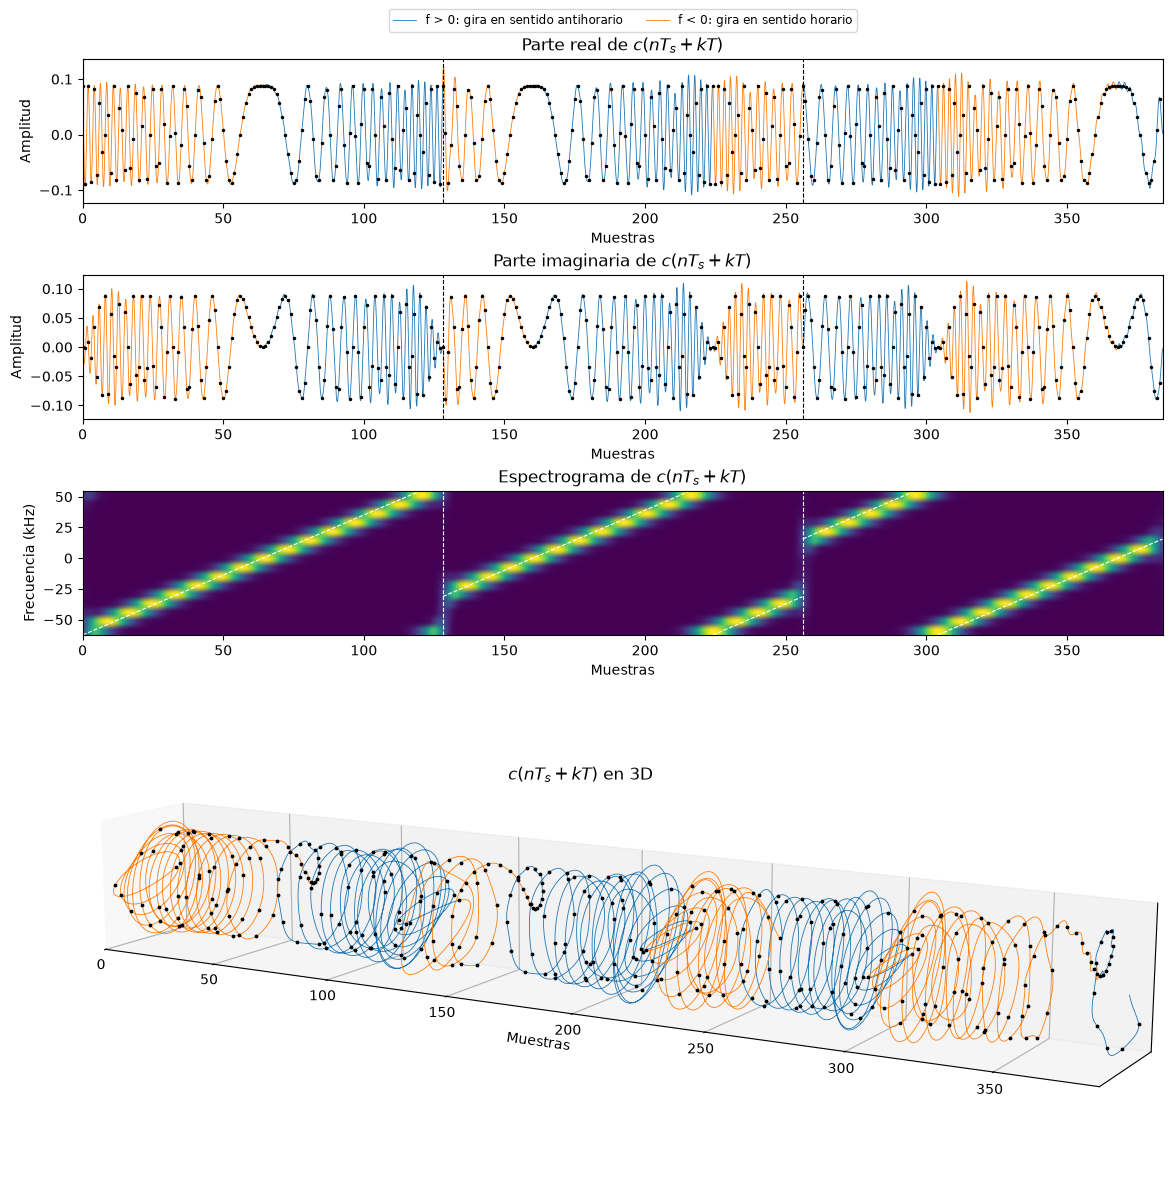

In [5]:
def frecuencia_instantanea(
    simbolos: np.ndarray, SF: int, B: float, puntos_por_chip: int = 1
) -> np.ndarray:
    """
    Calcula la frecuencia instantánea del chirp de cada símbolo, en la banda centrada.

    Parámetros:
        simbolos: Símbolos modulados.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        puntos_por_chip: Puntos por chip; con 1, la frecuencia de cada chip.

    Devuelve:
        La frecuencia, en Hz, entre -B/2 y B/2.
    """

    N = 2**SF
    k = np.arange(N * puntos_por_chip) / puntos_por_chip  # Tiempo dentro del símbolo, en chips

    frecuencia = []
    for s in simbolos:
        # La frecuencia f(k) sube de s B / 2^SF hasta B y vuelve a 0 (el mod). El (-1)^k del
        # conformador la corre -B/2: el chirp del símbolo 0 recorre la banda de -B/2 a B/2 sin saltar
        f = (s + k) / N % 1 * B
        frecuencia.append(f - B / 2)
    return np.concatenate(frecuencia)


def tramos_por_signo(f: np.ndarray) -> list[tuple[np.ndarray, str, str]]:
    """
    Parte una curva en dos tramos según el signo de su frecuencia.

    Parámetros:
        f: Frecuencia instantánea en cada punto de la curva.

    Devuelve:
        La máscara, el color y el nombre de cada tramo.
    """

    # Azul donde f > 0 (la señal gira en sentido antihorario) y naranja donde f < 0 (sentido
    # horario). Los tramos comparten el punto donde cambia el signo, para que la curva quede unida
    positiva = f >= 0
    return [
        (positiva | np.roll(positiva, 1), "C0", "f > 0: gira en sentido antihorario"),
        (~positiva | np.roll(~positiva, 1), "C1", "f < 0: gira en sentido horario"),
    ]


def graficar_3d(ax: Axes, x: np.ndarray, f: np.ndarray, titulo: str) -> None:
    """
    Dibuja una señal compleja en 3D: el tiempo en el eje largo, y la parte real y la imaginaria en
    los otros dos, sin rótulos.

    Parámetros:
        ax: Ejes 3D donde se dibuja.
        x: Muestras de la señal.
        f: Frecuencia instantánea, con PUNTOS_POR_CHIP puntos por chip.
        titulo: Título de los ejes.
    """

    # Los puntos son las muestras y la curva es la que reconstruiría un DAC ideal, en tramos según
    # el signo de f. Con clip_on=False, porque el zoom agranda el recuadro 3D más allá de los ejes
    # y las curvas se recortarían
    t, x_fino = reconstruir_como_dac(x)
    for tramo, color, nombre in tramos_por_signo(f):
        y = np.where(tramo, x_fino, np.nan)
        ax.plot(t, np.real(y), np.imag(y), color=color, lw=0.6, clip_on=False, label=nombre)
    k = np.arange(x.size)
    ax.scatter(k, np.real(x), np.imag(x), color="k", s=3, depthshade=False, clip_on=False)

    limite = 1.3 * np.max(np.abs(x))  # Un poco más que la amplitud
    ax.set(
        xlabel="Muestras",
        xlim=(0, x.size),
        ylim=(-limite, limite),
        zlim=(-limite, limite),
        yticks=[],
        zticks=[],
    )
    ax.set_box_aspect((8, 1, 1), zoom=2.2)  # Largo en el tiempo
    ax.xaxis.labelpad = 14  # Para que el rótulo no pise los números del eje
    ax.view_init(elev=12, azim=-60)
    ax.set_title(titulo, y=0.86)


def graficar_senal_modulada(simbolos: np.ndarray, SF: int, B: float):
    """
    Grafica la señal modulada: parte real, parte imaginaria, espectrograma y la señal compleja en 3D.

    Parámetros:
        simbolos: Símbolos a modular.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        La figura.
    """

    # Las curvas son la señal que reconstruiría un DAC ideal a partir de las muestras (los
    # puntos), con frecuencias entre -B/2 y B/2, en tramos según el signo de la frecuencia
    N = 2**SF
    c = conformador_de_onda(simbolos, SF, B)
    t, c_fino = reconstruir_como_dac(c)
    f = frecuencia_instantanea(simbolos, SF, B, PUNTOS_POR_CHIP)

    fig = plt.figure(figsize=(12, 12))
    ax_real = fig.add_axes((0.07, 0.8, 0.9, 0.12))
    ax_imag = fig.add_axes((0.07, 0.62, 0.9, 0.12))
    ax_espectro = fig.add_axes((0.07, 0.44, 0.9, 0.12))
    ax_3d = fig.add_axes((0, -0.02, 0.97, 0.42), projection="3d")

    # Parte real e imaginaria
    partes = [(ax_real, np.real, "Parte real"), (ax_imag, np.imag, "Parte imaginaria")]
    for ax, parte, titulo in partes:
        for tramo, color, nombre in tramos_por_signo(f):
            ax.plot(t, np.where(tramo, parte(c_fino), np.nan), color=color, lw=0.6, label=nombre)
        ax.plot(parte(c), "k.", ms=3)
        ax.set(title=f"{titulo} de $c(nT_s + kT)$", ylabel="Amplitud")
    ax_real.legend(loc="lower center", bbox_to_anchor=(0.5, 1.15), ncol=2, fontsize="small")

    # Espectrograma de c, en la misma banda que las curvas, con la frecuencia del chirp. La
    # línea se corta en los saltos de frecuencia, para no unirlos
    graficar_espectrograma(ax_espectro, c, B)
    saltos = np.abs(np.diff(f, prepend=f[0])) > B / N
    ax_espectro.plot(t, np.where(saltos, np.nan, f) / 1e3, "w--", lw=0.8)
    ax_espectro.set_ylim(ax_espectro.images[0].get_extent()[2:])  # Solo la banda de la imagen
    ax_espectro.set_title("Espectrograma de $c(nT_s + kT)$")

    for ax in (ax_real, ax_imag, ax_espectro):
        ax.set(xlabel="Muestras", xlim=(0, c.size))
        marcar_limites(ax, np.arange(len(simbolos) + 1) * N)

    graficar_3d(ax_3d, c, f, "$c(nT_s + kT)$ en 3D")
    return fig


graficar_senal_modulada(simbolos, SF, B);

## 3. Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### 3.1 Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas. A partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ _chips_ por cada símbolo enviado, el conformador de tuplas produce el arreglo de símbolos recibidos.

Antes de presentar el método formal de demodulación, Vangelista demuestra que el espacio vectorial de las $2^{SF}$ señales que el conformador genera (una por cada posible símbolo) es un espacio vectorial ortogonal.

El método de demodulación propuesto consiste en calcular la correlación cruzada de un tramo de $2^{SF}$ _chips_ de la señal recibida, correspondiente a la transmisión de un símbolo, con cada uno de los vectores de la base de este espacio vectorial (los posibles _chirps_). Puede también interpretarse como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{s(nT_s) = q}$ entre sí.

Dada la ortogonalidad del espacio vectorial, en ausencia de ruido la única correlación distinta de cero es la que corresponde al símbolo recibido, es decir, la correlación de la señal recibida con un _chirp_ idéntico a ella, que equivale a su autocorrelación.

Sobre este método, Vangelista desarrolla una forma computacionalmente más eficiente, descrita en la Ec. 16, que calcula todas las correlaciones cruzadas a la vez. Con el *chirp* de LoRa, el término $k^2$ del exponente de la Ec. 16 pasa a ser $k^2/2$, el término cuadrático de la fase de $c$ (ver *Anexo A*), y se agrega el $(-1)^k$ de la banda centrada:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j\pi \frac{k^2}{2^{SF}}}\,(-1)^k \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

La ecuación se puede reescribir como:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} d(nT_s + kT) \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, \mathrm{DFT}\left\{ d(nT_s + kT) \right\}[q]
$$

donde $d(nT_s + kT)$ es una exponencial compleja de frecuencia constante, $s(nT_s)\,B/2^{SF}$, proporcional al símbolo, cuando la señal recibida es un _chirp_ de LoRa:

$$
d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j\pi \frac{k^2}{2^{SF}}}\,(-1)^k = \frac{1}{\sqrt{2^{SF}}}\, e^{j2\pi \left(s(nT_s) + \frac{k}{2}\right) \frac{k}{2^{SF}}}\,(-1)^k\, e^{-j\pi \frac{k^2}{2^{SF}}}\,(-1)^k = \frac{1}{\sqrt{2^{SF}}}\, e^{j2\pi \frac{s(nT_s)\, k}{2^{SF}}}
$$

Al proceso de multiplicar la señal recibida por el término $e^{-j\pi \frac{k^2}{2^{SF}}}(-1)^k$, conocido como *down-chirp* porque es el conjugado del *chirp* del símbolo 0 y su frecuencia baja de $B/2$ a $-B/2$, se le llama _de-chirpeado_.

Luego, el paso restante es calcular la sumatoria, que es una Transformada Discreta de Fourier (DFT) y puede computarse mediante la Transformada Rápida de Fourier (FFT). Como $d(nT_s + kT)$ es una exponencial de frecuencia constante, su espectro es un impulso en el bin $q = s(nT_s)$. El demodulador decide entonces el símbolo como el índice del bin de mayor módulo, $\hat{s}(nT_s) = \arg\max_q |\langle r, c|_{s=q} \rangle|^2$, donde $|\langle r, c|_{s=q} \rangle|^2$ es el periodograma de $d(nT_s + kT)$, es decir, una estimación de su densidad espectral de potencia.

Por el teorema de Einstein-Wiener-Khinchin, la densidad espectral de potencia de una señal es la transformada de Fourier de su autocorrelación, lo que permite ver cómo se reparten la señal y el ruido entre los $2^{SF}$ bins. La autocorrelación de una exponencial compleja es otra exponencial de la misma frecuencia, por lo que la densidad espectral de $d(nT_s + kT)$ es un impulso y toda la energía del símbolo cae en el bin $q = s(nT_s)$.

El ruido blanco, por definición, tiene una densidad espectral plana y, por lo tanto, una autocorrelación impulsiva, así que su potencia se reparte en partes iguales entre los $2^{SF}$ bins del espectro. El *down-chirp* no altera esto, porque multiplicar el ruido blanco por una exponencial de módulo 1 no cambia su autocorrelación, y su densidad espectral sigue siendo plana. El _de-chirpeado_ concentra entonces la energía del símbolo en un solo bin mientras el ruido queda repartido en todos, lo que permite decidir correctamente aun cuando la potencia del ruido supera a la de la señal (ver *Transmisión en canal ruidoso*).

Este método asume que la demodulación está sincronizada, es decir, que el receptor ya detectó la trama y conoce dónde empieza cada símbolo, por lo que puede dividir la señal en tramos de $2^{SF}$ _chips_. El proceso de detección se detalla en *Detección de una trama*.

In [6]:
def down_chirp(SF: int) -> np.ndarray:
    """
    Genera el down-chirp del receptor, de módulo 1.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Los 2^SF chips del down-chirp.
    """

    # e^{-jπ k²/2^SF} (-1)^k: el conjugado del chirp del símbolo 0, con el mismo (-1)^k que el
    # conformador, así que al multiplicar los dos (-1)^k se cancelan
    N = 2**SF
    k = np.arange(N)
    return np.exp(-1j * np.pi * k**2 / N) * (-1.0) ** k


def dechirpear(recibido: np.ndarray, SF: int) -> np.ndarray:
    """
    Multiplica cada símbolo recibido por el down-chirp.

    Parámetros:
        recibido: Señal recibida; su largo tiene que ser múltiplo de 2^SF.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        d, con una fila por símbolo y una columna por chip.
    """

    N = 2**SF  # Chips por símbolo
    assert recibido.size % N == 0, "El número de muestras debe ser múltiplo de 2^SF"

    # Una fila por símbolo: d[n] son los N chips del símbolo n multiplicados por el down-chirp
    return recibido.reshape(-1, N) * down_chirp(SF)


def proyecciones(recibido: np.ndarray, SF: int) -> np.ndarray:
    """
    Calcula <r, c|s=q> para cada símbolo recibido y cada q (Ec. 16).

    Parámetros:
        recibido: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Una fila por símbolo y una columna por q.
    """

    # Ec. 16: <r, c|s=q> para cada símbolo n (filas) y cada q (columnas). Es la DFT de d dividida
    # por sqrt(2^SF), que es lo que calcula la FFT con norm="ortho"
    return np.fft.fft(dechirpear(recibido, SF), norm="ortho")


def demodulador(recibido: np.ndarray, SF: int) -> np.ndarray:
    """
    Decide cada símbolo recibido como el q de mayor |<r, c|s=q>|^2.

    Parámetros:
        recibido: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Los símbolos decididos.
    """

    # Decide cada símbolo como el q de mayor |<r, c|s=q>|^2, el periodograma de d
    periodograma = np.abs(proyecciones(recibido, SF)) ** 2
    return np.argmax(periodograma, axis=1)

### 3.2 Decodificación

Una vez generados por el conformador de tuplas, los símbolos recibidos son procesados por el decodificador, que descompone cada uno en un arreglo de $SF$ bits de acuerdo a la Ec. 1, el proceso inverso al descrito en *Codificador*.

In [7]:
def decodificador(simbolos: np.ndarray, SF: int) -> np.ndarray:
    """
    Convierte símbolos en bits: el proceso inverso de la Ec. 1.

    Parámetros:
        simbolos: Símbolos recibidos.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        SF bits por símbolo, del menos significativo al más significativo.
    """

    bits = []
    for s in simbolos:
        # Inverso de la Ec. 1: el bit h de s es el resto de dividir s // 2^h por 2
        for h in range(SF):
            bits.append((s // 2**h) % 2)
    return np.array(bits)

### 3.3 Visualización del proceso de decisión

Se sigue paso a paso la demodulación de un único símbolo para visualizar cómo el *down-chirp* y la FFT transforman la señal recibida utilizando $SF = 7$, con $2^{SF} = 128$ muestras por símbolo, y $B = 125$ kHz. Se elige el símbolo $s = 20$, distinto de 0 para que $d(nT_s + kT)$ oscile y el impulso no caiga en el bin 0. La figura muestra, de arriba hacia abajo:

1. La parte real y la parte imaginaria de la señal recibida $r(nT_s + kT)$, un *chirp* de LoRa.
2. El espectrograma de $r$ centrado en la banda $B$.
3. La parte real y la parte imaginaria de la señal de-chirpeada $d(nT_s + kT)$, que según *Demodulación* es una exponencial de frecuencia constante igual a $s$ oscilaciones por cada longitud $2^{SF}$ de símbolo.
4. El periodograma $|\langle r, c|_{s=q} \rangle|^2$ que calcula el demodulador, es decir, la estimación de la densidad espectral de potencia de $d$. El bin del símbolo transmitido se resalta en rojo y el del símbolo decidido $\hat{s}$ en azul, o en violeta cuando coinciden.

Una segunda figura muestra en tres dimensiones $r$, el *down-chirp* y su producto $d$, con los mismos ejes que en *Análisis de la señal modulada*.

In [8]:
def graficar_demodulacion(
    r: np.ndarray,
    s: int,
    SF: int,
    B: float,
    SNR_dB: float | None = None,
    h: np.ndarray | None = None,
):
    """
    Grafica la demodulación de un símbolo: r, su espectrograma, d y el periodograma.

    Parámetros:
        r: Un símbolo recibido, de 2^SF muestras.
        s: Símbolo transmitido.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR del canal para el título, o None.
        h: Respuesta al impulso del canal; None es el canal plano.

    Devuelve:
        La figura.
    """

    # De r y d se grafican la parte real y la imaginaria, con la curva que reconstruiría un DAC
    # ideal a partir de las muestras
    N = 2**SF
    if h is None:
        h = np.array([1.0])  # Canal plano: un solo camino, sin atenuación
    d = dechirpear(r, SF)[0]

    # Con eco se agrega, después de r, un gráfico de la amplitud de cada camino
    hay_eco = len(h) > 1
    n_graficos = 6 + hay_eco
    fig, axs = plt.subplots(n_graficos, 1, figsize=(10, 2.5 * n_graficos))
    ax_r_real, ax_r_imag = axs[0], axs[1]
    ax_espectro, ax_d_real, ax_d_imag, ax_P = axs[-4], axs[-3], axs[-2], axs[-1]

    graficar_real_e_imaginaria(ax_r_real, ax_r_imag, r, "$r(nT_s + kT)$")

    if hay_eco:
        ax_amp = axs[2]
        ax_amp.plot(np.abs(r), lw=0.8, label="$|r|$")
        ax_amp.plot(np.abs(r), "k.", ms=3)
        # Un solo rótulo para todos los ecos, para no repetirlo en la leyenda
        nombres = ["Camino directo", "Ecos" if len(h) > 2 else "Eco"]
        for i, h_i in enumerate(h):
            nombre = nombres[i] if i < 2 else None
            ax_amp.axhline(abs(h_i) / np.sqrt(N), color=f"C{i + 2}", ls="--", lw=1.2, label=nombre)
        # Lugar arriba de la curva para la leyenda
        ax_amp.set(
            title="Amplitud de $r(nT_s + kT)$ y de cada camino del canal",
            ylabel="Amplitud",
            ylim=(0, 1.35 * np.abs(h).sum() / np.sqrt(N)),
        )
        ax_amp.legend(loc="upper center", ncol=3, fontsize="small")

    # Espectrograma de r en la banda centrada, de -B/2 a B/2, la misma que la de las curvas
    graficar_espectrograma(ax_espectro, r, B)
    ax_espectro.set_title("Espectrograma de $r(nT_s + kT)$")

    graficar_real_e_imaginaria(ax_d_real, ax_d_imag, d, "$d(nT_s + kT)$")

    for ax in axs[:-1]:
        ax.set(xlabel="Muestras", xlim=(0, N))

    P = np.abs(proyecciones(r, SF)[0]) ** 2
    s_decidido = graficar_periodograma(ax_P, P, s, SF, B)
    ax_P.set_title(
        rf"Periodograma de $d$, $|\langle r, c|_{{s=q}} \rangle|^2$ (decidido ŝ={s_decidido})"
    )

    titulo = f"Símbolo transmitido s={s}"
    if SNR_dB is not None:
        titulo += f", SNR={SNR_dB} dB"
    fig.suptitle(titulo)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.3 / fig.get_figheight()))  # Lugar para el título
    return fig


def graficar_dechirpeo_3d(r: np.ndarray, s: int, SF: int, B: float):
    """
    Grafica en 3D r, el down-chirp y d = r · down-chirp de un símbolo.

    Parámetros:
        r: Un símbolo recibido sin ruido, de 2^SF muestras.
        s: Símbolo transmitido.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        La figura.
    """

    # El fasor de r cambia de velocidad y, al pasar B/2, de sentido de giro. El down-chirp gira con
    # la frecuencia opuesta a la del chirp del símbolo 0, así que al multiplicarlos se cancela la
    # rampa y queda d, una exponencial de frecuencia constante: un resorte de paso fijo
    N = 2**SF
    k = np.arange(N * PUNTOS_POR_CHIP) / PUNTOS_POR_CHIP  # Tiempo en chips
    f_d = s * B / N  # Frecuencia de d
    senales = [
        (
            r,
            frecuencia_instantanea(np.array([s]), SF, B, PUNTOS_POR_CHIP),
            "$r(nT_s + kT)$: el chirp",
        ),
        (down_chirp(SF), B / 2 - k * B / N, "down-chirp: la rampa opuesta"),  # De B/2 a -B/2
        (
            dechirpear(r, SF)[0],
            np.full(k.size, f_d - B if f_d >= B / 2 else f_d),  # En la banda centrada
            f"$d(nT_s + kT)$ = $r$ · down-chirp: un tono de {s} vueltas por símbolo",
        ),
    ]

    fig = plt.figure(figsize=(12, 10.5))
    for fila, (x, f, titulo) in enumerate(senales):
        ax = fig.add_axes((0, 2 / 3 - fila / 3, 0.97, 1 / 3), projection="3d")
        graficar_3d(ax, x, f, titulo)

    # Una sola leyenda, arriba de la figura
    fig.legend(*ax.get_legend_handles_labels(), loc="upper center", ncol=2, fontsize="small")
    return fig

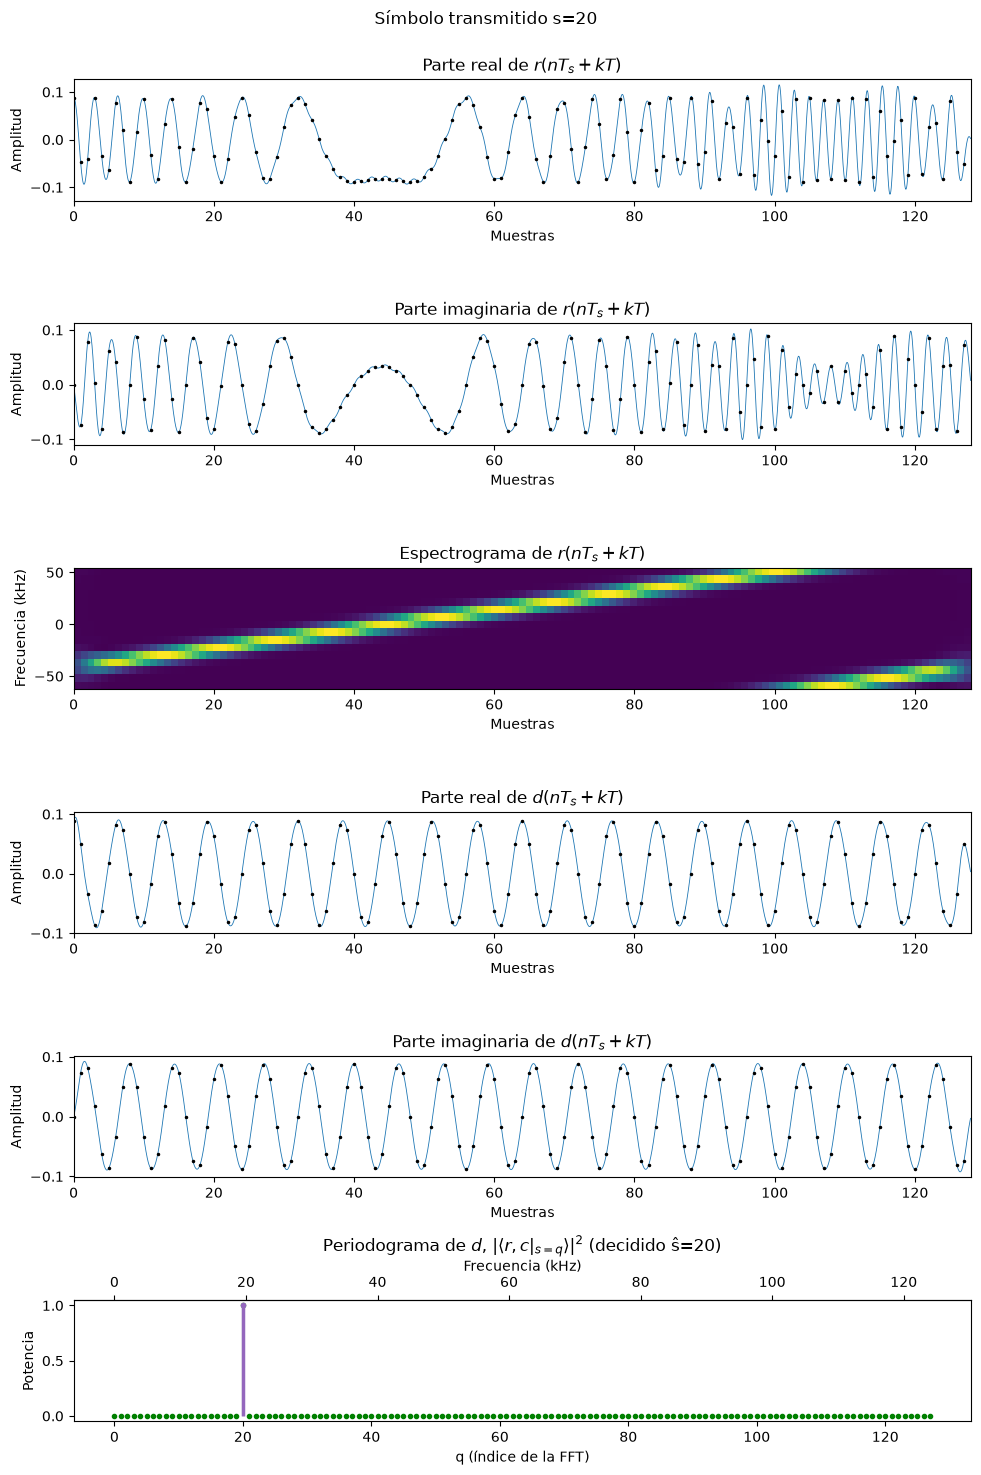

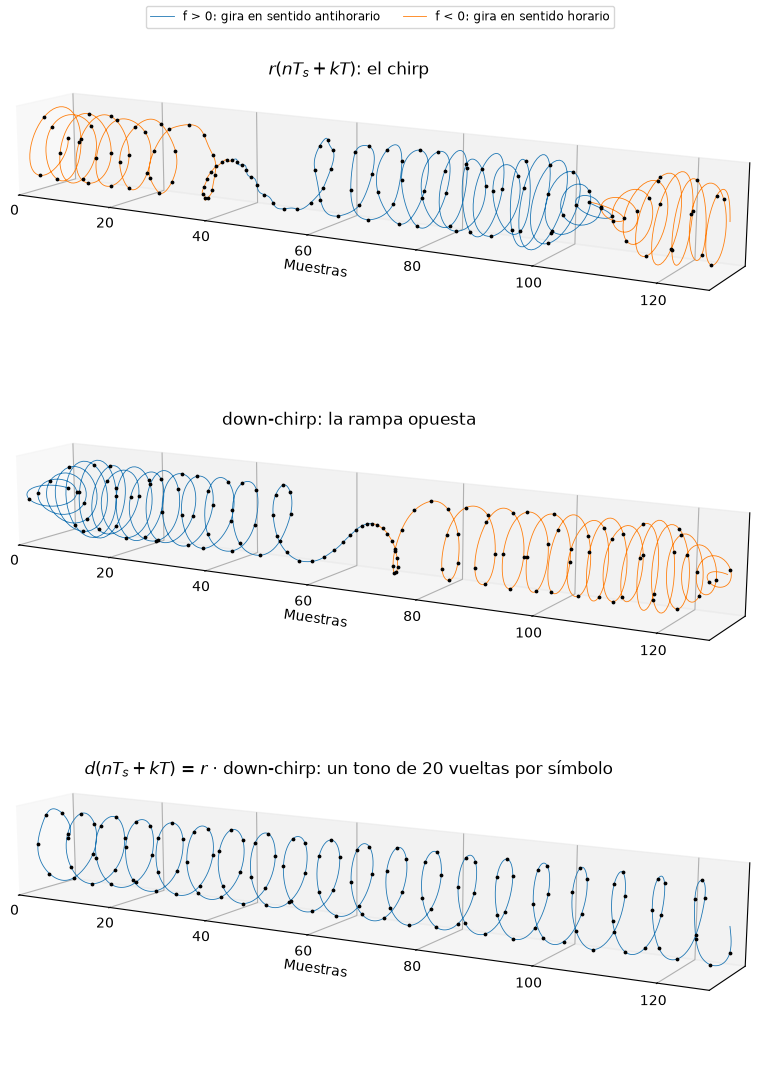

In [9]:
# Demodulación paso a paso de un símbolo sin ruido
s = 20
c_s = conformador_de_onda(np.array([s]), SF, B)

graficar_demodulacion(c_s, s, SF, B)
# r, el down-chirp y d en 3D: el down-chirp cancela la rampa del chirp y deja un tono
graficar_dechirpeo_3d(c_s, s, SF, B);

## 4. Modelo de canal ruidoso

Un canal introduce dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y retardos. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido. Se considera que el ruido será blanco gaussiano aditivo (AWGN) al simular la transmisión.

La señal recibida es $r = c * h + w$

![Diagrama de bloques del canal ruidoso](diagramas/canal.svg)

### 4.1 Cálculo del Bit Error Rate (BER)

Para medir el desempeño de la modulación/demodulación en un canal se utiliza el BER.

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

$$
BER = \frac{\text{cantidad de bits erróneos}}{\text{cantidad de bits transmitidos}}
$$

A continuación se simula una transmisión de $100$ símbolos con $SF=7$ (para un total de $7*100=700$ bits) en un canal ideal sin ruido, con un bit erróneo:

In [10]:
def BER(bits_tx: np.ndarray, bits_rx: np.ndarray) -> float:
    """
    Calcula la tasa de error de bits (BER): los bits errados sobre los bits enviados.

    Parámetros:
        bits_tx: Bits transmitidos.
        bits_rx: Bits recibidos, del mismo largo.

    Devuelve:
        El BER (Bit Error Rate).
    """

    assert bits_tx.size == bits_rx.size, "Los conjuntos de bits deben tener la misma longitud"
    errores = np.sum(bits_tx != bits_rx)  # Bits recibidos distintos de los transmitidos
    return errores / bits_tx.size


# Simular una transmisión completa de 100 símbolos aleatorios, sin ruido
bits_tx = rng.integers(0, 2, size=SF * 100)  # SF * 100 bits aleatorios, 0 o 1
senal = conformador_de_onda(codificador(bits_tx, SF), SF, B)
bits_rx = decodificador(demodulador(senal, SF), SF)
print(f"Bit Error Rate (BER): {BER(bits_tx, bits_rx):.4f}")

# En caso de corromper un bit:
bits_rx[3] ^= 1  # bit flip en el rx pos 3, para probar con un bit corrupto
print(f"Bit Error Rate (BER) con un bit corrupto: {BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


### 4.2 Potencia de la señal modulada

La potencia de una señal discreta es cuánta energía tiene, en promedio, cada muestra: el valor medio del módulo al cuadrado de sus muestras.

$$
P = \frac{1}{N} \sum_{n=0}^{N-1} |x[n]|^2
$$

El conformador de onda divide cada *chip* por $\sqrt{2^{SF}}$ para que cada símbolo tenga energía 1, sea cual sea el $SF$. La raíz aparece porque la energía suma los módulos al cuadrado. Si los $2^{SF}$ *chips* de un símbolo tienen el mismo módulo $a$, la energía del símbolo es $2^{SF} a^2$. Para que valga 1 hace falta $a^2 = 1/2^{SF}$, es decir, $a = 1/\sqrt{2^{SF}}$. Por ejemplo, con $SF = 2$ cada símbolo tiene 4 *chips* de módulo $1/2$, y su energía es $4 \cdot (1/2)^2 = 1$.

Al calcular la potencia, el cuadrado cancela la raíz: cada *chip* aporta $|c|^2 = 1/2^{SF}$. El *chirp* solo cambia la fase de cada *chip*, no su módulo, así que la potencia de la señal modulada es

$$
P_c = \frac{1}{2^{SF}}
$$

para cualquier símbolo. La celda siguiente la calcula con $SF = 7$ y con $SF = 2$.

In [11]:
def potencia(x: np.ndarray) -> float:
    """
    Potencia de una señal: el valor medio del módulo al cuadrado.

    Parámetros:
        x: Señal.

    Devuelve:
        La potencia.
    """

    return float(np.mean(np.abs(x) ** 2))


def ruido_awgn(c: np.ndarray, SNR_dB: float) -> np.ndarray:
    """
    Genera ruido blanco gaussiano complejo con el SNR pedido respecto de c.

    Parámetros:
        c: Señal de referencia; el ruido tiene su misma forma.
        SNR_dB: SNR, en dB.

    Devuelve:
        El ruido.
    """

    SNR = 10 ** (SNR_dB / 10)
    varianza = potencia(c) / SNR  # sigma_w^2

    # Parte real e imaginaria independientes, cada una con la mitad de la varianza
    sigma = np.sqrt(varianza / 2)
    return rng.normal(0, sigma, c.shape) + 1j * rng.normal(0, sigma, c.shape)

In [12]:
for sf in [7, 2]:
    P_c = potencia(conformador_de_onda(np.array([0]), sf, B))
    print(f"Potencia de la señal modulada con SF={sf}, B={B / 1e3:.0f} kHz: {P_c:.4f}")

Potencia de la señal modulada con SF=7, B=125 kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125 kHz: 0.2500


### 4.3 Relación señal-ruido (SNR)

El ruido $w$ de la Ec. 10 es gaussiano complejo, de media nula y con la misma varianza $\sigma_w^2$ en todas las muestras. La relación señal-ruido (SNR) se define por muestra como el cociente entre la potencia de la señal y la del ruido:

$$
SNR = \frac{P_c}{\sigma_w^2}, \qquad SNR_{dB} = 10 \log_{10} SNR
$$

Para simular un SNR dado, primero se calcula la potencia de la señal transmitida $P_c$, que depende de $SF$, y con ella la varianza del ruido, $\sigma_w^2 = P_c / SNR$. Después se generan la parte real y la imaginaria del ruido como dos variables gaussianas independientes, cada una con varianza $\sigma_w^2 / 2$, para que la potencia total del ruido sea $\sigma_w^2$. Un SNR negativo en dB significa que el ruido tiene más potencia que la señal.

A continuación se genera ruido con un SNR de $-10$ dB sobre una señal de tres símbolos y se mide el SNR que resulta de la simulación.

In [13]:
# Ruido con SNR de -10 dB sobre la señal de los tres símbolos, sin alterar los valores aleatorios
# de las secciones siguientes
SNR_dB = -10
with rng_aislado():
    z = ruido_awgn(c, SNR_dB)

SNR_medido_dB = 10 * np.log10(potencia(c) / potencia(z))
print(f"Potencia de la señal: {potencia(c):.4f}, potencia del ruido: {potencia(z):.4f}")
print(f"SNR pedido: {SNR_dB} dB, SNR medido: {SNR_medido_dB:.2f} dB")

Potencia de la señal: 0.0078, potencia del ruido: 0.0743
SNR pedido: -10 dB, SNR medido: -9.78 dB


### 4.4 Recepción con ruido

Se repite la demodulación paso a paso de *Visualización del proceso de decisión*, sumándole al mismo símbolo ruido blanco gaussiano con un SNR de $-3$ dB, es decir, con el doble de la potencia de la señal ($10^{-3/10} \approx 0.50$).

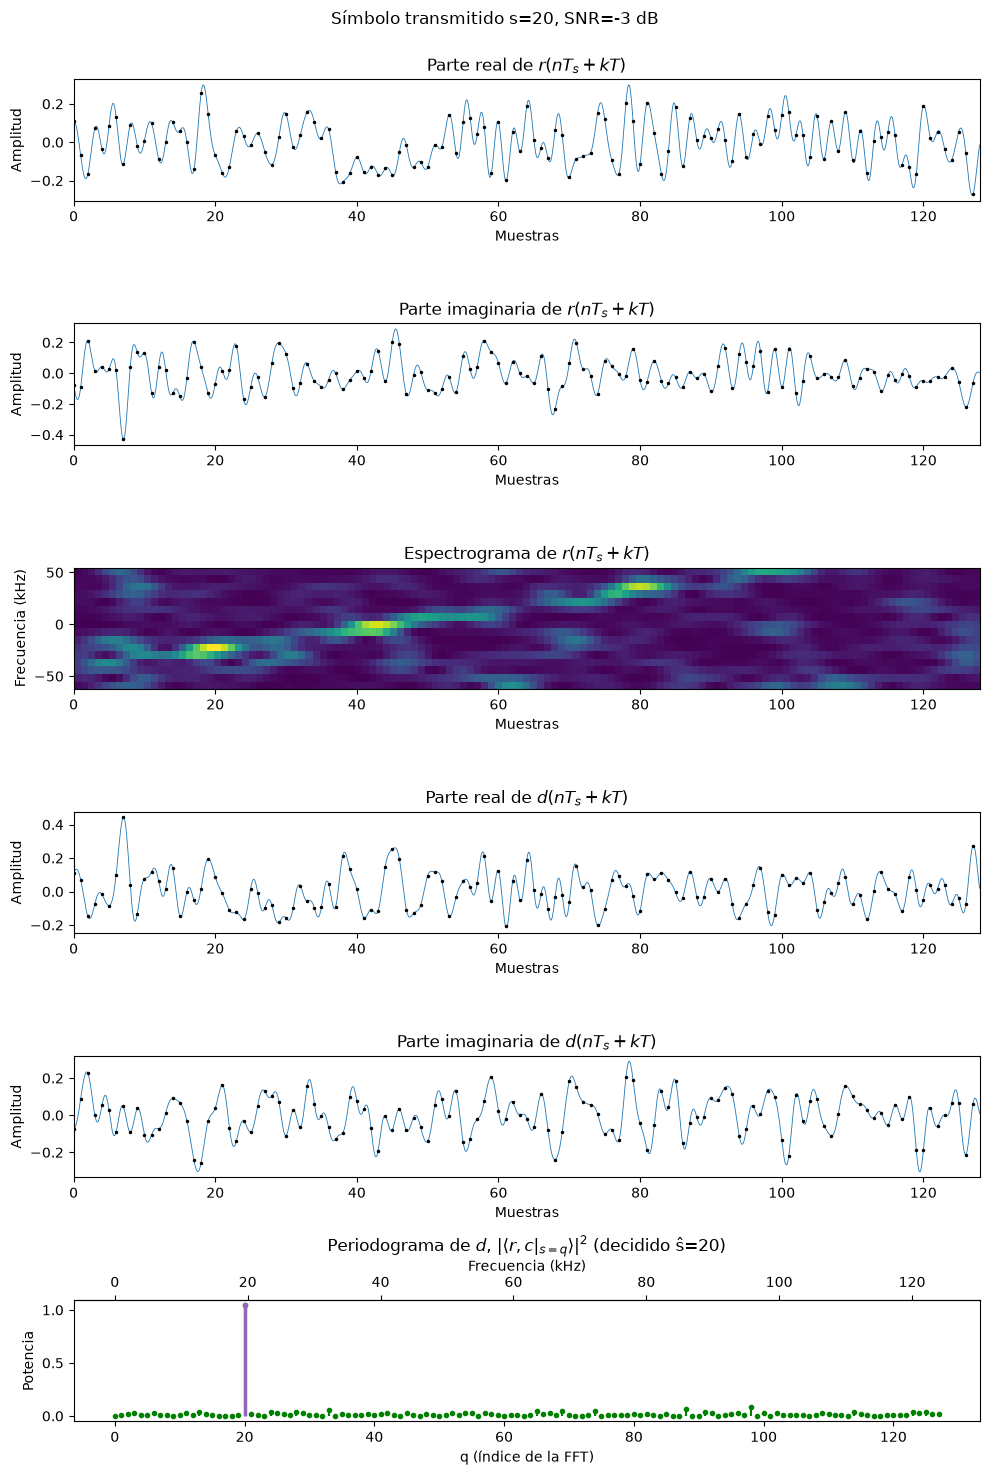

In [14]:
# Demodulación paso a paso del mismo símbolo con ruido, sin alterar los valores aleatorios de las
# secciones siguientes
SNR_dB = -3
with rng_aislado():
    recibido = c_s + ruido_awgn(c_s, SNR_dB)  # Canal plano: solo se suma el ruido

graficar_demodulacion(recibido, s, SF, B, SNR_dB);

### 4.5 Transmisión en canal ruidoso

Un canal es plano cuando su respuesta en frecuencia es constante en toda la banda de la señal, de modo que todas las frecuencias del *chirp* llegan con la misma ganancia y el mismo retardo y la forma de la señal no cambia. En el modelo $r = c * h + w$ corresponde a $h[n] = \delta[n]$, y la señal recibida es la señal transmitida más el ruido, $r = c + w$.

![Respuesta al impulso del canal plano](diagramas/canal_h_plano.svg)

Se repite la transmisión de 100 símbolos ($SF = 7$, 700 bits) de *Cálculo del Bit Error Rate (BER)*, ahora por el canal plano con un SNR de $-10$ dB.

In [15]:
CANAL_PLANO = np.array([1.0])  # h[n] = δ[n]: el canal no distorsiona la señal, solo se suma ruido


def canal(c: np.ndarray, h: np.ndarray, w: np.ndarray | float) -> np.ndarray:
    """
    Pasa la señal por el canal: r = c * h + w.

    Parámetros:
        c: Señal transmitida.
        h: Respuesta al impulso del canal.
        w: Ruido, del largo de c, o 0 para un canal sin ruido.

    Devuelve:
        La señal recibida, del mismo largo que c.
    """

    # r = c * h + w: convolución causal con la respuesta al impulso, r[n] = sum_l h[l] c[n - l],
    # más el ruido. Se descartan las últimas L - 1 muestras para que r tenga el largo de c.
    return np.convolve(c, h)[: c.size] + w


@cache
def tabla_de_chirps(SF: int, B: float) -> list[np.ndarray]:
    """
    Calcula una sola vez, con conformador_de_onda, el chirp de cada símbolo.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Lista con el chirp de cada símbolo q = 0, ..., 2^SF - 1.
    """

    # @cache guarda el resultado de cada SF y B. Las simulaciones transmiten miles de símbolos:
    # concatenar estos chirps da la misma señal que conformador_de_onda, mucho más rápido
    return [conformador_de_onda(np.array([q]), SF, B) for q in range(2**SF)]


def transmitir_bits(
    SF: int,
    B: float,
    SNR_dB: float,
    h: np.ndarray,
    n_simbolos: int = 100,
    conformar=None,
    demodular=demodulador,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Transmite bits aleatorios por un canal con ruido y los recibe.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.
        h: Respuesta al impulso del canal.
        n_simbolos: Símbolos transmitidos.
        conformar: Función que recibe los símbolos y devuelve la señal modulada; None usa el chirp
            de LoRa.
        demodular: Función que recibe la señal recibida y SF, y devuelve los símbolos.

    Devuelve:
        Los bits transmitidos y los recibidos.
    """

    bits_tx = rng.integers(0, 2, size=SF * n_simbolos)
    simbolos = codificador(bits_tx, SF)
    if conformar is None:
        chirps = tabla_de_chirps(SF, B)
        c = np.concatenate([chirps[s] for s in simbolos])
    else:
        c = conformar(simbolos)
    r = canal(c, h, ruido_awgn(c, SNR_dB))
    return bits_tx, decodificador(demodular(r, SF), SF)


# Transmisión de 100 símbolos aleatorios por un canal plano
SNR_dB = -10
bits_tx, bits_rx = transmitir_bits(SF, B, SNR_dB, CANAL_PLANO)
ber = BER(bits_tx, bits_rx)
# Como Markdown, con un título ###, para que el resultado se vea grande
display(Markdown(f"### Bit Error Rate (BER) con SNR = {SNR_dB} dB: {ber:.4f}"))

### Bit Error Rate (BER) con SNR = -10 dB: 0.0057

**Observaciones**:
- Con un ruido 10 veces más potente que la señal, solo 4 de los 700 bits son erróneos (BER $\approx 0.006$), porque la multiplicación por el *down-chirp* concentra la energía del símbolo en un bin del periodograma, mientras que la del ruido se reparte entre los $2^{SF}$ bins.

### 4.6 Canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia o multicaminos. La respuesta al impulso del sistema usado por Vangelista para medir el rendimiento del demodulador es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$

![Respuesta al impulso del canal selectivo en frecuencia](diagramas/canal_h_selectivo.svg)

Cada *chirp* recibido es la suma del *chirp* transmitido con amplitud $\sqrt{0.8}$ y de un eco retrasado una muestra, con amplitud $\sqrt{0.2}$.

#### 4.6.1 Recepción sin ruido

Se repite, a través de este canal y sin ruido, la demodulación paso a paso del símbolo $s = 20$ con $SF = 7$. Respecto de la figura del canal plano se agrega, debajo de $r$, un gráfico de la amplitud $|r|$ junto con la amplitud constante de cada camino, $\sqrt{0.8}/\sqrt{2^{SF}} \approx 0.079$ para el directo y $\sqrt{0.2}/\sqrt{2^{SF}} \approx 0.040$ para el eco.

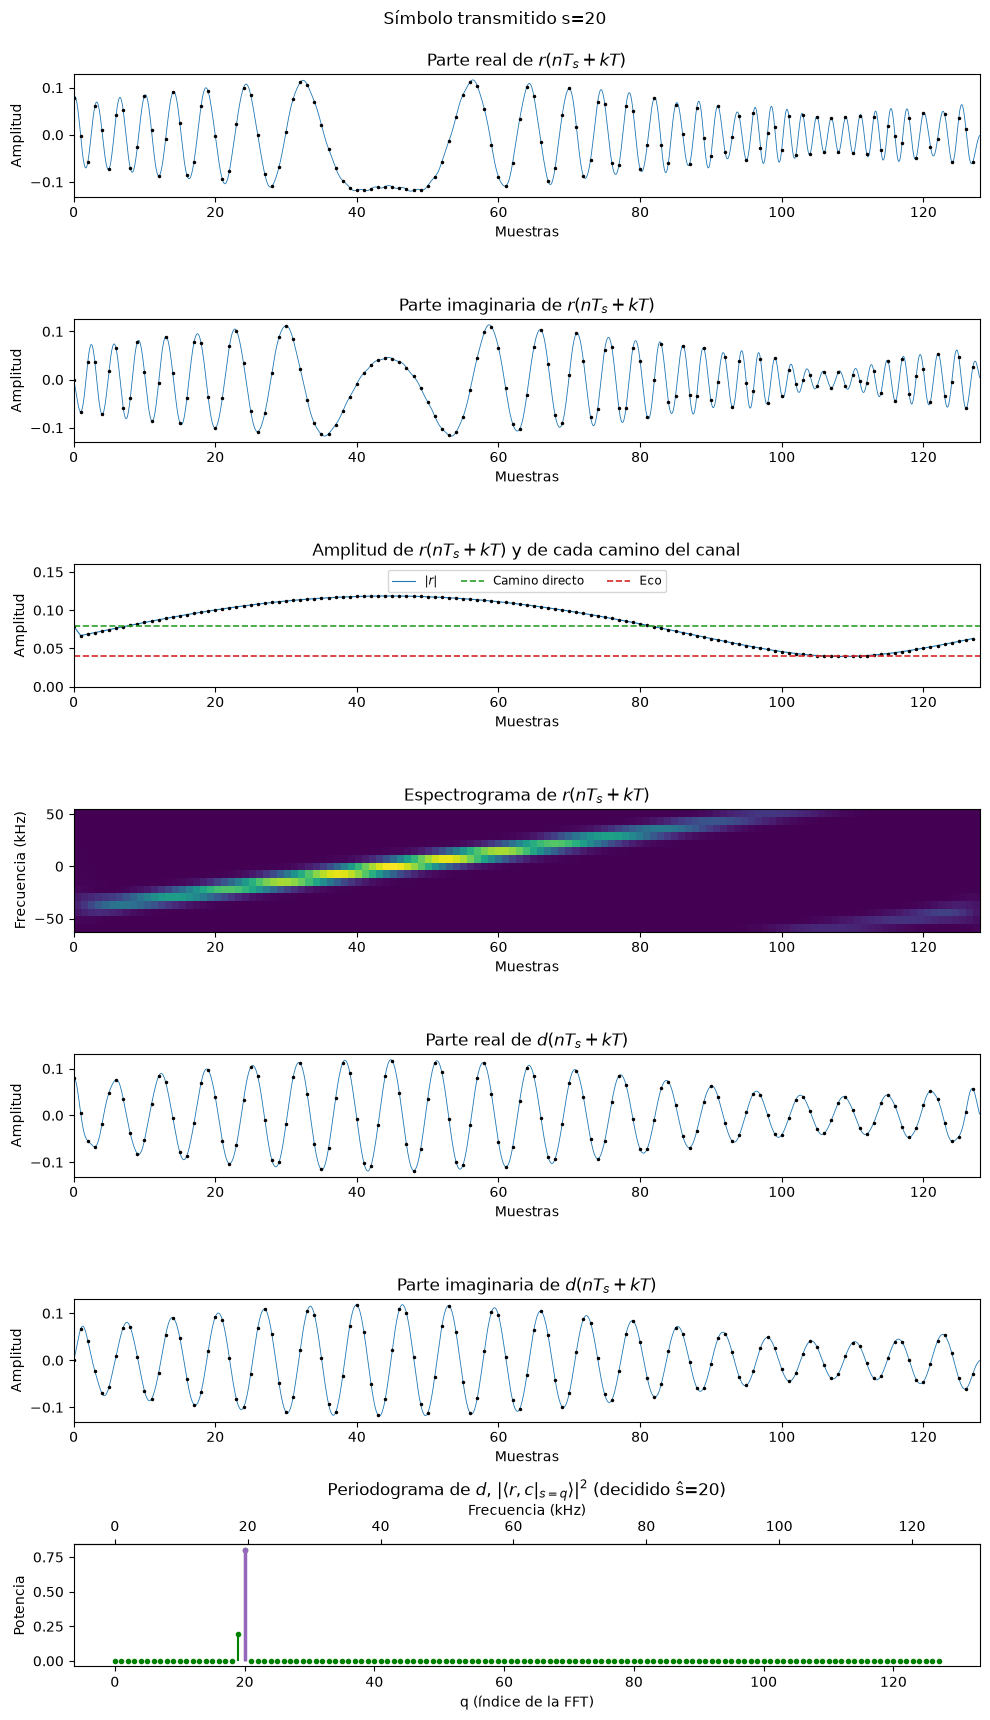

In [16]:
# Canal selectivo en frecuencia: h[n] = sqrt(0.8) δ[n] + sqrt(0.2) δ[n-1]
CANAL_SELECTIVO = np.array([np.sqrt(0.8), np.sqrt(0.2)])

# Demodulación paso a paso del mismo símbolo por el canal selectivo en frecuencia, sin ruido
r = canal(c_s, CANAL_SELECTIVO, 0)

graficar_demodulacion(r, s, SF, B, h=CANAL_SELECTIVO);

#### 4.6.2 Límite de decisión

Para ver cómo el canal afecta la decisión, los símbolos 0, 32 y 80 se transmiten por el canal plano y por el selectivo con el mismo ruido, a un SNR de $-10$ dB, de modo que la única diferencia entre ambos sea el canal. La figura muestra el periodograma de cada símbolo, con el canal plano a la izquierda y el selectivo a la derecha, y la misma escala vertical en cada fila. El bin del símbolo transmitido se marca en rojo y el del símbolo decidido en azul, o en violeta cuando coinciden.

In [17]:
def graficar_decision(
    proyecciones_por_canal: dict[str, np.ndarray],
    simbolos_tx: np.ndarray,
    SF: int,
    B: float,
    SNR_dB: float | None = None,
):
    """
    Grafica el periodograma de cada símbolo recibido, con una columna por canal.

    Parámetros:
        proyecciones_por_canal: Proyecciones <r, c|s=q> de cada símbolo, por nombre del canal.
        simbolos_tx: Símbolos transmitidos.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR del canal para el título, o None.

    Devuelve:
        La figura.
    """

    # Cada periodograma como en graficar_demodulacion
    n_filas, n_columnas = len(simbolos_tx), len(proyecciones_por_canal)
    ancho = 10 if n_columnas == 1 else 7 * n_columnas

    # Misma escala en cada fila para comparar los canales
    fig, axs = plt.subplots(
        n_filas, n_columnas, figsize=(ancho, 3 * n_filas), squeeze=False, sharey="row"
    )
    for j, (nombre, proyecciones_canal) in enumerate(proyecciones_por_canal.items()):
        for i, s in enumerate(simbolos_tx):
            P = np.abs(proyecciones_canal[i]) ** 2
            s_decidido = graficar_periodograma(axs[i, j], P, s, SF, B)
            axs[i, j].set_title(
                f"{nombre}, símbolo n={i}: transmitido s={s}, decidido ŝ={s_decidido}"
            )

    if SNR_dB is not None:
        fig.suptitle(f"SNR={SNR_dB} dB")
    fig.tight_layout()
    return fig

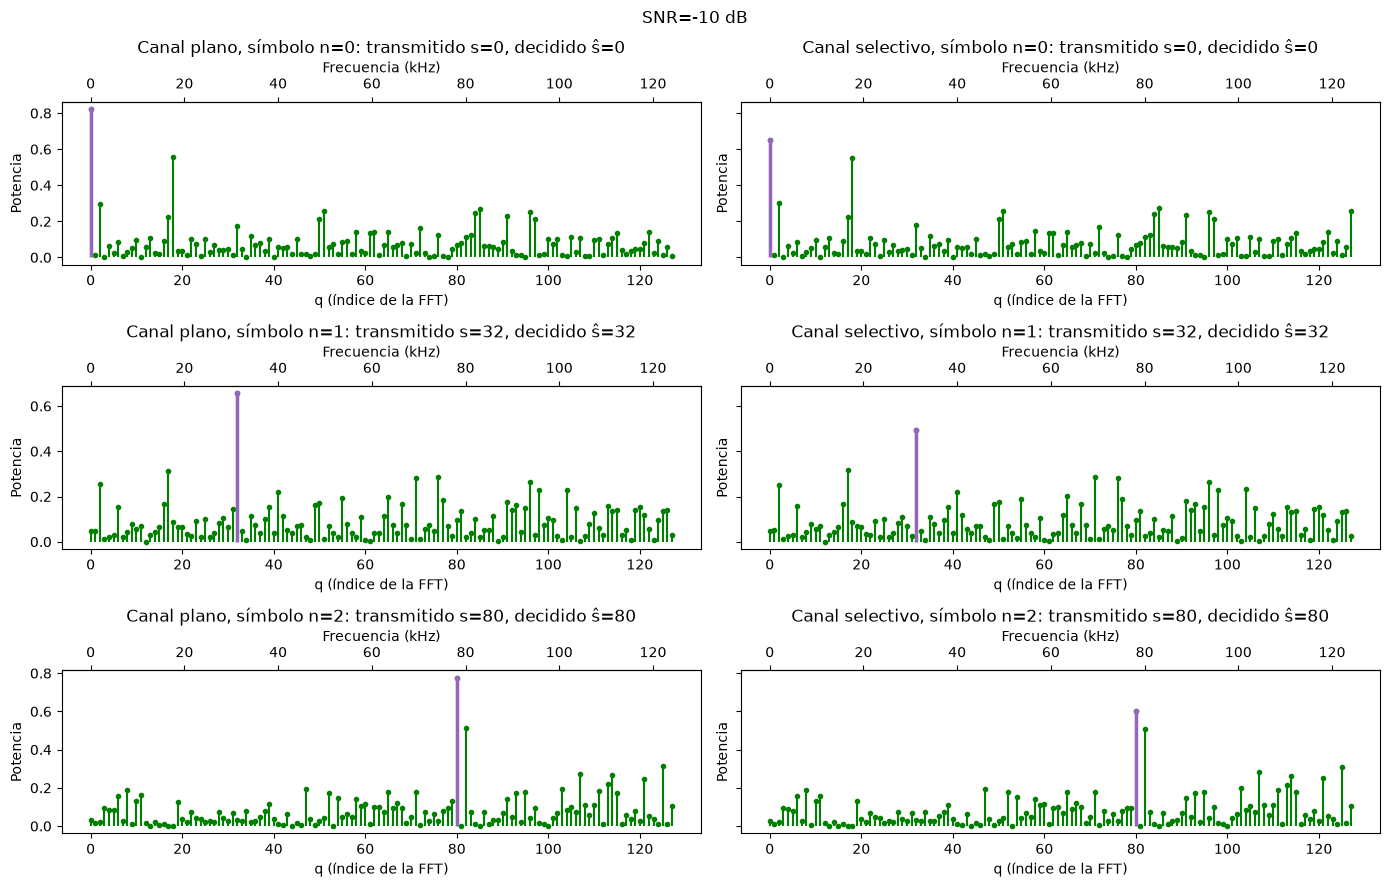

In [18]:
# Los tres símbolos por los dos canales, con el mismo ruido, a un SNR de -10 dB
SNR_dB = -10
c = conformador_de_onda(simbolos, SF, B)
w = ruido_awgn(c, SNR_dB)
proyecciones_por_canal = {
    "Canal plano": proyecciones(canal(c, CANAL_PLANO, w), SF),
    "Canal selectivo": proyecciones(canal(c, CANAL_SELECTIVO, w), SF),
}

graficar_decision(proyecciones_por_canal, simbolos, SF, B, SNR_dB);

**Observaciones**:
- Los tres símbolos se deciden correctamente en los dos canales, pero en el selectivo el bin del símbolo baja, por ejemplo de $\approx 0.82$ a $\approx 0.65$ en el símbolo 0, porque el camino directo lleva solo el 80 % de la potencia.
- El 20 % restante llega con el eco, que es el *chirp* retrasado una muestra. En cada *chip* el eco tiene la frecuencia que el *chirp* del símbolo $s - 1$ tiene en ese *chip*, así que su potencia cae en el bin $q = s - 1$. Se ve en el símbolo 0, donde el bin 127 sube a $\approx 0.26$.
- Los bins de solo ruido no cambian, así que el margen de la decisión se achica. En el símbolo 80 el bin del símbolo queda en $\approx 0.60$ contra $\approx 0.51$ del bin 82, cuando en el canal plano le sacaba $\approx 0.26$ de ventaja.

### 4.7 Canal exponencial

En el canal selectivo el 80 % de la energía llega por el camino directo. Para estudiar canales en los que la energía se reparte entre más caminos se usa una respuesta al impulso que decae exponencialmente:

$$
h[n] = A\, e^{-\alpha n}, \qquad n = 0, \dots, L - 1
$$

donde $\alpha$ fija qué tan rápido decae la amplitud de los caminos retrasados y $A$ normaliza la energía, $\sum_n h^2[n] = 1$, como en los otros dos canales, para que el canal no cambie la potencia de la señal ni el SNR. Se usan dos canales:

- $\alpha = 0.5$ con $L = 8$ caminos: el camino directo lleva el 63 % de la energía, cerca del canal selectivo.
- $\alpha = 0.1$ con $L = 16$ caminos: el directo lleva el 19 % y el resto se reparte entre los caminos retrasados.

Se repite, a través del canal con $\alpha = 0.5$ y sin ruido, la demodulación paso a paso del símbolo $s = 20$.

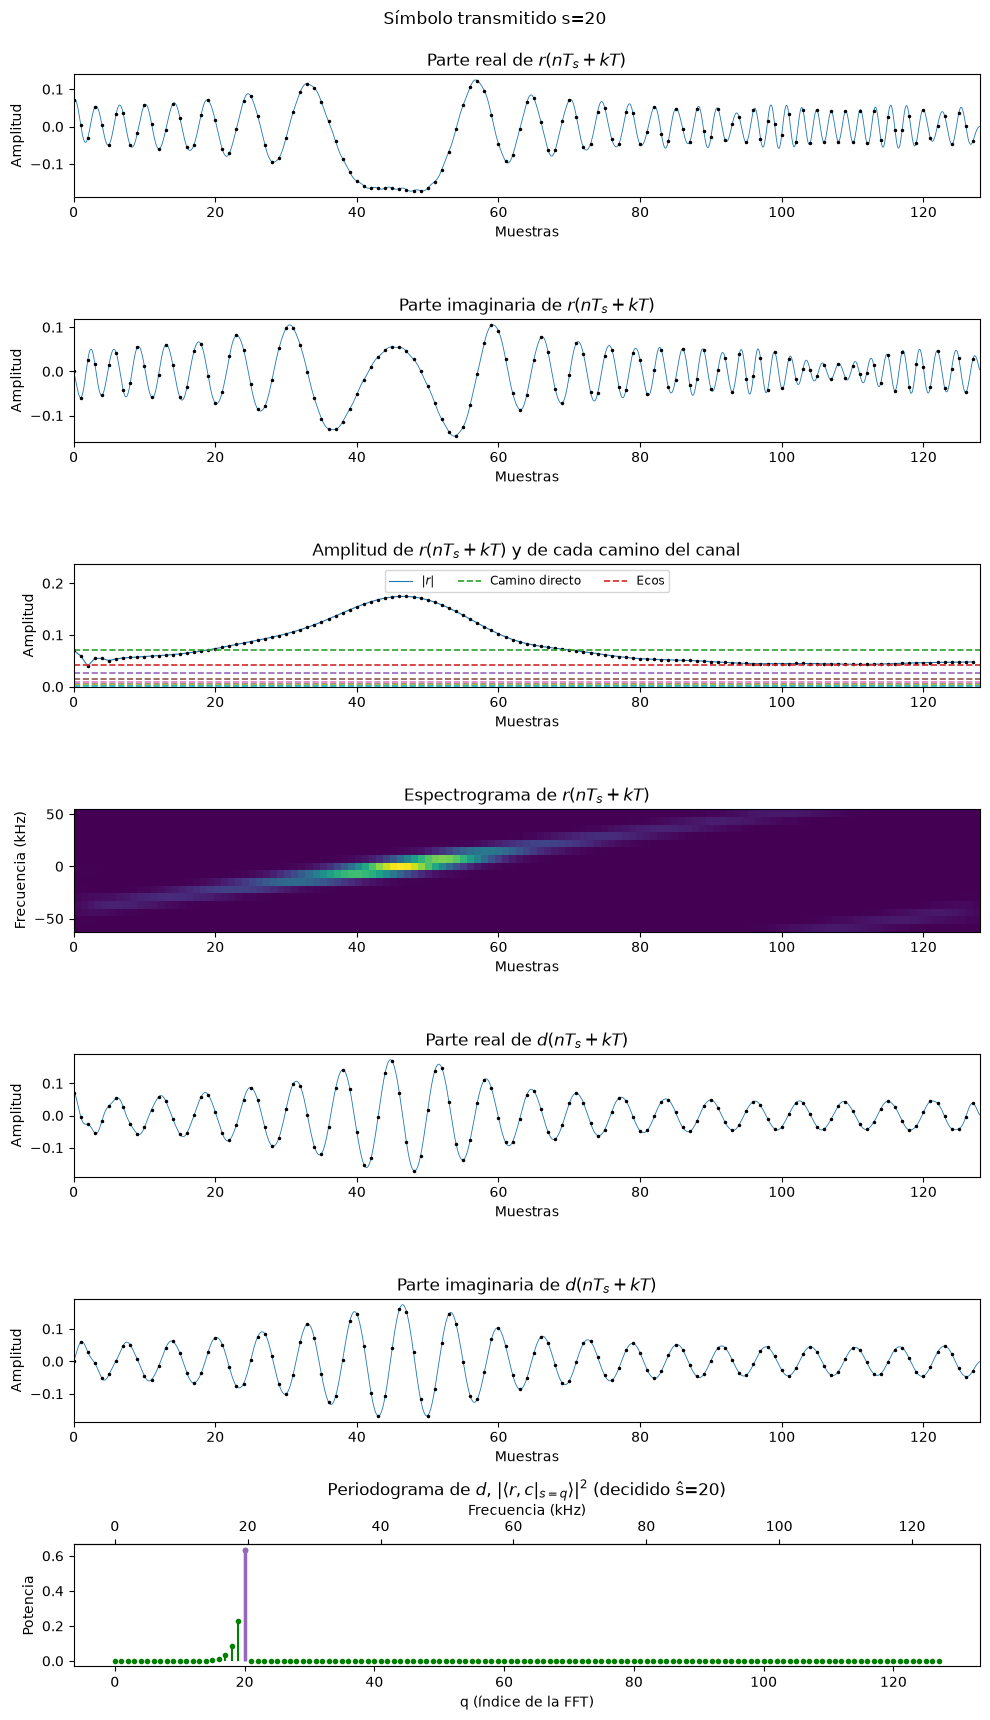

In [19]:
def canal_exponencial(alfa: float, L: int) -> np.ndarray:
    """
    Respuesta al impulso exponencial de L caminos: h[n] = A e^{-alfa n}.

    Parámetros:
        alfa: Tasa de caída por muestra. Cuanto menor, más se reparte la energía entre los caminos.
        L: Cantidad de caminos.

    Devuelve:
        h[n] para n = 0, ..., L - 1, con energía 1.
    """

    # h[n] = e^{-alfa n}, normalizada a energía 1 (sum h^2 = 1) como CANAL_PLANO y CANAL_SELECTIVO,
    # para que el canal no cambie la potencia de la señal ni el SNR
    h = np.exp(-alfa * np.arange(L))
    return h / np.sqrt(np.sum(h**2))


CANAL_EXP_RAPIDO = canal_exponencial(0.5, 8)  # El camino directo lleva el 63 % de la energía
CANAL_EXP_LENTO = canal_exponencial(0.1, 16)  # El camino directo lleva el 19 %

# Demodulación paso a paso del mismo símbolo por el canal exponencial con alfa = 0.5, sin ruido
r = canal(c_s, CANAL_EXP_RAPIDO, 0)

graficar_demodulacion(r, s, SF, B, h=CANAL_EXP_RAPIDO);

**Observaciones**:
- El periodograma muestra la respuesta al impulso del canal. El camino retrasado $l$ muestras cae en el bin $s - l$ con su potencia $h^2[l]$, que es 0.63 en el bin 20, 0.23 en el 19 y 0.09 en el 18. La decisión es correcta, pero el bin del símbolo conserva solo el 63 % de la potencia, contra el 80 % del canal selectivo.

### 4.8 BER en función del SNR

Se simula el BER en función del SNR en los cuatro canales con $SF = 7$, para SNR entre $-12$ y $-6$ dB. Se espera que las curvas del canal plano y del selectivo reproduzcan las curvas "Flat FSCM" y "Freq. sel. FSCM" de la Fig. 1. del paper, que se calculan con la Ec. 2 pero valen también para el *chirp* de LoRa (ver *Anexo A*). Las de los canales exponenciales extienden la comparación a canales con más caminos.

El BER de cada SNR se estima por Monte Carlo, como la fracción de bits errados en transmisiones de 100 símbolos. La estimación es confiable si junta al menos 100 errores, porque con $k$ errores su desvío relativo es de aproximadamente $1/\sqrt{k}$, un 10 % con 100. Por eso cada SNR simula al menos 500 transmisiones ($3.5 \cdot 10^5$ bits) y después sigue hasta juntar 100 bits errados. Para acotar el tiempo de ejecución se corta en $2 \cdot 10^4$ transmisiones ($1.4 \cdot 10^7$ bits), así que el menor BER que se estima con 100 errores es $\approx 7 \cdot 10^{-6}$. Los puntos que llegan a ese tope con menos errores se dibujan huecos, y los que no tienen errores no entran en la escala logarítmica. El segmento vertical de cada punto es su intervalo de confianza del 95 %, el rango de valores del BER compatibles con los errores contados, calculado con la aproximación gaussiana de la cantidad de errores.

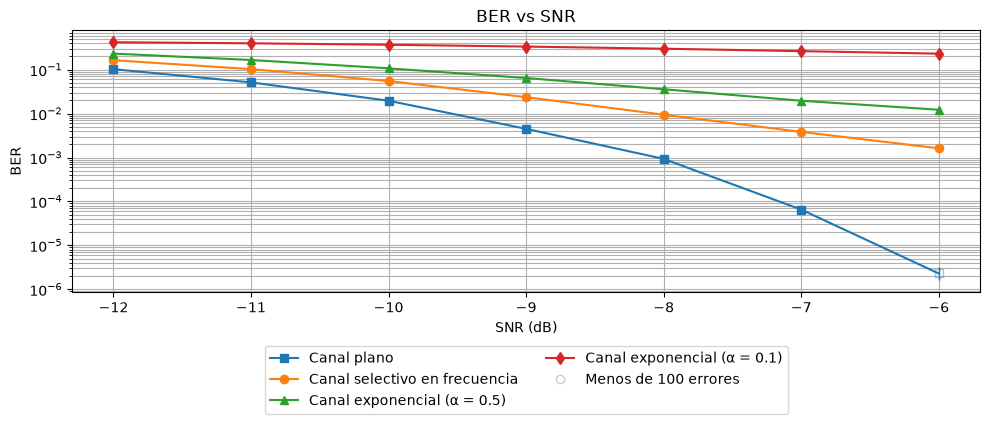

In [20]:
def ber_vs_snr(
    SF: int,
    B: float,
    SNRs_dB: np.ndarray,
    h: np.ndarray,
    min_transmisiones: int,
    max_transmisiones: int,
    min_errores: int = 100,
    n_simbolos: int = 100,
    conformar=None,
    demodular=demodulador,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Estima el BER para cada SNR.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNRs_dB: SNR a simular, en dB.
        h: Respuesta al impulso del canal.
        min_transmisiones: Transmisiones mínimas por SNR.
        max_transmisiones: Transmisiones máximas por SNR.
        min_errores: Bits errados con los que se deja de simular cada SNR.
        n_simbolos: Símbolos por transmisión.
        conformar: Conformador de onda, como en transmitir_bits.
        demodular: Demodulador, como en transmitir_bits.

    Devuelve:
        Los bits errados y los bits transmitidos en cada SNR.
    """

    # El BER es el cociente entre los bits errados y los transmitidos. Se simulan al menos
    # min_transmisiones y después se sigue hasta juntar min_errores bits errados o llegar a
    # max_transmisiones: donde el BER es bajo hacen falta más transmisiones para estimarlo
    errores_por_snr, bits_por_snr = [], []
    for SNR_dB in SNRs_dB:
        transmisiones = errores = 0
        while transmisiones < min_transmisiones or (
            errores < min_errores and transmisiones < max_transmisiones
        ):
            bits_tx, bits_rx = transmitir_bits(SF, B, SNR_dB, h, n_simbolos, conformar, demodular)
            errores += np.sum(bits_tx != bits_rx)
            transmisiones += 1
        errores_por_snr.append(errores)
        bits_por_snr.append(transmisiones * SF * n_simbolos)
    return np.array(errores_por_snr), np.array(bits_por_snr)


def graficar_ber_vs_snr(SNRs_dB: np.ndarray, bers: dict[str, tuple[np.ndarray, np.ndarray]]):
    """
    Grafica el BER vs SNR, una curva por canal.

    Parámetros:
        SNRs_dB: SNR simulados, en dB.
        bers: Bits errados y bits transmitidos en cada SNR (ber_vs_snr), por nombre de la curva.

    Devuelve:
        La figura.
    """

    fig, ax = plt.subplots(figsize=(10, 4.5))
    for (nombre, (errores, bits)), marcador in zip(bers.items(), ["s", "o", "^", "d", "v"]):
        graficar_tasa_de_error(ax, SNRs_dB, errores, bits, marcador, label=nombre)
    leyenda_puntos_huecos(ax)
    ax.set_yscale("log", nonpositive="mask")
    ax.set(title="BER vs SNR", xlabel="SNR (dB)", ylabel="BER")
    ax.grid(True, which="both")
    # Debajo del gráfico, para no tapar las curvas
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
    fig.tight_layout()
    return fig


SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -6 dB
# Transmisiones de 100 símbolos por SNR: al menos 500, y después hasta juntar 100 bits errados
min_tx, max_tx = 500, 20_000

bers = {
    "Canal plano": ber_vs_snr(SF, B, SNRs_dB, CANAL_PLANO, min_tx, max_tx),
    "Canal selectivo en frecuencia": ber_vs_snr(SF, B, SNRs_dB, CANAL_SELECTIVO, min_tx, max_tx),
}
# Los canales exponenciales, sin alterar los valores aleatorios de las secciones siguientes
with rng_aislado():
    bers["Canal exponencial (α = 0.5)"] = ber_vs_snr(
        SF, B, SNRs_dB, CANAL_EXP_RAPIDO, min_tx, max_tx
    )
    bers["Canal exponencial (α = 0.1)"] = ber_vs_snr(
        SF, B, SNRs_dB, CANAL_EXP_LENTO, min_tx, max_tx
    )
graficar_ber_vs_snr(SNRs_dB, bers);

Para ver por qué crece la diferencia entre el canal plano y el selectivo, se cuenta en el canal selectivo qué símbolo decide el demodulador cuando se equivoca. Si el error lo provoca el eco, el símbolo decidido es el de su bin, $s - 1$ (ver *Canal selectivo en frecuencia*). Se transmiten $5 \cdot 10^4$ símbolos aleatorios a $-12$ y a $-7$ dB.

In [21]:
# Fracción de los errores del canal selectivo que caen en el bin del eco, s - 1, sin alterar los
# valores aleatorios de las secciones siguientes
chirps = tabla_de_chirps(SF, B)
with rng_aislado():
    for SNR_dB in [-12, -7]:
        s_tx = rng.integers(0, 2**SF, size=50_000)
        c_tx = np.concatenate([chirps[s] for s in s_tx])
        s_rx = demodulador(canal(c_tx, CANAL_SELECTIVO, ruido_awgn(c_tx, SNR_dB)), SF)
        errores = s_rx != s_tx
        en_eco = s_rx[errores] == (s_tx[errores] - 1) % 2**SF
        print(
            f"SNR={SNR_dB} dB: {errores.sum()} símbolos erróneos, {en_eco.mean():.0%} decididos como s - 1"
        )

SNR=-12 dB: 17376 símbolos erróneos, 15% decididos como s - 1
SNR=-7 dB: 650 símbolos erróneos, 90% decididos como s - 1


**Observaciones**:
- La diferencia entre el canal plano y el selectivo crece con el SNR. El BER del canal selectivo es $\approx 1.6$ veces el del plano a $-12$ dB y $\approx 60$ veces a $-7$ dB.
- A $-12$ dB solo el 15 % de los símbolos errados se decide como $s - 1$. La mayoría de los errores son como los del canal plano, un bin de solo ruido que supera al del símbolo, que acá llega con el 80 % de la potencia.
- A $-7$ dB el 90 % se decide como $s - 1$. Que un bin de solo ruido alcance al del símbolo ya es muy improbable, pero el del eco parte con el 20 % de la potencia y al ruido le alcanza con acercar esos dos bins.
- Por eso el eco no se comporta como ruido adicional. Es un competidor fijo del bin del símbolo, que domina justo donde el canal plano casi no tiene errores.

## 5. Detección de una trama

En esta sección se analiza el problema de detectar una trama en un canal ruidoso del lado del receptor, es decir, decidir si llegó una trama y en qué muestra comienza (sincronización). La trama LoRa consiste en un preámbulo de 8 *up-chirps* y 2.25 *down-chirps*, seguido del *payload*. Antes de la trama el receptor solo recibe ruido, y no se conoce cuándo comienza la transmisión.

![Diagrama de secuencia de la detección de una trama](diagramas/deteccion.svg)

Se plantean cinco métodos:

1. **Correlación con el preámbulo** (tiempo): filtro adaptado con los 8 *up-chirps*.
2. **Búsqueda de 8 impulsos** (tiempo): correlación móvil con un solo *up-chirp*, sumando la energía de 8 impulsos separados un símbolo.
3. **Demodulación del preámbulo** (frecuencia): se demodula cada ventana y se cuentan las decididas como símbolo 0.
4. **Estimación LS del canal** (tiempo): se estima la respuesta al impulso del canal con el preámbulo y se suma la energía de todos sus caminos.
5. **Estimación LMMSE del canal** (tiempo): como el anterior, pero cada camino pesa según su relación señal-ruido.

### 5.1 Escenario

Desde acá se usa $SF = 8$ y un *payload* de 10 símbolos. Con $SF = 8$ cada símbolo tiene el doble de muestras que con $SF = 7$ y, a igual SNR por muestra, 3 dB más de energía. El receptor escucha 5 símbolos de solo ruido antes de la trama. Cada método se aplica primero a una trama de ejemplo a $-10$ dB, en el canal plano o, en los métodos que estiman el canal, en el exponencial con $\alpha = 0.1$. Después se evalúa en función del SNR en los cuatro canales: plano, selectivo en frecuencia y exponencial con $\alpha = 0.5$ y $\alpha = 0.1$.

In [22]:
# Parámetros de la trama
N_UPCHIRPS = 8  # Up-chirps (símbolos 0) del preámbulo
N_DOWNCHIRPS = 2.25  # Down-chirps del preámbulo, que marcan su fin


def preambulo(SF: int, B: float) -> np.ndarray:
    """
    Genera el preámbulo: N_UPCHIRPS up-chirps seguidos de N_DOWNCHIRPS down-chirps.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Las muestras del preámbulo.
    """

    # El down-chirp es el conjugado del up-chirp: su frecuencia baja en lugar de subir. np.resize
    # lo repite hasta completar N_DOWNCHIRPS down-chirps
    up_chirp = tabla_de_chirps(SF, B)[0]
    down_chirps = np.resize(np.conj(up_chirp), int(N_DOWNCHIRPS * 2**SF))
    return np.concatenate([np.tile(up_chirp, N_UPCHIRPS), down_chirps])


def muestras_por_trama(SF: int, n_simbolos: int) -> int:
    """
    Largo de una trama: el preámbulo y el payload.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        n_simbolos: Símbolos del payload.

    Devuelve:
        El largo, en muestras.
    """

    return int(N_DOWNCHIRPS * 2**SF) + (N_UPCHIRPS + n_simbolos) * 2**SF


def simular_trama(
    simbolos: np.ndarray,
    silencio: int,
    SF: int,
    B: float,
    SNR_dB: float,
    h: np.ndarray,
    corrimiento: int = 0,
) -> np.ndarray:
    """
    Simula la recepción de una trama precedida de un silencio, por un canal con ruido.

    Parámetros:
        simbolos: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR respecto de la potencia de la trama, en dB.
        h: Respuesta al impulso del canal.
        corrimiento: Muestras de silencio adicionales, para un inicio que no es múltiplo de un
            símbolo.

    Devuelve:
        La señal recibida.
    """

    # Trama: preámbulo seguido de los símbolos del payload. Antes de la trama el receptor escucha
    # `silencio` símbolos y `corrimiento` muestras de solo ruido, así que no sabe en qué muestra
    # empieza: tau = silencio 2^SF + corrimiento
    chirps = tabla_de_chirps(SF, B)
    trama = np.concatenate([preambulo(SF, B)] + [chirps[s] for s in simbolos])
    c = np.concatenate([np.zeros(silencio * 2**SF + corrimiento), trama])

    # El SNR se define respecto de la potencia de la trama, no del silencio: np.resize repite la
    # trama hasta el largo de c, con la misma potencia y la misma forma que c
    w = ruido_awgn(np.resize(trama, c.size), SNR_dB)
    return canal(c, h, w)


def potencia_del_ruido(SF: int, B: float, SNR_dB: float) -> float:
    """
    Potencia del ruido por muestra de simular_trama para un SNR.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.

    Devuelve:
        sigma^2.
    """

    # sigma^2 por muestra para un SNR respecto de la potencia de la trama: la potencia del ruido de
    # simular_trama. Los detectores asumen que el receptor la conoce
    return potencia(preambulo(SF, B)) / 10 ** (SNR_dB / 10)


def marcar_partes_de_la_trama(ax: Axes, silencio: int, SF: int, n_muestras: int) -> None:
    """
    Marca el silencio, los up-chirps, los down-chirps y el payload.

    Parámetros:
        ax: Ejes donde se dibuja.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        n_muestras: Largo de la señal, en muestras.
    """

    N = 2**SF
    inicio = silencio * N
    fin_up_chirps = inicio + N_UPCHIRPS * N
    fin_preambulo = fin_up_chirps + int(N_DOWNCHIRPS * N)
    limites = [0, inicio, fin_up_chirps, fin_preambulo, n_muestras]
    nombres = ["Silencio", "Up-chirps", "Down-chirps", "Payload"]

    marcar_limites(ax, limites[1:-1])
    # Nombre de cada parte, centrado entre sus límites (x en muestras, y relativo al gráfico)
    for izquierda, derecha, nombre in zip(limites[:-1], limites[1:], nombres):
        ax.text(
            (izquierda + derecha) / 2,
            0.88,
            nombre,
            ha="center",
            transform=ax.get_xaxis_transform(),
            bbox={"facecolor": "w", "alpha": 0.8},
        )
    ax.set_xlim(0, n_muestras)  # Mismo eje en todos los gráficos, incluyendo el silencio


def graficar_trama(simbolos_tx: np.ndarray, silencio: int, SF: int, B: float):
    """
    Grafica la frecuencia instantánea de la trama transmitida.

    Parámetros:
        simbolos_tx: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        La figura.
    """

    N = 2**SF
    n_down = int(N_DOWNCHIRPS * N)
    f_down = np.resize(B / 2 - np.arange(N) * B / N, n_down)  # Down-chirps: de B/2 a -B/2
    f = np.concatenate(
        [
            np.full(silencio * N, np.nan),  # Silencio: no hay señal
            frecuencia_instantanea(np.zeros(N_UPCHIRPS, dtype=int), SF, B),  # Up-chirps
            f_down,
            frecuencia_instantanea(simbolos_tx, SF, B),  # Payload
        ]
    )

    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(f / 1e3, color="green")
    ax.set(
        title="Trama transmitida (frecuencia instantánea)",
        xlabel="Muestras",
        ylabel="Frecuencia (kHz)",
    )
    marcar_partes_de_la_trama(ax, silencio, SF, f.size)
    fig.tight_layout()
    return fig

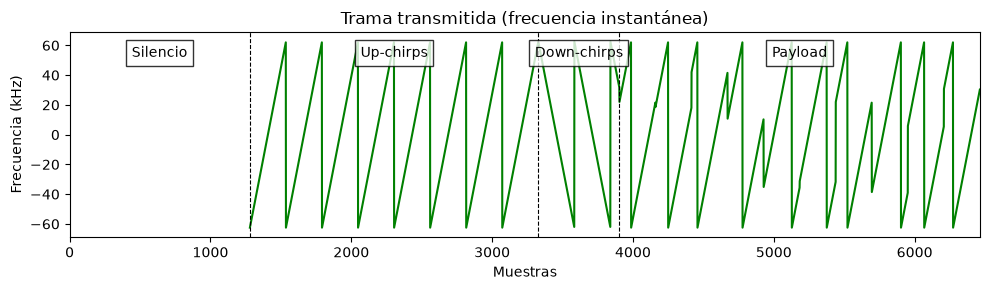

In [23]:
# Escenario para analizar las estrategias de detección
SF = 8
n_simbolos = 10  # Símbolos del payload
SNR_dB = -10
silencio = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
simbolos_tx = rng.integers(0, 2**SF, size=n_simbolos)
R_FA = 1 / 60  # Tasa de falsas alarmas tolerable: una por minuto
P_FA = R_FA * 2**SF / B  # Probabilidad de falsa alarma por símbolo: R_FA T_s

r = simular_trama(simbolos_tx, silencio, SF, B, SNR_dB, CANAL_PLANO)
r_limpia = simular_trama(simbolos_tx, silencio, SF, B, 100, CANAL_PLANO)  # Sin ruido apreciable
sigma2 = potencia_del_ruido(SF, B, SNR_dB)  # Conocida por el receptor

graficar_trama(simbolos_tx, silencio, SF, B);

### 5.2 Test de hipótesis y umbral de Neyman-Pearson

Los cinco métodos resuelven el mismo test de hipótesis binario en cada posición donde podría empezar la trama, que es una muestra en la detección en el tiempo y una ventana en la detección en frecuencia:

- $H_0$: el preámbulo no empieza en esa posición. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en esa posición.

Cada método calcula un estadístico en cada posición y decide $H_1$ cuando supera un umbral. El umbral fija el compromiso entre la probabilidad de falsa alarma, $P_{FA} = P(\text{'}H_1\text{'} \mid H_0)$, y la de detección, $P_D = P(\text{'}H_1\text{'} \mid H_1)$, porque bajarlo solo puede subir las dos.

Como no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, que necesita el criterio de mínima probabilidad de error, el umbral se elige con el criterio de Neyman-Pearson, que maximiza $P_D$ sin que $P_{FA}$ supere un valor tolerable. El umbral es entonces el menor que respeta la $P_{FA}$ tolerable, y para calcularlo alcanza con la distribución del estadístico bajo $H_0$, porque $P_{FA}$ es su cola a partir del umbral. Si la cola se puede invertir, el umbral se despeja, y si no, se calcula numéricamente. Aplicado a la razón de verosimilitud, el criterio da el test óptimo. Aquí cada método define su propio estadístico y el criterio fija solo su umbral.

Una falsa alarma es costosa porque, al decidir $H_1$, el receptor deja de buscar preámbulos y demodula una trama entera que no existe. Si mientras tanto empieza una trama real, la pierde. Con el *payload* de 10 símbolos la trama ocupa $8 + 2.25 + 10 = 20.25$ símbolos, $\approx 41.5$ ms con $SF = 8$ y $B = 125$ kHz, y ese es el tiempo que el receptor queda ocupado por cada falsa alarma.

Por eso la $P_{FA}$ tolerable se fija a partir de la tasa de falsas alarmas que tolera el receptor, $R_{FA}$. El receptor evalúa $B / 2^{SF}$ símbolos por segundo, por lo que la probabilidad de falsa alarma por símbolo es

$$
P_{FA} = R_{FA}\, \frac{2^{SF}}{B}
$$

Se tolera una falsa alarma por minuto, $R_{FA} = 1/60\ \text{s}^{-1}$, que da $P_{FA} \approx 3.4 \cdot 10^{-5}$ por símbolo. Con esa tasa el receptor pasa ocupado con tramas inexistentes $41.5\ \text{ms} / 60\ \text{s} \approx 7 \cdot 10^{-4}$ del tiempo, que es aproximadamente la fracción de tramas reales que pierde por esta causa. Ese valor queda por debajo del menor FER que la simulación estima con 100 tramas perdidas, $10^{-2}$, así que tolerar menos falsas alarmas subiría el umbral y bajaría la $P_D$ sin una mejora que se pueda medir. Todos los métodos usan esta misma $P_{FA}$, para compararlos a igual tasa de falsas alarmas.

En frecuencia hay un test por ventana, es decir, uno por símbolo, y se usa esta $P_{FA}$. En el tiempo se prueban las $2^{SF}$ muestras de cada símbolo, así que cada muestra usa $P_{FA} / 2^{SF}$ para tener la misma tasa de falsas alarmas. Se asume además que el receptor conoce la potencia del ruido $\sigma^2$, que en la práctica se estima mientras no hay señal.

### 5.3 Detección en el tiempo

En el tiempo el receptor no necesita sincronía de símbolo: desliza una plantilla conocida sobre la señal recibida, muestra a muestra, y detecta dónde la señal se parece más. La posición del test es la muestra $k$, y $r_k$ son las muestras recibidas a partir de ella, que bajo $H_1$ son el preámbulo, conocido por el receptor, más ruido gaussiano i.i.d. **La muestra $k$ donde se decide $H_1$ es a la vez la detección y la sincronización**, porque es donde empieza la trama.

#### 5.3.1 Método 1: Correlación con el preámbulo completo

La plantilla $p$ son los 8 *up-chirps* del comienzo del preámbulo. Es el problema de detectar una señal conocida en ruido gaussiano, donde el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[k] = \left| \langle r_k, p \rangle \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
$$

Cada *chirp* tiene energía 1, así que $p$ tiene energía 8. Con la plantilla alineada, los 8 *up-chirps* se suman en fase antes de tomar el módulo y la señal aporta a $\langle r_k, p \rangle$ un valor de módulo 8, mientras que el ruido aporta una varianza de $8\sigma^2$. El SNR del estadístico es entonces $64 / 8\sigma^2 = 8/\sigma^2$, 8 veces ($\approx 9$ dB) el que daría la energía de un solo símbolo. A cambio, necesita que la fase de la señal se mantenga durante los 8 símbolos, lo que un corrimiento de frecuencia entre transmisor y receptor impediría.

**Umbral**: bajo $H_0$ la correlación $\langle r_k, p \rangle$ es gaussiana compleja de varianza $8\sigma^2$, así que $T[k]$ tiene distribución exponencial de media $8\sigma^2$, cuya cola se invierte:

$$
\frac{P_{FA}}{2^{SF}} = P(T[k] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln \frac{P_{FA}}{2^{SF}}
$$

La figura muestra el criterio de Neyman-Pearson con $T[k]$ a $-20$ dB, con los umbrales de una falsa alarma por segundo, por minuto y por hora. A la izquierda están las densidades de $T[k]$ con solo ruido ($H_0$) y con el preámbulo alineado ($H_1$), y el área de cada una a la derecha del umbral es la $P_{FA}$ por muestra o la $P_D$, sombreadas para el umbral de una por minuto. El eje vertical es logarítmico porque esa $P_{FA}$ es del orden de $10^{-7}$ y en escala lineal no se vería. A la derecha está la curva ROC (*Receiver Operating Characteristic*), que recorre todos los umbrales y grafica la $P_D$ de cada uno en función de su $P_{FA}$ por símbolo. Cada umbral de la izquierda es un punto de la curva, y Neyman-Pearson elige el de mayor $P_D$ entre los que respetan la $P_{FA}$ tolerable (estrella), que es el punto de operación del detector.

In [24]:
def correlacion(r: np.ndarray, plantilla: np.ndarray) -> np.ndarray:
    """
    Correlación móvil de r con una plantilla, calculada por FFT.

    Parámetros:
        r: Señal.
        plantilla: Señal conocida, no más larga que r.

    Devuelve:
        sum_i r[k + i] conj(plantilla[i]) para cada k donde entra la plantilla.
    """

    # Correlación móvil de r con una plantilla conocida: sum_i r[k + i] conj(plantilla[i]) para
    # cada muestra k donde entra la plantilla completa. Se calcula por FFT, que da lo mismo que
    # np.correlate(r, plantilla, mode="valid") pero mucho más rápido con plantillas largas. Con n
    # >= r.size, la correlación circular de la FFT no se solapa en las posiciones válidas
    assert r.size >= plantilla.size, "La señal es más corta que la plantilla"
    n = 2 ** int(np.ceil(np.log2(r.size)))  # Potencia de 2 para que la FFT sea rápida
    y = np.fft.ifft(np.fft.fft(r, n) * np.conj(np.fft.fft(plantilla, n)))
    return y[: r.size - plantilla.size + 1]


def correlacion_preambulo(r: np.ndarray, SF: int, B: float) -> np.ndarray:
    """
    Correlación X[k] = <r_k, p> con los up-chirps del preámbulo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        X[k] para cada muestra k donde entra el preámbulo.
    """

    # p son los N_UPCHIRPS up-chirps del preámbulo: la correlación es el filtro adaptado
    plantilla = np.tile(tabla_de_chirps(SF, B)[0], N_UPCHIRPS)
    return correlacion(r, plantilla)


def estadistico_completo(r: np.ndarray, SF: int, B: float) -> np.ndarray:
    """
    Estadístico T[k] = |X[k]|^2 de la correlación con el preámbulo completo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        T[k] para cada muestra k donde entra el preámbulo.
    """

    # Equivale a sumar en fase los impulsos y[k + n 2^SF] y después tomar el módulo
    return np.abs(correlacion_preambulo(r, SF, B)) ** 2


def umbral_completo(SF: int, sigma2: float, P_FA: float) -> float:
    """
    Umbral de Neyman-Pearson de T[k].

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        El umbral eta.
    """

    # Bajo H0, T[k] es exponencial de media N_UPCHIRPS sigma^2, porque cada chirp tiene energía 1.
    # Cada muestra usa P_FA / 2^SF: P_FA / 2^SF = e^{-eta / (N_UPCHIRPS sigma^2)}
    return -N_UPCHIRPS * sigma2 * np.log(P_FA / 2**SF)


def detectar_inicio(estadistico: np.ndarray, eta: float, ventana: int) -> int | None:
    """
    Busca el inicio de la trama: el máximo del estadístico después del primer cruce.

    Parámetros:
        estadistico: Estadístico de cada posición (muestra o ventana).
        eta: Umbral.
        ventana: Posiciones donde se busca el máximo después del cruce.

    Devuelve:
        La posición del inicio, o None si no se detecta la trama.
    """

    # Declara la trama presente (H1) en la primera posición donde el estadístico alcanza el umbral
    # eta. Como las posiciones anteriores al inicio ya se superponen con parte del preámbulo, el
    # primer cruce suele llegar antes de tiempo: el inicio es el máximo del estadístico en las
    # `ventana` posiciones siguientes. La búsqueda se repite desde ese máximo hasta que ninguna de
    # las `ventana` posiciones siguientes lo supere, por si el cruce llegó más de `ventana`
    # posiciones antes del inicio (en el SDR, la cola de la trama anterior puede superar el umbral)
    cruces = np.flatnonzero(estadistico >= eta)
    if cruces.size == 0:
        return None  # No se detecta la trama: H0 en todas las posiciones

    inicio = int(cruces[0])
    while True:
        maximo = inicio + int(np.argmax(estadistico[inicio : inicio + ventana]))
        if maximo == inicio:
            return inicio
        inicio = maximo


def detectar_completo(r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float) -> int | None:
    """
    Detecta el inicio de la trama con la correlación con el preámbulo completo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
    """

    eta = umbral_completo(SF, sigma2, P_FA)
    return detectar_inicio(estadistico_completo(r, SF, B), eta, N_UPCHIRPS * 2**SF)


def marcar_inicios(ax: Axes, real: int, inicio: int | None) -> None:
    """
    Marca el inicio real y el detectado.

    Parámetros:
        ax: Ejes donde se dibuja.
        real: Inicio real.
        inicio: Inicio detectado, o None.
    """

    # Inicio real (negro) e inicio detectado (rojo punteado)
    ax.axvline(real, color="k", ls="--", lw=0.8, label="Inicio real")
    if inicio is not None:
        ax.axvline(inicio, color="r", ls=":", label="Inicio detectado")


def graficar_deteccion_completo(
    T: np.ndarray,
    eta: float,
    inicio: int | None,
    silencio: int,
    SF: int,
    P_FA: float,
    SNR_dB: float,
):
    """
    Grafica T[k] con el umbral, el inicio real y el detectado.

    Parámetros:
        T: Estadístico T[k].
        eta: Umbral.
        inicio: Muestra de inicio detectada, o None.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
    """

    N = 2**SF
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(T, color="green", lw=0.8)
    ax.axhline(
        eta, color="r", ls="--", lw=0.8, label=f"Umbral η ($P_{{FA}}$={P_FA:.1e} por símbolo)"
    )
    marcar_inicios(ax, silencio * N, inicio)
    ax.set(
        title=f"Correlación con el preámbulo completo: inicio real k={silencio * N}, "
        f"detectado k={inicio} (SNR={SNR_dB} dB)",
        xlabel="k (muestra)",
        ylabel="$T[k]$",
        xlim=(0, T.size + N_UPCHIRPS * N - 1),  # Largo de la señal recibida
    )
    ax.legend(loc="upper right")
    fig.tight_layout()
    return fig

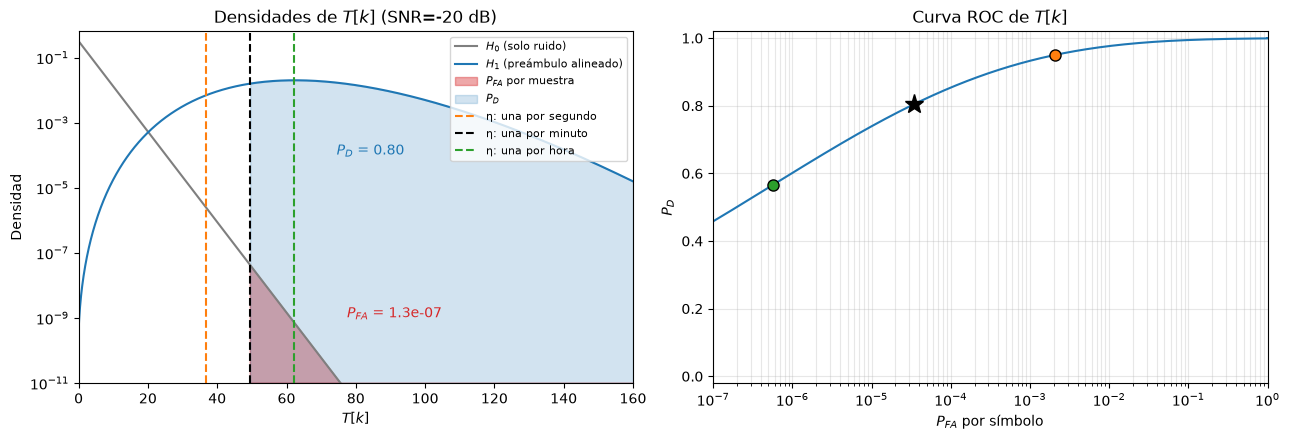

In [25]:
def distribuciones_estadistico_completo(T: np.ndarray, sigma2: float):
    """
    Calcula las densidades y las colas de T[k] bajo H0 y H1, con la plantilla alineada en canal plano.

    Parámetros:
        T: Valores de T[k], equiespaciados desde 0 y hasta donde la densidad bajo H1 es despreciable.
        sigma2: Potencia del ruido por muestra.

    Devuelve:
        Las densidades bajo H0 y H1, y sus colas P(T[k] > T): la P_FA y la P_D por muestra de cada
        umbral T.
    """

    # Con m = N_UPCHIRPS sigma^2, bajo H0 <r_k, p> es gaussiana compleja de varianza m y T[k] es
    # exponencial de media m. Bajo H1 se le suma la señal, de módulo A = N_UPCHIRPS (los chirps de
    # energía 1 sumados en fase). La densidad de T[k] = |A + ruido|^2 sale de integrar la gaussiana
    # compleja sobre la fase: f(T) = e^{-(T + A^2)/m} I0(2 A sqrt(T) / m) / m, con
    # I0(z) = (1/2π) ∫ e^{z cos θ} dθ (np.i0)
    m = N_UPCHIRPS * sigma2
    A = N_UPCHIRPS
    f0 = np.exp(-T / m) / m
    f1 = np.exp(-(T + A**2) / m) * np.i0(2 * A * np.sqrt(T) / m) / m
    # Cola de H1 por integración trapezoidal desde el final de T
    dT = T[1] - T[0]
    P_D = np.append(np.cumsum(((f1[1:] + f1[:-1]) * dT / 2)[::-1])[::-1], 0.0)
    return f0, f1, np.exp(-T / m), P_D


def graficar_neyman_pearson(
    T: np.ndarray,
    f0: np.ndarray,
    f1: np.ndarray,
    P_FA_T: np.ndarray,
    P_D_T: np.ndarray,
    umbrales: dict[str, float],
    operacion: str,
    SF: int,
    SNR_dB: float,
):
    """
    Grafica las densidades de T[k] con varios umbrales y la curva ROC que recorre todos.

    Parámetros:
        T: Valores de T[k].
        f0: Densidad bajo H0.
        f1: Densidad bajo H1.
        P_FA_T: P_FA por muestra de cada umbral T.
        P_D_T: P_D de cada umbral T.
        umbrales: Umbrales a marcar, por nombre.
        operacion: Nombre del umbral de operación.
        SF: Factor de ensanchamiento (spreading factor).
        SNR_dB: SNR de las densidades.

    Devuelve:
        La figura.
    """

    # Las áreas de P_FA y P_D se sombrean para el umbral de operación, que en la ROC se marca con
    # una estrella
    fig, (ax_densidad, ax_roc) = plt.subplots(1, 2, figsize=(13, 4.5))
    piso = 1e-11  # Base del sombreado en el eje logarítmico
    ax_densidad.semilogy(T, f0, color="C7", label="$H_0$ (solo ruido)")
    ax_densidad.semilogy(T, f1, color="C0", label="$H_1$ (preámbulo alineado)")
    eta = umbrales[operacion]
    cola = T >= eta
    ax_densidad.fill_between(
        T[cola], f0[cola], piso, color="C3", alpha=0.4, label="$P_{FA}$ por muestra"
    )
    ax_densidad.fill_between(T[cola], f1[cola], piso, color="C0", alpha=0.2, label="$P_D$")
    # Valor de cada área: en el eje logarítmico su tamaño no se aprecia
    P_FA_eta, P_D_eta = np.interp(eta, T, P_FA_T), np.interp(eta, T, P_D_T)
    ax_densidad.text(eta + 28, 100 * piso, f"$P_{{FA}}$ = {P_FA_eta:.1e}", color="C3")
    ax_densidad.text(eta + 25, 1e-4, f"$P_D$ = {P_D_eta:.2f}", color="C0")

    # En la ROC, la P_FA por símbolo: 2^SF muestras por símbolo
    P_FA_simbolo = np.minimum(2**SF * P_FA_T, 1)
    ax_roc.semilogx(P_FA_simbolo, P_D_T, color="C0")
    for (nombre, eta), color in zip(umbrales.items(), ("C1", "k", "C2")):
        ax_densidad.axvline(eta, color=color, ls="--", lw=1.5, label=f"η: {nombre}")
        marcador = "*" if nombre == operacion else "o"
        punto = (np.interp(eta, T, P_FA_simbolo), np.interp(eta, T, P_D_T))
        ax_roc.semilogx(*punto, marcador, color=color, ms=14 if marcador == "*" else 8, mec="k")

    ax_densidad.set(
        title=f"Densidades de $T[k]$ (SNR={SNR_dB:g} dB)",
        xlabel="$T[k]$",
        ylabel="Densidad",
        xlim=(T[0], T[-1]),
        ylim=(piso, 2 * f0.max()),
    )
    ax_densidad.legend(loc="upper right", fontsize=8)
    ax_roc.set(
        title="Curva ROC de $T[k]$",
        xlabel="$P_{FA}$ por símbolo",
        ylabel="$P_D$",
        xlim=(1e-7, 1),
        ylim=(-0.02, 1.02),
    )
    ax_roc.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    return fig


# Densidades de T[k] y curva ROC a -20 dB, con los umbrales de una falsa alarma por segundo,
# minuto y hora
SNR_densidades_dB = -20
sigma2_densidades = potencia_del_ruido(SF, B, SNR_densidades_dB)
T_eje = np.linspace(0, 160, 2001)  # Hasta donde la densidad bajo H1 es despreciable
distribuciones = distribuciones_estadistico_completo(T_eje, sigma2_densidades)
tasas = {"una por segundo": 1, "una por minuto": R_FA, "una por hora": 1 / 3600}
# P_FA por símbolo de cada tasa R, como la de R_FA
umbrales_por_tasa = {
    nombre: umbral_completo(SF, sigma2_densidades, R * 2**SF / B) for nombre, R in tasas.items()
}

graficar_neyman_pearson(
    T_eje, *distribuciones, umbrales_por_tasa, "una por minuto", SF, SNR_densidades_dB
);

**Observaciones**:
- Bajar el umbral agranda las dos áreas a la vez, y en la ROC el punto sube y se corre a la derecha. A $-20$ dB la $P_D$ es 0.95 con una falsa alarma por segundo, 0.80 con una por minuto y 0.57 con una por hora.
- Pasar de una falsa alarma por minuto a una por hora cuesta 0.23 de $P_D$ a este SNR, a cambio de una mejora que no se puede medir en el FER (ver *Test de hipótesis y umbral de Neyman-Pearson*).

**Inicio de la trama**: alrededor del inicio $T[k]$ presenta un tren de impulsos separados un símbolo ($2^{SF}$ muestras), de amplitud decreciente al alejarse del inicio. Con la plantilla corrida $j$ símbolos enteros quedan alineados $8 - |j|$ *up-chirps* con el preámbulo, y $T \approx (8 - |j|)^2$, 49 con un símbolo de error contra 64 en el inicio. Con cualquier otro corrimiento $T$ es casi nulo, porque un *up-chirp* desplazado en el tiempo es un *up-chirp* con un corrimiento de frecuencia, ortogonal al original. Antes de que la plantilla coincida por completo con el preámbulo, los impulsos laterales ya cruzan el umbral, porque la plantilla corrida un símbolo coincide con 7 de los 8 *up-chirps*, así que el inicio se estima como el máximo de $T[k]$ en los 8 símbolos siguientes al primer cruce. La búsqueda se repite desde ese máximo hasta que ningún valor de los 8 símbolos siguientes lo supere.

![Diagrama de bloques de la detección por correlación con el preámbulo completo](diagramas/filtro_adaptado.svg)

![Recorrido de la plantilla de 8 up-chirps sobre la trama](diagramas/sincronizacion_8_upchirps.gif)

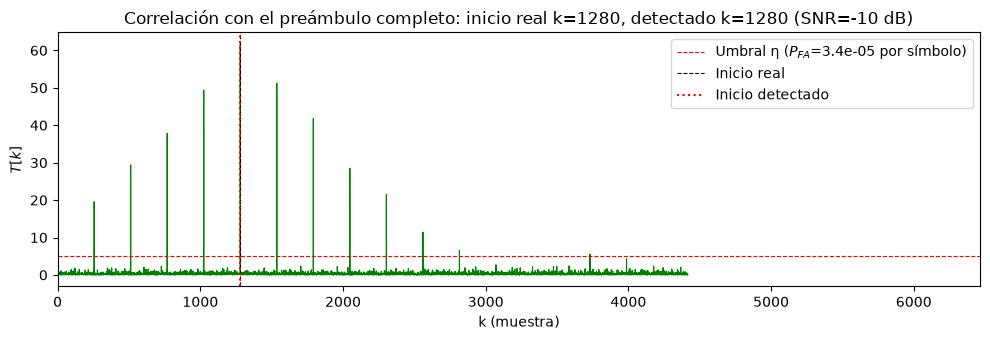

In [26]:
# Correlación con el preámbulo completo sobre el escenario
eta = umbral_completo(SF, sigma2, P_FA)
T = estadistico_completo(r, SF, B)
inicio = detectar_inicio(T, eta, N_UPCHIRPS * 2**SF)

graficar_deteccion_completo(T, eta, inicio, silencio, SF, P_FA, SNR_dB);

#### 5.3.2 Método 2: Búsqueda de 8 impulsos

En lugar de correlar con el preámbulo completo, se correla con un solo *up-chirp* (símbolo 0) y se buscan los impulsos que deja el preámbulo. La correlación móvil es

$$
y[k] = \langle r_k, c|_{s=0} \rangle = \sum_{i=0}^{2^{SF}-1} r(kT + iT)\, c^*(iT)|_{s=0}
$$

Dentro del preámbulo, $|y[k]|^2$ es máxima cuando la plantilla queda alineada con un *up-chirp*, y nula con cualquier otro desplazamiento, por la misma ortogonalidad que en *Método 1: Correlación con el preámbulo completo*. Los impulsos aparecen entonces cada $2^{SF}$ muestras, uno por *up-chirp*, y el preámbulo produce 8.

In [27]:
def correlacion_upchirp(r: np.ndarray, SF: int, B: float) -> np.ndarray:
    """
    Correlación móvil y[k] de r con un up-chirp.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        y[k] para cada muestra k.
    """

    # y[k] = <r_k, c|s=0>: correlación móvil con un up-chirp
    return correlacion(r, tabla_de_chirps(SF, B)[0])


def graficar_correlacion_upchirp(y_limpia: np.ndarray, silencio: int, SF: int):
    """
    Grafica |y[k]|^2 de una trama sin ruido.

    Parámetros:
        y_limpia: y[k] de la trama sin ruido.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        La figura.
    """

    N = 2**SF
    n_muestras = y_limpia.size + N - 1  # Largo de la señal recibida

    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.plot(np.abs(y_limpia) ** 2, color="green", lw=0.8)
    marcar_partes_de_la_trama(ax, silencio, SF, n_muestras)
    ax.set(
        title="Correlación móvil con un up-chirp (sin ruido)",
        xlabel="k (muestra)",
        ylabel="$|y[k]|^2$",
    )
    fig.tight_layout()
    return fig

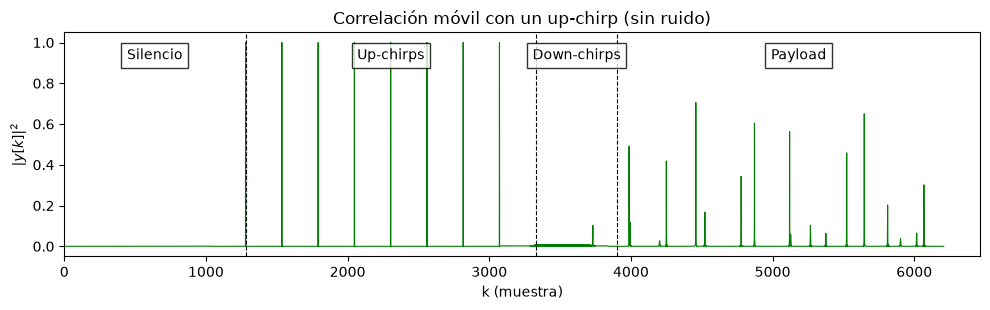

In [28]:
# Correlación móvil con un up-chirp sobre la trama del escenario, sin ruido y con ruido
y_limpia = correlacion_upchirp(r_limpia, SF, B)
y = correlacion_upchirp(r, SF, B)

graficar_correlacion_upchirp(y_limpia, silencio, SF);

El estadístico suma la energía de los 8 impulsos candidatos, separados un tiempo de símbolo ($2^{SF}$ muestras), a partir de la muestra $k$:

$$
S[k] = \sum_{n=0}^{7} \left| y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_S
$$

**La diferencia con $T[k]$ es dónde se toma el módulo.** Como $p$ son *up-chirps* repetidos, $\langle r_k, p \rangle = \sum_{n=0}^{7} y[k + n\,2^{SF}]$, así que $T[k]$ suma los mismos 8 impulsos y después toma el módulo, mientras que $S[k]$ toma el módulo de cada impulso y después suma. Al sumar energías se descarta la fase de cada impulso, así que el método tolera que la fase cambie entre símbolos. A cambio, el ruido de cada impulso suma su energía en lugar de promediarse con el de los demás, y se espera que necesite más SNR que $T[k]$.

Como los impulsos están separados un símbolo, las 8 correlaciones usan muestras disjuntas y bajo $H_0$ son independientes.

**Umbral**: bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, así que $|y|^2$ es exponencial de media $\sigma^2$. Los 8 son independientes, así que la densidad de $S[k]$ es la convolución de sus 8 densidades. El umbral $\eta_S$ es el punto donde la cola de esa densidad vale $P_{FA}/2^{SF}$. Como no se puede despejar, se calcula numéricamente, convolucionando las densidades en una grilla.

**Inicio de la trama**: alrededor del inicio $S[k]$ también presenta un tren de impulsos separados un símbolo, de amplitud decreciente al alejarse del inicio, y el inicio se estima de la misma forma. Sus impulsos laterales son más altos, relativos al principal, que los de $T[k]$. Con un símbolo de error $S \approx 7$, contra 8 en el inicio, mientras que $T$ baja de 64 a 49.

![Diagrama de bloques de la búsqueda de 8 impulsos](diagramas/busqueda_impulsos.svg)

![Recorrido de la plantilla de 1 up-chirp sobre la trama](diagramas/sincronizacion_1_upchirp.gif)

In [29]:
def estadistico_picos(r: np.ndarray, SF: int, B: float) -> np.ndarray:
    """
    Estadístico S[k]: energía de N_UPCHIRPS impulsos de y[k] separados un símbolo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        S[k] para cada muestra k donde entran todos los impulsos.
    """

    # S[k] = suma de |y[k + n 2^SF]|^2 para n = 0..N_UPCHIRPS-1: energía de N_UPCHIRPS impulsos
    # separados un símbolo. El módulo se toma antes de sumar, así que se suman energías
    N = 2**SF
    assert r.size >= N_UPCHIRPS * N, "La señal es más corta que los up-chirps del preámbulo"
    y2 = np.abs(correlacion_upchirp(r, SF, B)) ** 2

    # Posiciones k donde entran todos los impulsos: mismo largo que correlacion_preambulo
    n_validas = y2.size - (N_UPCHIRPS - 1) * N

    S = np.zeros(n_validas)
    for n in range(N_UPCHIRPS):
        S += y2[n * N : n * N + n_validas]  # Impulso n: n símbolos después de k
    return S


@cache
def cola_suma_exponenciales(medias: tuple[float, ...]) -> tuple[np.ndarray, np.ndarray]:
    """
    Cola P(suma > x) de una suma de exponenciales independientes, en una grilla de x.

    Parámetros:
        medias: Media de cada exponencial, como tupla (para que @cache la pueda guardar).

    Devuelve:
        La grilla x y la cola en cada punto.
    """

    # La densidad de una suma de variables independientes es la convolución de sus densidades.
    # Cada exponencial se discretiza en intervalos de ancho dx, con la probabilidad de caer en cada
    # uno, e^{-i dx/mu} (1 - e^{-dx/mu}), y las probabilidades se convolucionan con la FFT: la
    # transformada de la convolución es el producto de las transformadas. Con 2n puntos, la
    # convolución circular coincide con la lineal en los primeros n. La discretización corre el
    # umbral menos de dx por exponencial, un 0.1 % de la mayor media, y la grilla llega hasta
    # donde la cola es despreciable
    dx = max(medias) / 1000
    n = int((sum(medias) + 60 * max(medias)) / dx)
    i = np.arange(n)
    transformada = np.ones(n + 1, dtype=complex)  # rfft de 2n puntos: n + 1 frecuencias
    for mu in medias:
        transformada *= np.fft.rfft(np.exp(-i * dx / mu) * (1 - np.exp(-dx / mu)), 2 * n)
    probabilidades = np.fft.irfft(transformada, 2 * n)[:n]

    # Cola: probabilidad acumulada desde el final de la grilla
    return i * dx, np.cumsum(probabilidades[::-1])[::-1]


def umbral_suma_exponenciales(medias, P_FA: float) -> float:
    """
    Umbral de Neyman-Pearson de una suma de exponenciales independientes.

    Parámetros:
        medias: Media de cada exponencial.
        P_FA: Probabilidad de falsa alarma por posición.

    Devuelve:
        El primer punto de la grilla donde la cola no supera P_FA.
    """

    x, cola = cola_suma_exponenciales(tuple(medias))
    return float(x[np.argmax(cola <= P_FA)])


def umbral_picos(SF: int, sigma2: float, P_FA: float) -> float:
    """
    Umbral de Neyman-Pearson de S[k].

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        El umbral eta_S.
    """

    # Bajo H0, S[k] es la suma de N_UPCHIRPS exponenciales independientes de media sigma^2. Cada
    # muestra usa P_FA / 2^SF
    return umbral_suma_exponenciales((sigma2,) * N_UPCHIRPS, P_FA / 2**SF)


def detectar_picos(r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float) -> int | None:
    """
    Detecta el inicio de la trama con la búsqueda de 8 impulsos.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
    """

    eta_S = umbral_picos(SF, sigma2, P_FA)
    return detectar_inicio(estadistico_picos(r, SF, B), eta_S, N_UPCHIRPS * 2**SF)


def graficar_deteccion_picos(
    y: np.ndarray,
    S: np.ndarray,
    eta_S: float,
    inicio: int | None,
    silencio: int,
    SF: int,
    P_FA: float,
    SNR_dB: float,
):
    """
    Grafica |y[k]|^2 con los impulsos del inicio detectado, y S[k] con su umbral.

    Parámetros:
        y: Correlación móvil con un up-chirp.
        S: Estadístico S[k].
        eta_S: Umbral.
        inicio: Muestra de inicio detectada, o None.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
    """

    N = 2**SF
    n_muestras = y.size + N - 1  # Largo de la señal recibida

    fig, axs = plt.subplots(2, 1, figsize=(10, 6))
    axs[0].plot(np.abs(y) ** 2, color="green", lw=0.8)
    if inicio is not None:
        # Los impulsos que suma S[k] en el inicio detectado
        impulsos = inicio + np.arange(N_UPCHIRPS) * N
        axs[0].plot(
            impulsos,
            np.abs(y[impulsos]) ** 2,
            "o",
            mfc="none",
            color="r",
            label=f"{N_UPCHIRPS} impulsos del inicio detectado",
        )
        axs[0].legend(loc="upper right")
    axs[0].set(title=f"Correlación móvil con un up-chirp (SNR={SNR_dB} dB)", ylabel="$|y[k]|^2$")

    axs[1].plot(S, color="green", lw=0.8)
    axs[1].axhline(
        eta_S, color="r", ls="--", lw=0.8, label=f"Umbral $η_S$ ($P_{{FA}}$={P_FA:.1e} por símbolo)"
    )
    marcar_inicios(axs[1], silencio * N, inicio)
    axs[1].set(
        title=f"Búsqueda de {N_UPCHIRPS} impulsos: inicio real k={silencio * N}, detectado "
        f"k={inicio} (SNR={SNR_dB} dB)",
        ylabel="$S[k]$",
    )
    axs[1].legend(loc="upper right")

    for ax in axs:
        ax.set(xlabel="k (muestra)", xlim=(0, n_muestras))
    fig.tight_layout()
    return fig

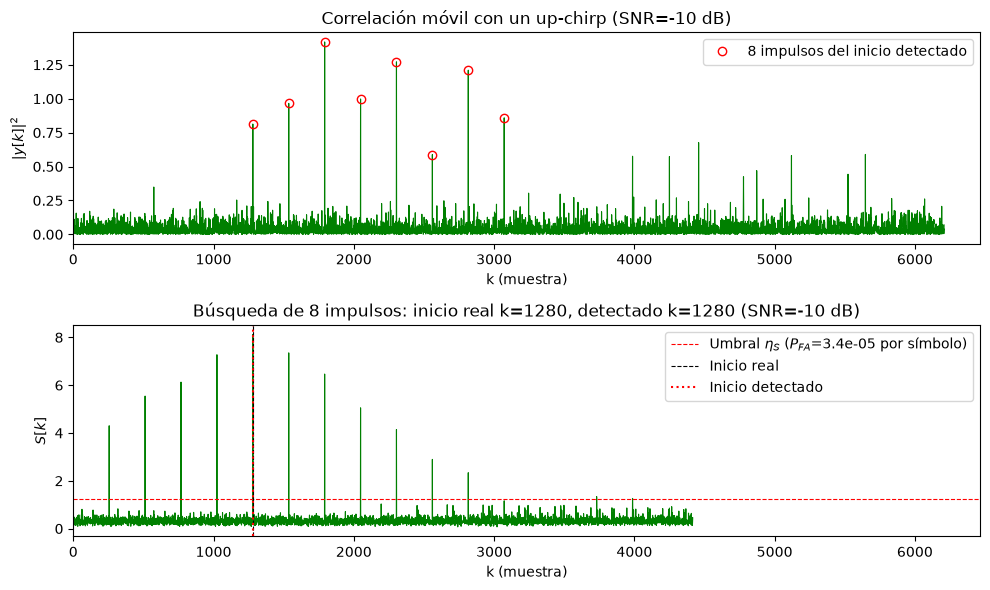

In [30]:
# Búsqueda de 8 impulsos sobre el escenario
eta_S = umbral_picos(SF, sigma2, P_FA)
S = estadistico_picos(r, SF, B)
inicio = detectar_inicio(S, eta_S, N_UPCHIRPS * 2**SF)

graficar_deteccion_picos(y, S, eta_S, inicio, silencio, SF, P_FA, SNR_dB);

### 5.4 Detección en frecuencia

A diferencia de la detección en el tiempo, se asume sincronía de símbolo. El receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos, y lo que no conoce es en qué ventana $m$ empieza la trama. La posición del test es la ventana en lugar de la muestra.

#### 5.4.1 Método 3: Demodulación del preámbulo

La estrategia en frecuencia reutiliza el demodulador (ver *Demodulación*): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el impulso de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo, porque $D_n[0]$ es la correlación móvil $y[k]$ de la búsqueda de 8 impulsos evaluada en el borde de la ventana, $k = n\,2^{SF}$. **La diferencia está en comparar el bin 0 con los demás bins en vez de con un umbral absoluto.** El estadístico es la cantidad de ventanas, entre 8 consecutivas, en las que el demodulador decide el símbolo $\hat{s}[n] = 0$:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

![Diagrama de bloques de la demodulación del preámbulo](diagramas/demodulacion_preambulo.svg)

![Recorrido de las ventanas fijas sobre la trama](diagramas/sincronizacion_ventanas.gif)

**Umbral**: bajo $H_0$ cada ventana es ruido blanco gaussiano, y su FFT (unitaria) también lo es, así que el máximo cae en cualquiera de los $2^{SF}$ bins con igual probabilidad y cada ventana se decide como símbolo 0 con probabilidad $p_0 = 2^{-SF}$. El ruido de ventanas distintas es independiente, por lo que $V[m]$ tiene distribución binomial $\mathcal{B}(8, p_0)$:

$$
P_{FA}(K) = P(V[m] \geq K \mid H_0) = \sum_{k=K}^{8} \binom{8}{k} p_0^k (1 - p_0)^{8-k}
$$

$V[m]$ es discreto, así que en general ningún $K$ da exactamente la $P_{FA}$ pedida, y se elige el menor $K$ con $P_{FA}(K) \leq P_{FA}$. Para $SF = 8$ y $P_{FA} \approx 3.4 \cdot 10^{-5}$, $P_{FA}(2) \approx 4.2 \cdot 10^{-4}$ no la respeta y $P_{FA}(3) \approx 3.3 \cdot 10^{-6}$ sí, así que $K = 3$, con una $P_{FA}$ unas 10 veces menor que la tolerada.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins y la distribución de $V[m]$ bajo $H_0$ solo depende de $SF$. No hace falta conocer ni estimar la potencia del ruido.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de sumar en fase los 8 *up-chirps*. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también se decide como símbolo 0, y $V[m]$ empata en 8 con el inicio real. Se elige la primera ventana del empate, un error de $\approx 0.4\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[k]$ es continuo.

In [31]:
def estadistico_frecuencia(r: np.ndarray, SF: int) -> np.ndarray:
    """
    Estadístico V[m]: ventanas decididas como 0 entre las N_UPCHIRPS a partir de m.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        V[m] para cada ventana m donde entra el preámbulo.
    """

    N = 2**SF
    assert r.size >= N_UPCHIRPS * N, "La señal es más corta que los up-chirps del preámbulo"

    # Demodular cada ventana de 2^SF muestras (sincronía de símbolo). Se descarta el resto
    simbolos_rx = demodulador(r[: r.size // N * N], SF)

    # 1 si el impulso de la FFT de la ventana está en el bin 0, como en un up-chirp del preámbulo
    es_cero = (simbolos_rx == 0).astype(int)

    # Suma de N_UPCHIRPS ventanas consecutivas a partir de cada m
    return np.convolve(es_cero, np.ones(N_UPCHIRPS, dtype=int), mode="valid")


def falsa_alarma_frecuencia(K: int, SF: int) -> float:
    """
    Probabilidad de falsa alarma de V[m] con umbral K.

    Parámetros:
        K: Umbral.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        P(V[m] >= K | H0).
    """

    # P(V[m] >= K | H0). Bajo H0, cada ventana se decide como símbolo 0 con probabilidad 2^-SF,
    # así que V[m] tiene distribución binomial B(N_UPCHIRPS, 2^-SF)
    p0 = 2.0**-SF
    n = N_UPCHIRPS
    return sum(comb(n, k) * p0**k * (1 - p0) ** (n - k) for k in range(K, n + 1))


def umbral_frecuencia(SF: int, P_FA: float) -> int:
    """
    Umbral de Neyman-Pearson de V[m]: el menor K que cumple la P_FA.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por ventana.

    Devuelve:
        El umbral K.
    """

    # Neyman-Pearson para V[m], con la P_FA por ventana. Como V[m] es discreto, se elige el menor
    # K (mayor P_D) cuya P_FA no supera la pedida. Con K = N_UPCHIRPS + 1 nunca se decide H1, así
    # que siempre hay solución
    for K in range(N_UPCHIRPS + 2):
        if falsa_alarma_frecuencia(K, SF) <= P_FA:
            return K


def detectar_frecuencia(r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float) -> int | None:
    """
    Detecta el inicio de la trama con la demodulación del preámbulo.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: No se usa: está para tener la misma firma que los otros detectores.
        sigma2: No se usa, igual que B.
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
    """

    # Muestra de inicio de la trama, o None. Hay un test por ventana, así que usa la P_FA por
    # símbolo. B y sigma2 no se usan: están para tener la misma firma que los detectores en el
    # tiempo
    K = umbral_frecuencia(SF, P_FA)
    inicio = detectar_inicio(estadistico_frecuencia(r, SF), K, N_UPCHIRPS)
    return None if inicio is None else inicio * 2**SF  # La ventana m empieza en m 2^SF


def graficar_deteccion_frecuencia(
    simbolos_rx: np.ndarray,
    V: np.ndarray,
    K: int,
    inicio: int | None,
    silencio: int,
    P_FA: float,
    SNR_dB: float,
):
    """
    Grafica el símbolo decidido en cada ventana, y V[m] con su umbral.

    Parámetros:
        simbolos_rx: Símbolo decidido en cada ventana.
        V: Estadístico V[m].
        K: Umbral.
        inicio: Ventana de inicio detectada, o None.
        silencio: Símbolos de silencio antes de la trama.
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
    """

    # `inicio` es una ventana
    fig, axs = plt.subplots(2, 1, figsize=(10, 6))
    axs[0].plot(simbolos_rx, "o", color="green")
    axs[0].axvspan(
        silencio - 0.5,
        silencio + N_UPCHIRPS - 0.5,
        color="k",
        alpha=0.1,
        label="Up-chirps del preámbulo",
    )
    axs[0].set(
        title="Símbolo decidido en cada ventana", xlabel="n (ventana)", ylabel=r"$\hat{s}[n]$"
    )

    axs[1].plot(V, marker="o", color="green")
    axs[1].axhline(K, color="r", ls="--", lw=0.8, label=f"Umbral K={K} ($P_{{FA}}$={P_FA:.1e})")
    axs[1].axvline(silencio, color="k", ls="--", lw=0.8, label="Inicio real")
    axs[1].set(
        title=f"Detección en frecuencia: inicio real m={silencio}, detectado m={inicio} "
        f"(SNR={SNR_dB} dB)",
        xlabel="m (ventana)",
        ylabel="$V[m]$",
    )

    for ax in axs:
        ax.legend()
    fig.tight_layout()
    return fig

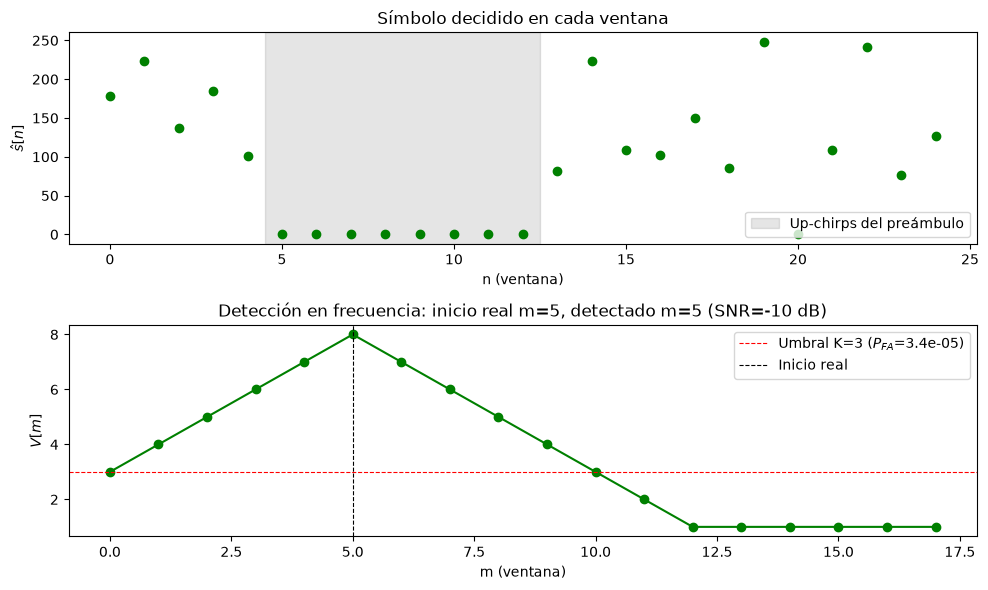

In [32]:
# Detección en frecuencia sobre el escenario
K = umbral_frecuencia(SF, P_FA)  # Un test por ventana: la P_FA por símbolo
V = estadistico_frecuencia(r, SF)
inicio = detectar_inicio(V, K, N_UPCHIRPS)

# Símbolo decidido en cada ventana, para ver qué ventanas cuentan en V[m]
simbolos_rx = demodulador(r[: r.size // 2**SF * 2**SF], SF)

graficar_deteccion_frecuencia(simbolos_rx, V, K, inicio, silencio, P_FA, SNR_dB);

### 5.5 Métodos 4 y 5: Detección con estimación del canal

Los tres métodos anteriores buscan una sola copia del preámbulo, así que en un canal con varios caminos aprovechan solo la energía del camino directo. La figura muestra la correlación con el preámbulo completo, $T[k]$, de la trama del escenario en los cuatro canales y con el mismo ruido. A la derecha se amplía el impulso principal alrededor del inicio real de la trama, la muestra $\tau$, y los círculos marcan el aporte de cada camino sin ruido, es decir, el valor de $T[\tau + l]$ cuando la plantilla queda alineada con el camino $l$, que es proporcional a su potencia $|h[l]|^2$.

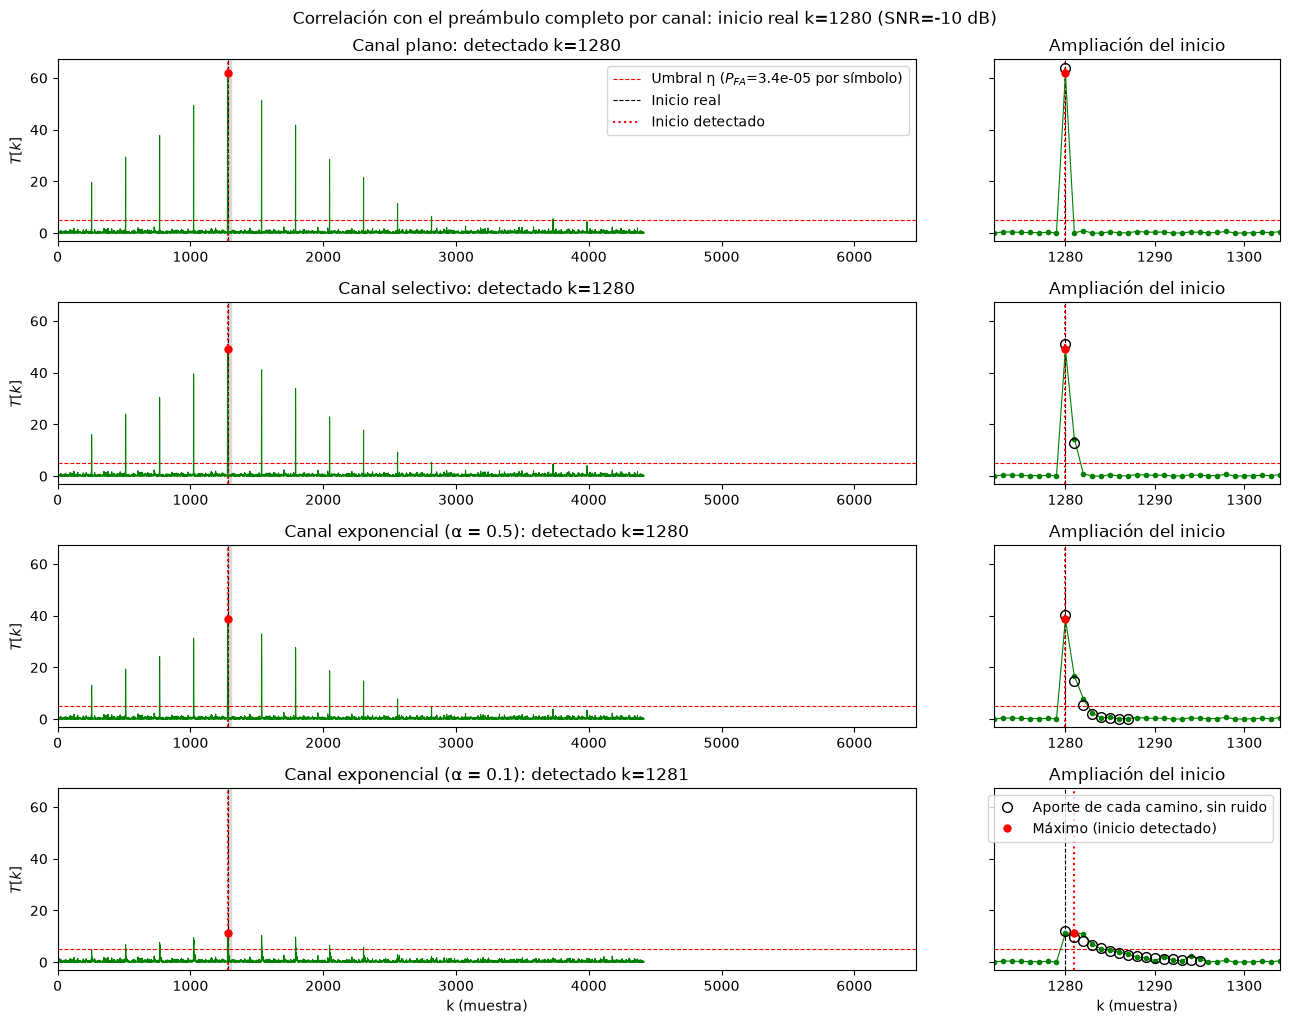

In [33]:
def graficar_correlacion_canales(
    T: dict[str, np.ndarray],
    canales: dict[str, np.ndarray],
    eta: float,
    inicios: dict[str, int | None],
    silencio: int,
    SF: int,
    P_FA: float,
    SNR_dB: float,
    zoom: tuple[int, int] = (-8, 24),
):
    """
    Grafica T[k] en cada canal con los mismos ejes y, al lado, una ampliación del inicio real.

    Parámetros:
        T: Estadístico T[k] de cada canal, por su nombre.
        canales: Respuesta al impulso de cada canal, por su nombre.
        eta: Umbral, el mismo en todos los canales porque solo depende de sigma^2.
        inicios: Muestra de inicio detectada en cada canal, o None.
        silencio: Símbolos de silencio antes de la trama.
        SF: Factor de ensanchamiento (spreading factor).
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.
        zoom: Muestras antes y después del inicio real que abarca la ampliación.

    Devuelve:
        La figura.
    """

    N = 2**SF
    tau = silencio * N
    fig, axs = plt.subplots(
        len(T), 2, figsize=(13, 2.6 * len(T)), sharey=True, gridspec_kw={"width_ratios": [3, 1]}
    )
    for (ax, ax_zoom), (nombre, T_canal) in zip(axs, T.items()):
        for a in (ax, ax_zoom):
            a.axhline(
                eta,
                color="r",
                ls="--",
                lw=0.8,
                label=f"Umbral η ($P_{{FA}}$={P_FA:.1e} por símbolo)",
            )
            marcar_inicios(a, tau, inicios[nombre])
        ax.plot(T_canal, color="green", lw=0.8)
        ax.axvspan(tau + zoom[0], tau + zoom[1], color="0.85", zorder=0)  # Zona ampliada
        ax.set(
            title=f"{nombre}: detectado k={inicios[nombre]}",
            ylabel="$T[k]$",
            xlim=(0, T_canal.size + N_UPCHIRPS * N - 1),
        )

        # Ampliación: T[k] muestra a muestra y, sin ruido, la plantilla alineada con el camino l
        # suma sus N_UPCHIRPS up-chirps en fase, así que T[tau + l] = (N_UPCHIRPS |h[l]|)^2
        h = canales[nombre]
        ax_zoom.plot(T_canal, "o-", color="green", ms=3, lw=0.8)
        ax_zoom.plot(
            tau + np.arange(h.size),
            (N_UPCHIRPS * np.abs(h)) ** 2,
            "o",
            mec="k",
            mfc="none",
            ms=7,
            label="Aporte de cada camino, sin ruido",
        )
        ax_zoom.set(title="Ampliación del inicio", xlim=(tau + zoom[0], tau + zoom[1]))

        # Punto en el máximo (el inicio detectado), cuya altura la línea vertical no deja ver
        if inicios[nombre] is not None:
            for a in (ax, ax_zoom):
                a.plot(
                    inicios[nombre],
                    T_canal[inicios[nombre]],
                    "o",
                    color="r",
                    ms=5,
                    zorder=5,
                    label="Máximo (inicio detectado)",
                )

    # Leyenda de la ampliación en el último canal, donde los picos son bajos y no tapa nada
    axs[0, 0].legend(handles=axs[0, 0].get_legend_handles_labels()[0][:3], loc="upper right")
    axs[-1, 1].legend(handles=axs[-1, 1].get_legend_handles_labels()[0][-2:], loc="upper right")
    for a in axs[-1]:
        a.set_xlabel("k (muestra)")
    fig.suptitle(
        f"Correlación con el preámbulo completo por canal: inicio real k={tau} (SNR={SNR_dB} dB)"
    )
    fig.tight_layout()
    return fig


canales = {
    "Canal plano": CANAL_PLANO,
    "Canal selectivo": CANAL_SELECTIVO,
    "Canal exponencial (α = 0.5)": CANAL_EXP_RAPIDO,
    "Canal exponencial (α = 0.1)": CANAL_EXP_LENTO,
}

# La trama del escenario por cada canal y con el mismo ruido que r: la trama sin ruido (r_limpia)
# pasa por el canal y se le suma el ruido de r. En el canal plano, T[k] es el del Método 1
T_canales, inicios_canales = {}, {}
for nombre_canal, h_canal in canales.items():
    r_canal = canal(r_limpia, h_canal, r - r_limpia)
    T_canales[nombre_canal] = estadistico_completo(r_canal, SF, B)
    inicios_canales[nombre_canal] = detectar_inicio(
        T_canales[nombre_canal], eta, N_UPCHIRPS * 2**SF
    )

graficar_correlacion_canales(T_canales, canales, eta, inicios_canales, silencio, SF, P_FA, SNR_dB);

**Observaciones**:
- En el canal plano el impulso principal ocupa una sola muestra y la figura coincide con la de *Método 1: Correlación con el preámbulo completo*. Con varios caminos, cada impulso del tren se reparte en tantas muestras como caminos tiene el canal, y alrededor del inicio $T[k]$ sigue el aporte de cada camino, es decir, reproduce la respuesta al impulso del canal.
- El impulso principal baja con la energía del camino directo, que es el 80 % en el canal selectivo ($\approx 1$ dB menos), el 63 % en el exponencial con $\alpha = 0.5$ ($\approx 2$ dB menos) y el 19 % con $\alpha = 0.1$ ($\approx 7$ dB menos). En esta trama, $T[\tau]$ pasa de 59 en el canal plano a 47, 37 y 10.
- Con $\alpha = 0.1$ los caminos consecutivos tienen potencias parecidas, y el ruido puede llevar el máximo a uno posterior. En esta trama cinco muestras seguidas superan el umbral y el máximo cae en $\tau + 1$, así que el inicio se estima una muestra tarde.

**Los dos métodos de esta sección estiman primero la respuesta al impulso del canal con el preámbulo y después suman la energía de todos los caminos.**

**Estimación LS**: se parte de la correlación con el preámbulo completo sin el módulo, $X[k] = \langle r_k, p \rangle$, de modo que $T[k] = |X[k]|^2$. Si la trama empieza en la muestra $\tau$, la señal recibida es la suma de $L$ copias del preámbulo:

$$
r[n] = \sum_{l=0}^{L-1} h[l]\, c[n - \tau - l] + w[n]
$$

Con la plantilla alineada con la copia $l$, en $k = \tau + l$, sus 8 *up-chirps* se suman en fase y aportan $8\,h[l]$. Las demás copias quedan corridas y son aproximadamente ortogonales a la plantilla. Alrededor del inicio, $X[k]$ reproduce entonces la respuesta al impulso del canal, como la salida de un filtro adaptado cuando el mismo pulso llega con distintos retardos. La estimación de cada coeficiente es

$$
\hat h_{LS}[l] = \frac{X[\tau + l]}{8} = h[l] + \frac{\langle w_{\tau + l}, p \rangle}{8}
$$

con un error de varianza $\sigma^2/8$. Se llama de mínimos cuadrados (LS, *least squares*) porque, con las copias ortogonales, es el $h$ que minimiza la distancia entre la señal recibida y la suma de las copias del preámbulo. Es la misma información que muestra el periodograma del demodulador, donde cada camino retrasado una muestra cae un bin más abajo (ver *Canal selectivo en frecuencia*).

**Estimación LMMSE**: la estimación LS no usa lo que se sabe del canal y deja el mismo error en todos los coeficientes, también en los caminos débiles, donde el ruido supera a la señal. El estimador lineal de mínimo error cuadrático medio (LMMSE) trata cada coeficiente como una variable aleatoria de media nula, porque su fase es desconocida, y potencia $P[l] = E|h[l]|^2$ (el perfil de potencia del canal), independiente de los demás y del ruido. Para una medición con ruido aditivo, el principio de ortogonalidad da (Oppenheim y Verghese, sección 8.3.1)

$$
\hat h_{LMMSE}[l] = a[l]\, \hat h_{LS}[l], \qquad a[l] = \frac{P[l]}{P[l] + \sigma^2/8}
$$

El peso $a[l]$ compara la potencia del camino con la del error de su estimación. Es cercano a 1 en los caminos fuertes, que se conservan, y cercano a 0 en los débiles, donde la estimación es casi solo ruido. Como los coeficientes son independientes, el estimador de todos los coeficientes juntos (sección 8.3.2) se separa en un peso por coeficiente. Igual que $\sigma^2$, se asume que el receptor conoce el perfil, $P[l] = h^2[l]$. El error cuadrático medio de cada estimador es

$$
E\|\hat h_{LS} - h\|^2 = L\, \frac{\sigma^2}{8}, \qquad E\|\hat h_{LMMSE} - h\|^2 = \sum_{l=0}^{L-1} \frac{P[l]\, \sigma^2/8}{P[l] + \sigma^2/8}
$$

y el del LMMSE es menor, porque cada término de la suma es menor que $\sigma^2/8$.

Se estima el canal exponencial con $\alpha = 0.1$ en una trama del escenario que empieza 37 muestras después de los 5 símbolos de silencio. El gráfico muestra el módulo de las dos estimaciones y el del canal, desde unas muestras antes del inicio real, junto con el inicio detectado por la correlación con el preámbulo completo.

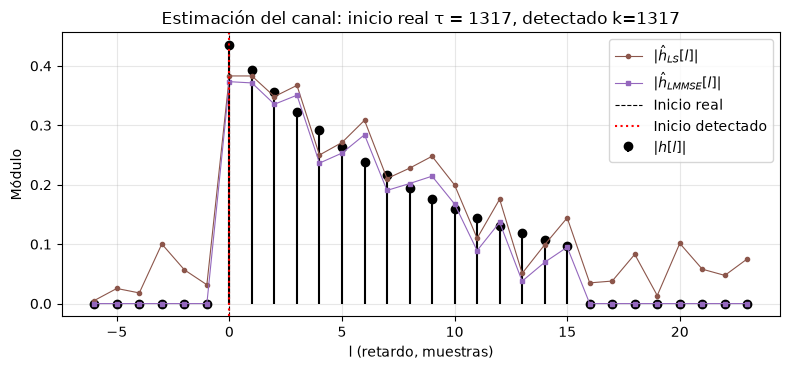

In [35]:
def estimar_canal_ls(r: np.ndarray, SF: int, B: float, k: int, L: int) -> np.ndarray:
    """
    Estimación LS de los L coeficientes del canal, suponiendo que la trama empieza en k.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        k: Muestra de inicio supuesta.
        L: Cantidad de coeficientes a estimar.

    Devuelve:
        h_LS[l] para l = 0, ..., L - 1.
    """

    # h_LS[l] = X[k + l] / N_UPCHIRPS: la plantilla alineada con la copia l del preámbulo suma sus
    # N_UPCHIRPS up-chirps en fase. Deja pasar el ruido entero en cada coeficiente (varianza
    # sigma^2 / N_UPCHIRPS), aunque el camino no tenga energía
    return correlacion_preambulo(r, SF, B)[k : k + L] / N_UPCHIRPS


def pesos_lmmse(P: np.ndarray, sigma2: float) -> np.ndarray:
    """
    Pesos del estimador LMMSE: h_LMMSE[l] = a[l] h_LS[l].

    Parámetros:
        P: Perfil de potencia del canal, P[l] = E|h[l]|^2.
        sigma2: Potencia del ruido por muestra (sigma^2).

    Devuelve:
        Los pesos a[l].
    """

    # a[l] = P[l] / (P[l] + sigma^2 / N_UPCHIRPS): compara la potencia del camino con la del error
    # de su estimación. Cerca de 1 donde el camino es fuerte y cerca de 0 donde solo hay ruido
    return P / (P + sigma2 / N_UPCHIRPS)


def ecm_teorico(P: np.ndarray, sigma2: float) -> tuple[float, float]:
    """
    Error cuadrático medio teórico de las estimaciones LS y LMMSE.

    Parámetros:
        P: Perfil de potencia del canal.
        sigma2: Potencia del ruido por muestra (sigma^2).

    Devuelve:
        (ECM de LS, ECM de LMMSE).
    """

    # Con var = sigma^2 / N_UPCHIRPS, el error de cada coeficiente es var en LS y
    # P var / (P + var), menor que var, en LMMSE
    var = sigma2 / N_UPCHIRPS
    return P.size * var, float(np.sum(P * var / (P + var)))


def ecm_vs_snr(
    SNRs_dB: np.ndarray, h: np.ndarray, SF: int, B: float, n_tramas: int
) -> dict[str, np.ndarray]:
    """
    Simula el error cuadrático medio de las estimaciones LS y LMMSE, con el inicio conocido.

    Parámetros:
        SNRs_dB: SNR a simular, en dB.
        h: Respuesta al impulso del canal. El receptor conoce su perfil h^2.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        n_tramas: Tramas por SNR.

    Devuelve:
        El ECM de cada SNR, para "LS" y "LMMSE".
    """

    # Para cada SNR transmite n_tramas tramas sin silencio, así que la trama empieza en la muestra
    # 0, y promedia ||h_est - h||^2. Un símbolo de payload alcanza, porque solo se usa el preámbulo
    ecm = {"LS": np.zeros(len(SNRs_dB)), "LMMSE": np.zeros(len(SNRs_dB))}
    for i, SNR_dB in enumerate(SNRs_dB):
        a = pesos_lmmse(h**2, potencia_del_ruido(SF, B, SNR_dB))
        for _ in range(n_tramas):
            r = simular_trama(rng.integers(0, 2**SF, size=1), 0, SF, B, SNR_dB, h)
            h_ls = estimar_canal_ls(r, SF, B, 0, h.size)
            ecm["LS"][i] += np.sum(np.abs(h_ls - h) ** 2) / n_tramas
            ecm["LMMSE"][i] += np.sum(np.abs(a * h_ls - h) ** 2) / n_tramas
    return ecm


def graficar_estimaciones_canal(
    r: np.ndarray,
    tau: int,
    inicio: int | None,
    h: np.ndarray,
    SF: int,
    B: float,
    sigma2: float,
    alcance: int,
):
    """
    Grafica las estimaciones LS y LMMSE alrededor del inicio de la trama, junto con el canal real.

    Parámetros:
        r: Señal recibida.
        tau: Inicio real de la trama.
        inicio: Inicio detectado, o None.
        h: Respuesta al impulso del canal.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        alcance: Retardos que se grafican después del inicio.

    Devuelve:
        La figura.
    """

    # Estima desde alcance/4 muestras antes del inicio hasta `alcance` después. Fuera de los L
    # caminos el perfil vale 0: LS deja el ruido entero y el peso de LMMSE es 0
    antes = alcance // 4
    retardos = np.arange(-antes, alcance)
    P = np.zeros(retardos.size)
    P[antes : antes + h.size] = h**2
    a = pesos_lmmse(P, sigma2)
    h_ls = estimar_canal_ls(r, SF, B, tau - antes, retardos.size)

    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.stem(retardos, np.sqrt(P), linefmt="k-", markerfmt="ko", basefmt=" ", label="$|h[l]|$")
    ax.plot(retardos, np.abs(h_ls), "o-", color="C5", ms=3, lw=0.8, label=r"$|\hat h_{LS}[l]|$")
    ax.plot(
        retardos, np.abs(a * h_ls), "s-", color="C4", ms=3, lw=0.8, label=r"$|\hat h_{LMMSE}[l]|$"
    )
    # Inicios en retardos: el real en l = 0 y el detectado en l = inicio - tau
    marcar_inicios(ax, 0, None if inicio is None else inicio - tau)
    ax.set(
        title=f"Estimación del canal: inicio real τ = {tau}, detectado k={inicio}",
        xlabel="l (retardo, muestras)",
        ylabel="Módulo",
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig


# Estimación del canal exponencial (alfa = 0.1) en una trama del escenario que empieza 37 muestras
# después del silencio, y su inicio detectado con la correlación con el preámbulo completo
h = CANAL_EXP_LENTO
tau = silencio * 2**SF + 37
r_exp = simular_trama(simbolos_tx, silencio, SF, B, SNR_dB, h, 37)
inicio = detectar_inicio(estadistico_completo(r_exp, SF, B), eta, N_UPCHIRPS * 2**SF)

graficar_estimaciones_canal(r_exp, tau, inicio, h, SF, B, sigma2, alcance=24);

Para comparar los estimadores en función del SNR se simula su error cuadrático medio con el inicio conocido, en 2000 tramas por SNR, y se compara con el teórico.

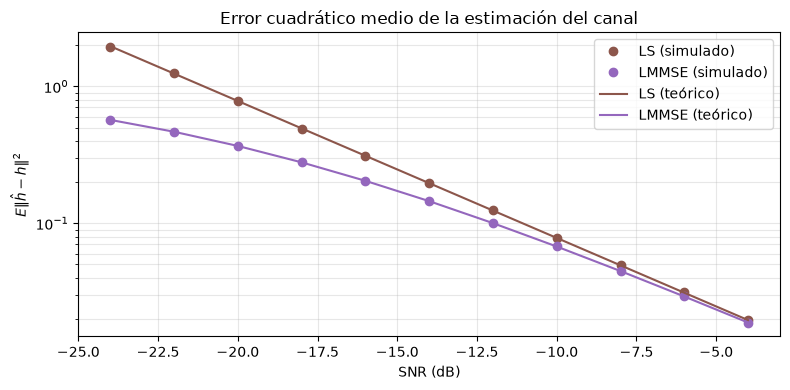

In [230]:
def graficar_ecm(SNRs_dB: np.ndarray, ecm: dict[str, np.ndarray], teorico: dict[str, np.ndarray]):
    """
    Grafica el error cuadrático medio de los estimadores vs SNR: simulado y teórico.

    Parámetros:
        SNRs_dB: SNR, en dB.
        ecm: ECM simulado de cada estimador ("LS", "LMMSE").
        teorico: ECM teórico de cada estimador.

    Devuelve:
        La figura.
    """

    # Simulado con marcadores y teórico con línea llena, en escala logarítmica
    colores = {"LS": "C5", "LMMSE": "C4"}
    fig, ax = plt.subplots(figsize=(8, 4))
    for nombre, valores in ecm.items():
        ax.semilogy(SNRs_dB, valores, "o", color=colores[nombre], label=f"{nombre} (simulado)")
    for nombre, valores in teorico.items():
        ax.semilogy(SNRs_dB, valores, "-", color=colores[nombre], label=f"{nombre} (teórico)")
    ax.set(
        title="Error cuadrático medio de la estimación del canal",
        xlabel="SNR (dB)",
        ylabel=r"$E\|\hat h - h\|^2$",
    )
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig


# Error cuadrático medio de las estimaciones del canal exponencial (alfa = 0.1)
SNRs_ecm_dB = np.arange(-24.0, -3.0, 2.0)  # -24 a -4 dB
ecm = ecm_vs_snr(SNRs_ecm_dB, h, SF, B, 2000)

teorico = {"LS": [], "LMMSE": []}
for SNR in SNRs_ecm_dB:
    ecm_ls, ecm_lmmse = ecm_teorico(h**2, potencia_del_ruido(SF, B, SNR))
    teorico["LS"].append(ecm_ls)
    teorico["LMMSE"].append(ecm_lmmse)

graficar_ecm(SNRs_ecm_dB, ecm, teorico);

**Observaciones**:
- El error simulado coincide con el teórico en todo el rango.
- A $-24$ dB el error de LS es $\approx 1.96$, mayor que la energía del canal, que es 1, así que estimar $h = 0$ sería mejor. El de LMMSE es $\approx 0.57$, más de 3 veces menor.
- La diferencia se achica al subir el SNR, porque $\sigma^2/8$ queda por debajo de $P[l]$ en cada vez más caminos y los pesos de LMMSE se acercan a 1. A $-4$ dB los dos errores son prácticamente iguales, $\approx 0.02$.

**Detección**: con la estimación del canal, el estadístico suma la energía de los $L$ caminos a partir de cada posible inicio $k$:

$$
G_{LS}[k] = \sum_{l=0}^{L-1} \left| \frac{X[k + l]}{8} \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_{LS}, \qquad G_{LMMSE}[k] = \sum_{l=0}^{L-1} a[l] \left| \frac{X[k + l]}{8} \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_{LMMSE}
$$

Los caminos se suman en energía, como los impulsos de la búsqueda de 8 impulsos, porque el receptor conoce la potencia de cada camino pero no la fase con la que llega. Los 8 *up-chirps* de cada camino, en cambio, ya se sumaron en fase dentro de $X[k]$. En $G_{LS}$ todos los caminos aportan su ruido con el mismo peso, mientras que en $G_{LMMSE}$ los débiles casi no suman ruido. Con un solo camino (canal plano, $L = 1$), $G_{LS}[k] = T[k]/64$ y el método coincide con la correlación con el preámbulo completo.

**Umbral**: bajo $H_0$ cada $|X[k + l]/8|^2$ es exponencial de media $\sigma^2/8$, y los $L$ términos son aproximadamente independientes, porque la plantilla corrida es casi ortogonal a sí misma. Entonces $G_{LS}[k]$ es una suma de $L$ exponenciales independientes de la misma media, como $S[k]$, y $G_{LMMSE}[k]$ una suma de exponenciales de medias distintas, $a[l]\,\sigma^2/8$. Los dos umbrales se calculan como el de $S[k]$, convolucionando las densidades, y el inicio se estima como en los otros métodos en el tiempo, con el máximo después del primer cruce.

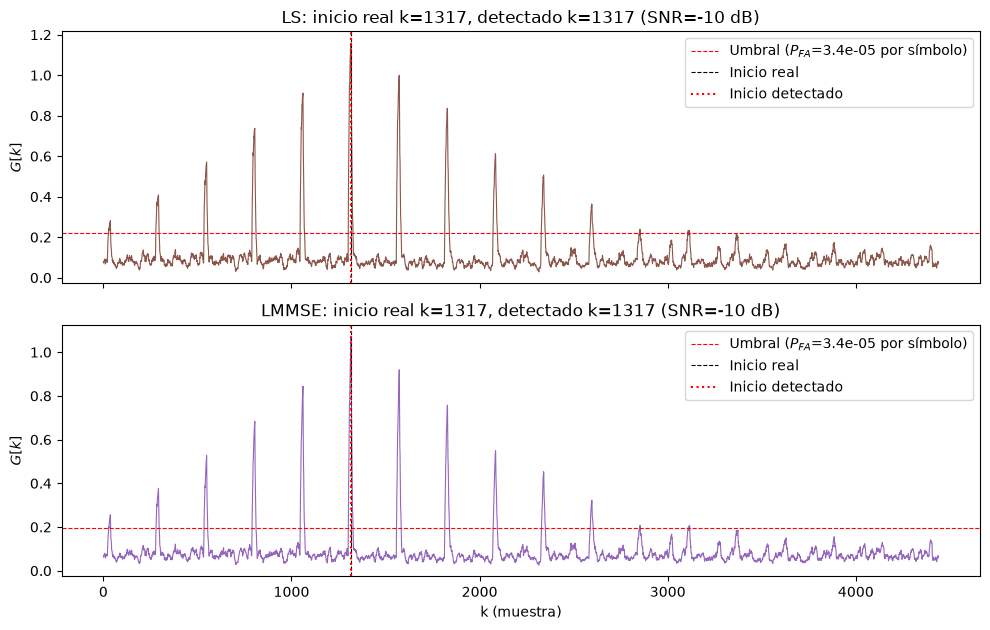

In [231]:
def estadistico_energia(r: np.ndarray, SF: int, B: float, w: np.ndarray) -> np.ndarray:
    """
    Estadístico G[k]: energía de los L coeficientes estimados a partir de k, cada uno con su peso.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        w: Peso de cada uno de los L coeficientes: 1 para LS, a[l] para LMMSE.

    Devuelve:
        G[k] para cada k donde entran el preámbulo y los L caminos.
    """

    # G[k] = sum_l w[l] |X[k + l] / N_UPCHIRPS|^2. En k = tau junta la energía de todos los
    # caminos, en lugar de solo la del directo como T[k]. Los caminos se suman en energía porque
    # el receptor no conoce la fase con la que llega cada uno, solo su potencia (el perfil)
    h2 = np.abs(correlacion_preambulo(r, SF, B) / N_UPCHIRPS) ** 2
    G = np.zeros(h2.size - w.size + 1)
    for l in range(w.size):
        G += w[l] * h2[l : l + G.size]  # Coeficiente l: el camino retrasado l muestras
    return G


def umbral_ls(SF: int, sigma2: float, P_FA: float, P: np.ndarray) -> float:
    """
    Umbral de Neyman-Pearson de G_LS[k].

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        P: Perfil de potencia del canal. LS solo usa su largo L.

    Devuelve:
        El umbral eta_LS.
    """

    # Bajo H0, G_LS[k] es la suma de L exponenciales independientes de media sigma^2 / N_UPCHIRPS.
    # Cada muestra usa P_FA / 2^SF
    return umbral_suma_exponenciales((sigma2 / N_UPCHIRPS,) * P.size, P_FA / 2**SF)


def umbral_lmmse(SF: int, sigma2: float, P_FA: float, P: np.ndarray) -> float:
    """
    Umbral de Neyman-Pearson de G_LMMSE[k].

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        P: Perfil de potencia del canal, P[l] = h^2[l].

    Devuelve:
        El umbral eta_LMMSE.
    """

    # Bajo H0, cada término a[l] |X[k + l] / N_UPCHIRPS|^2 es exponencial de media
    # a[l] sigma^2 / N_UPCHIRPS, y G_LMMSE[k] es su suma. Cada muestra usa P_FA / 2^SF
    a = pesos_lmmse(P, sigma2)
    return umbral_suma_exponenciales(a * sigma2 / N_UPCHIRPS, P_FA / 2**SF)


def detectar_ls(
    r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float, P: np.ndarray
) -> int | None:
    """
    Detecta el inicio de la trama con la energía de la estimación LS del canal.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        P: Perfil de potencia del canal. LS solo usa su largo L.

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
    """

    eta = umbral_ls(SF, sigma2, P_FA, P)
    G = estadistico_energia(r, SF, B, np.ones(P.size))
    return detectar_inicio(G, eta, N_UPCHIRPS * 2**SF)


def detectar_lmmse(
    r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float, P: np.ndarray
) -> int | None:
    """
    Detecta el inicio de la trama con la energía ponderada por los pesos LMMSE.

    Parámetros:
        r: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        P: Perfil de potencia del canal, P[l] = h^2[l].

    Devuelve:
        La muestra de inicio, o None si no se detecta la trama.
    """

    eta = umbral_lmmse(SF, sigma2, P_FA, P)
    G = estadistico_energia(r, SF, B, pesos_lmmse(P, sigma2))
    return detectar_inicio(G, eta, N_UPCHIRPS * 2**SF)


def graficar_deteccion_energia(
    G: dict[str, np.ndarray],
    etas: dict[str, float],
    inicios: dict[str, int | None],
    tau: int,
    P_FA: float,
    SNR_dB: float,
):
    """
    Grafica G[k] de la estimación LS y de la LMMSE, con sus umbrales.

    Parámetros:
        G: Estadístico de cada estimador ("LS", "LMMSE").
        etas: Umbral de cada estimador.
        inicios: Muestra de inicio detectada por cada estimador, o None.
        tau: Muestra de inicio real.
        P_FA: Probabilidad de falsa alarma por símbolo, para la leyenda.
        SNR_dB: SNR del canal, para el título.

    Devuelve:
        La figura.
    """

    fig, axs = plt.subplots(len(G), 1, figsize=(10, 3.2 * len(G)), sharex=True, squeeze=False)
    for ax, (nombre, estadistico) in zip(axs[:, 0], G.items()):
        ax.plot(estadistico, color="C5" if nombre == "LS" else "C4", lw=0.8)
        ax.axhline(
            etas[nombre],
            color="r",
            ls="--",
            lw=0.8,
            label=f"Umbral ($P_{{FA}}$={P_FA:.1e} por símbolo)",
        )
        marcar_inicios(ax, tau, inicios[nombre])
        ax.set(
            title=f"{nombre}: inicio real k={tau}, detectado k={inicios[nombre]} (SNR={SNR_dB} dB)",
            ylabel="$G[k]$",
        )
        ax.legend(loc="upper right")
    axs[-1, 0].set_xlabel("k (muestra)")
    fig.tight_layout()
    return fig


# Detección con la estimación del canal sobre la misma trama, que empieza en tau
a = pesos_lmmse(h**2, sigma2)
G = {
    "LS": estadistico_energia(r_exp, SF, B, np.ones(h.size)),
    "LMMSE": estadistico_energia(r_exp, SF, B, a),
}
etas = {"LS": umbral_ls(SF, sigma2, P_FA, h**2), "LMMSE": umbral_lmmse(SF, sigma2, P_FA, h**2)}
inicios = {
    "LS": detectar_ls(r_exp, SF, B, sigma2, P_FA, h**2),
    "LMMSE": detectar_lmmse(r_exp, SF, B, sigma2, P_FA, h**2),
}

graficar_deteccion_energia(G, etas, inicios, tau, P_FA, SNR_dB);

### 5.6 Comparación de los métodos

#### 5.6.1 Frame Error Rate (FER)

El *Frame Error Rate* (FER) es la fracción de tramas cuyo inicio el receptor no estima en la muestra exacta, ya sea porque no detecta la trama (*miss*), porque se adelanta (falsa alarma) o porque se atrasa. Un inicio corrido una sola muestra cuenta como error, porque el demodulador corta los símbolos del *payload* a partir de él. Los errores del *payload* con el inicio correcto no cuentan, porque los mide el BER (ver *BER en función del SNR*).

![Inicio del payload a partir del inicio estimado](diagramas/inicio_payload_trama.svg)

Se simula el FER de los cinco métodos en los cuatro canales. Junto con la ROC, es la métrica para comparar los detectores. El FER cae varios órdenes de magnitud en pocos dB, así que el eje es logarítmico. Cada SNR se simula con el criterio de *BER en función del SNR*, con al menos 1000 tramas y después hasta juntar 100 tramas perdidas o llegar a $10^4$ tramas, así que el menor FER que se estima con 100 errores es $10^{-2}$.

In [232]:
def fer_vs_snr(
    SF: int,
    B: float,
    SNRs_dB: np.ndarray,
    h: np.ndarray,
    detector,
    P_FA: float,
    n_simbolos: int,
    silencio: int,
    min_tramas: int,
    max_tramas: int,
    min_errores: int = 100,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Estima el FER de un detector para cada SNR, simulando tramas.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNRs_dB: SNR a simular, en dB.
        h: Respuesta al impulso del canal.
        detector: Función detector(r, SF, B, sigma2, P_FA).
        P_FA: Probabilidad de falsa alarma por símbolo.
        n_simbolos: Símbolos del payload.
        silencio: Símbolos de silencio antes de la trama.
        min_tramas: Mínimo de tramas simuladas por SNR.
        max_tramas: Máximo de tramas simuladas por SNR.
        min_errores: Tramas perdidas con las que se deja de simular cada SNR.

    Devuelve:
        Las tramas perdidas y las tramas simuladas en cada SNR.
    """

    # Una trama se pierde si el detector no estima su inicio en la muestra exacta: no la detecta,
    # o la detecta antes (falsa alarma) o después. Como en ber_vs_snr, se simulan al menos
    # min_tramas y después se sigue hasta juntar min_errores tramas perdidas o llegar a max_tramas
    perdidas_por_snr, tramas_por_snr = [], []
    for SNR_dB in SNRs_dB:
        sigma2 = potencia_del_ruido(SF, B, SNR_dB)  # El receptor la conoce
        tramas = perdidas = 0
        while tramas < min_tramas or (perdidas < min_errores and tramas < max_tramas):
            simbolos = rng.integers(0, 2**SF, size=n_simbolos)
            r = simular_trama(simbolos, silencio, SF, B, SNR_dB, h)
            perdidas += detector(r, SF, B, sigma2, P_FA) != silencio * 2**SF
            tramas += 1
        perdidas_por_snr.append(perdidas)
        tramas_por_snr.append(tramas)
    return np.array(perdidas_por_snr), np.array(tramas_por_snr)


# Nombre y color de cada método en los gráficos
METODOS = {
    "completo": ("Tiempo (preámbulo completo)", "C0"),
    "picos": ("Tiempo (8 impulsos)", "C2"),
    "frecuencia": ("Frecuencia (demodulación)", "C1"),
    "ls": ("Estimación LS del canal", "C5"),
    "lmmse": ("Estimación LMMSE del canal", "C4"),
}


def graficar_fer_por_canal(
    SNRs_dB: np.ndarray, fer_por_canal: dict[str, dict[str, tuple[np.ndarray, np.ndarray]]]
):
    """
    Grafica el FER de cada método vs SNR, un gráfico por canal.

    Parámetros:
        SNRs_dB: SNR simulados, en dB.
        fer_por_canal: Por nombre de canal, las tramas perdidas y simuladas de cada método (por
            clave de METODOS), como las devuelve fer_vs_snr.

    Devuelve:
        La figura.
    """

    # Dos gráficos por fila, con graficar_tasa_de_error. Los puntos en 0 no entran en la escala
    # logarítmica
    n = len(fer_por_canal)
    filas = (n + 1) // 2
    fig, axs = plt.subplots(filas, 2, figsize=(12, 4.5 * filas), sharey=True, squeeze=False)
    for ax, (nombre_canal, fer_canal) in zip(axs.flat, fer_por_canal.items()):
        for metodo, (perdidas, tramas) in fer_canal.items():
            nombre, color = METODOS[metodo]
            graficar_tasa_de_error(ax, SNRs_dB, perdidas, tramas, color=color, label=nombre)
        ax.set_yscale("log", nonpositive="mask")
        ax.set(title=nombre_canal, xlabel="SNR (dB)")
        ax.grid(True, which="both", alpha=0.5)
    for ax in axs.flat[n:]:
        ax.set_visible(False)  # Lugar sobrante con un número impar de canales
    for fila in axs:
        fila[0].set_ylabel("FER")
    leyenda_puntos_huecos(axs[0, 0])
    axs[0, 0].legend()
    fig.suptitle("FER vs SNR")
    fig.tight_layout()
    return fig

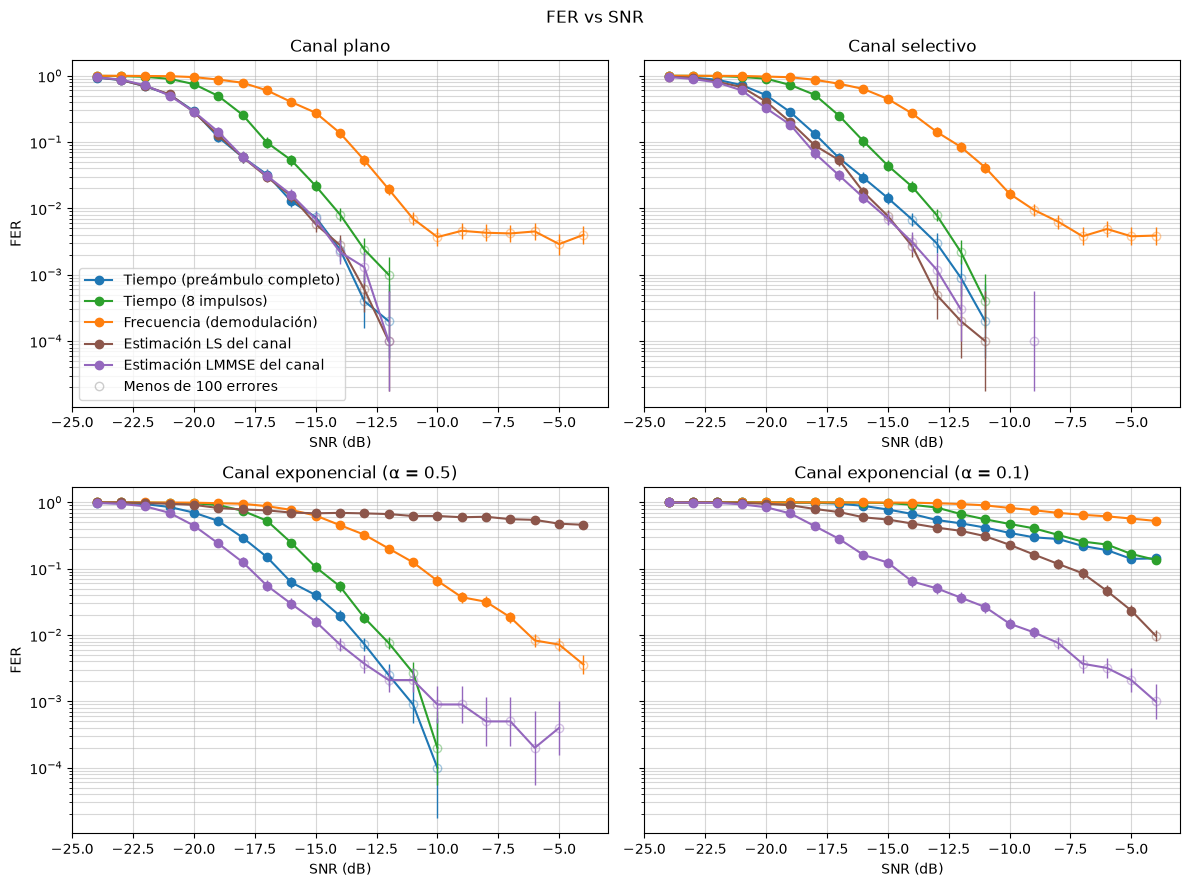

In [233]:
SNRs_fer_dB = np.arange(-24.0, -3.0, 1.0)  # -24 a -4 dB


def detectores_del_canal(h: np.ndarray) -> dict:
    """
    Detectores de cada método para un canal.

    Parámetros:
        h: Respuesta al impulso del canal.

    Devuelve:
        El detector de cada método, por clave de METODOS, con la firma detector(r, SF, B, sigma2, P_FA).
    """

    # LS y LMMSE conocen el perfil de potencia del canal, P[l] = h^2[l]. Se lo pasa con una función
    # lambda, para que tengan la misma firma que los otros tres detectores
    return {
        "completo": detectar_completo,
        "picos": detectar_picos,
        "frecuencia": detectar_frecuencia,
        "ls": lambda r, SF, B, sigma2, P_FA: detectar_ls(r, SF, B, sigma2, P_FA, h**2),
        "lmmse": lambda r, SF, B, sigma2, P_FA: detectar_lmmse(r, SF, B, sigma2, P_FA, h**2),
    }


fer = {}
for nombre_canal, h_canal in canales.items():
    fer[nombre_canal] = {}
    for metodo, detector in detectores_del_canal(h_canal).items():
        fer[nombre_canal][metodo] = fer_vs_snr(
            SF,
            B,
            SNRs_fer_dB,
            h_canal,
            detector,
            P_FA,
            n_simbolos,
            silencio,
            min_tramas=1000,
            max_tramas=10_000,
        )

graficar_fer_por_canal(SNRs_fer_dB, fer);

**Observaciones**:
- En el canal plano y en el selectivo el orden de los tres primeros métodos es correlación con el preámbulo completo, búsqueda de 8 impulsos y demodulación del preámbulo, con unos 2 dB entre cada uno (FER de 0.5 cerca de $-21$, $-19$ y $-16.5$ dB en el canal plano). Los dos métodos en el tiempo usan los mismos 8 impulsos de $y[k]$, y sumarlos antes de tomar el módulo gana esos 2 dB frente a sumar sus energías. La demodulación pierde más porque reduce cada ventana a una decisión dura, símbolo 0 o no.
- La demodulación del preámbulo tiene un piso de $\approx 4 \cdot 10^{-3}$ desde $-10$ dB, por los empates descriptos en *Método 3: Demodulación del preámbulo* ($\approx 0.4\%$). Los métodos en el tiempo no tienen piso.
- En el canal plano LS y LMMSE se superponen con la correlación con el preámbulo completo, porque con un solo camino los tres estadísticos difieren en una constante. El canal selectivo desplaza $\approx 1$ dB las curvas de los tres primeros métodos, porque su plantilla solo captura el camino directo, que lleva el 80 % de la energía ($10\log_{10} 0.8 \approx -1$ dB). LS y LMMSE suman también el eco y quedan $\approx 0.5$ dB por delante.
- En los canales exponenciales la pérdida de los tres primeros métodos crece con la energía que no llega por el camino directo, $\approx 2$ dB con $\alpha = 0.5$ y más de 7 dB con $\alpha = 0.1$, donde ninguno baja de un FER de 0.1 en el rango simulado.
- LMMSE es el mejor método en los dos canales exponenciales en el rango donde el FER se estima con 100 tramas perdidas. Con $\alpha = 0.5$ gana $\approx 1$ dB a la correlación con el preámbulo completo, y con $\alpha = 0.1$ llega a un FER de 0.2 cerca de $-16$ dB, unos 10 dB antes que ella.
- LS, en cambio, queda con un FER de entre 0.45 y 0.7 en todo el rango con $\alpha = 0.5$. Su ventana pesa igual todos los caminos, así que corrida unas muestras antes del inicio pierde solo los últimos caminos, cuya energía es menor que el ruido de un coeficiente estimado, y $G_{LS}[k]$ casi empata con su valor en el inicio. El máximo cae seguido unas muestras antes, lo que cuenta como trama perdida. Los pesos decrecientes de LMMSE deshacen ese empate.
- La correlación con el preámbulo completo es también la más costosa de los tres primeros métodos, porque aplica en cada muestra un filtro de $8 \cdot 2^{SF}$ coeficientes. LS y LMMSE le agregan solo una suma de $L$ términos por muestra, y la demodulación del preámbulo reutiliza el demodulador, con una FFT por símbolo.

#### 5.6.2 Curva ROC

El FER mezcla detección y localización, porque una trama detectada con el inicio corrido también se pierde. Para comparar los métodos solo como detectores se usa el test binario en una posición (una muestra en el tiempo, una ventana en frecuencia):

- $H_0$: los 8 símbolos a partir de la posición contienen solo ruido.
- $H_1$: la posición está alineada con el inicio del preámbulo.

La curva ROC se construye como en *Método 1: Correlación con el preámbulo completo*, y un detector es mejor que otro si su curva queda por encima. Las estrellas marcan el punto de operación de Neyman-Pearson de cada método. La ROC se calcula en el canal plano, donde los métodos con estimación del canal coinciden con la correlación con el preámbulo completo ($L = 1$), y en el canal exponencial con $\alpha = 0.1$, donde la energía se reparte entre 16 caminos y los cinco métodos se separan.

El eje es la $P_{FA}$ por símbolo, la misma con la que se fija el umbral de cada método (ver *Test de hipótesis y umbral de Neyman-Pearson*), así que los métodos se comparan a la misma tasa de falsas alarmas. Como la distribución de cada estadístico bajo $H_0$ es conocida, la $P_{FA}$ se calcula con el umbral y solo se estima $P_D$. Las curvas empíricas (punteadas), que estiman también la $P_{FA}$, validan las teóricas donde se pueden medir. La curva de la detección en frecuencia es una escalera, porque $V[m]$ solo toma 9 valores.

In [234]:
def roc_empirica(h0: np.ndarray, h1: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Curva ROC empírica a partir de realizaciones de un estadístico.

    Parámetros:
        h0: Realizaciones bajo H0.
        h1: Realizaciones bajo H1.

    Devuelve:
        P_FA y P_D de cada umbral, de mayor a menor umbral.
    """

    # Curva ROC a partir de realizaciones de un estadístico bajo H0 y bajo H1. Cada valor observado
    # es un umbral posible, y se decide H1 si el estadístico lo alcanza. Devuelve P_FA y P_D de
    # cada umbral, de mayor a menor. Un umbral infinito agrega el punto (0, 0): nunca se decide H1
    umbrales = np.concatenate([[np.inf], np.unique(np.concatenate([h0, h1]))[::-1]])

    # Fracción de realizaciones que alcanzan cada umbral (filas: realizaciones, columnas: umbrales)
    P_FA = np.mean(h0[:, None] >= umbrales, axis=0)
    P_D = np.mean(h1[:, None] >= umbrales, axis=0)
    return P_FA, P_D


def umbral(metodo: str, SF: int, sigma2: float, P_FA: float, P: np.ndarray) -> float:
    """
    Umbral de un método para una probabilidad de falsa alarma por símbolo.

    Parámetros:
        metodo: Clave de METODOS.
        SF: Factor de ensanchamiento (spreading factor).
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        P: Perfil de potencia del canal, para LS y LMMSE.

    Devuelve:
        El umbral del estadístico del método.
    """

    if metodo == "completo":
        return umbral_completo(SF, sigma2, P_FA)
    if metodo == "picos":
        return umbral_picos(SF, sigma2, P_FA)
    if metodo == "frecuencia":
        return umbral_frecuencia(SF, P_FA)
    if metodo == "ls":
        return umbral_ls(SF, sigma2, P_FA, P)
    return umbral_lmmse(SF, sigma2, P_FA, P)


def estadisticos_de_deteccion(
    SF: int, B: float, SNR_dB: float, simulaciones: int, h: np.ndarray
) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """
    Simula el estadístico de cada método en la posición 0, bajo H0 y bajo H1.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.
        simulaciones: Realizaciones por hipótesis.
        h: Respuesta al impulso del canal.

    Devuelve:
        Por método, las realizaciones bajo H0 y bajo H1.
    """

    a = pesos_lmmse(h**2, potencia_del_ruido(SF, B, SNR_dB))  # Pesos de LMMSE para este SNR
    estadisticos = {
        "completo": lambda r: estadistico_completo(r, SF, B),
        "picos": lambda r: estadistico_picos(r, SF, B),
        "frecuencia": lambda r: estadistico_frecuencia(r, SF),
        "ls": lambda r: estadistico_energia(r, SF, B, np.ones(h.size)),
        "lmmse": lambda r: estadistico_energia(r, SF, B, a),
    }
    h0 = {metodo: [] for metodo in estadisticos}
    h1 = {metodo: [] for metodo in estadisticos}
    for _ in range(simulaciones):
        # H1: trama sin silencio previo, la posición 0 está alineada con el inicio del preámbulo
        r1 = simular_trama(rng.integers(0, 2**SF, size=1), 0, SF, B, SNR_dB, h)
        # H0: solo ruido, con la misma potencia que el ruido de la trama
        r0 = ruido_awgn(preambulo(SF, B), SNR_dB)
        for metodo, estadistico in estadisticos.items():
            h0[metodo].append(estadistico(r0)[0])
            h1[metodo].append(estadistico(r1)[0])

    return {metodo: (np.array(h0[metodo]), np.array(h1[metodo])) for metodo in estadisticos}


def curvas_roc(
    SF: int,
    B: float,
    SNR_dB: float,
    simulaciones: int,
    P_FA_eje: np.ndarray,
    P_FA: float,
    h: np.ndarray,
) -> dict[str, dict]:
    """
    Calcula las curvas ROC teóricas y empíricas de los cinco métodos.

    Parámetros:
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        SNR_dB: SNR, en dB.
        simulaciones: Realizaciones por hipótesis.
        P_FA_eje: P_FA por símbolo donde se evalúa la curva teórica.
        P_FA: P_FA por símbolo del punto de operación.
        h: Respuesta al impulso del canal. LS y LMMSE conocen su perfil h^2.

    Devuelve:
        Por método: P_D_teorica, P_FA_empirica, P_D_empirica y P_D_operacion.
    """

    # Curvas ROC teóricas y empíricas de los cinco métodos. Bajo H0 la distribución de cada
    # estadístico es conocida: para cada P_FA se calcula el umbral y solo se estima la P_D con las
    # realizaciones bajo H1. Las curvas empíricas validan las teóricas donde se pueden medir
    sigma2 = potencia_del_ruido(SF, B, SNR_dB)
    curvas = {}
    for metodo, (h0, h1) in estadisticos_de_deteccion(SF, B, SNR_dB, simulaciones, h).items():
        P_FA_empirica, P_D_empirica = roc_empirica(h0, h1)
        # En el tiempo se prueban 2^SF posiciones por símbolo: P_FA por símbolo = 2^SF P_FA por
        # muestra
        posiciones_por_simbolo = 1 if metodo == "frecuencia" else 2**SF
        P_D_teorica = [np.mean(h1 >= umbral(metodo, SF, sigma2, q, h**2)) for q in P_FA_eje]
        curvas[metodo] = {
            "P_D_teorica": np.array(P_D_teorica),
            "P_FA_empirica": posiciones_por_simbolo * P_FA_empirica,
            "P_D_empirica": P_D_empirica,
            "P_D_operacion": float(np.mean(h1 >= umbral(metodo, SF, sigma2, P_FA, h**2))),
        }
    return curvas


def graficar_roc(
    curvas_por_snr: dict[float, dict], P_FA_eje: np.ndarray, P_FA: float, nombre_canal: str
):
    """
    Grafica las curvas ROC de los cinco métodos, un gráfico por SNR.

    Parámetros:
        curvas_por_snr: Salida de curvas_roc, por SNR.
        P_FA_eje: P_FA por símbolo de las curvas teóricas.
        P_FA: P_FA por símbolo del punto de operación.
        nombre_canal: Canal de las curvas, para el título.

    Devuelve:
        La figura.
    """

    # Un gráfico por SNR: curvas teóricas en línea llena, empíricas punteadas, y el punto de
    # operación de Neyman-Pearson de cada método con una estrella
    fig, axs = plt.subplots(1, len(curvas_por_snr), figsize=(14, 4.5), squeeze=False)
    for ax, (SNR_dB, curvas) in zip(axs[0], curvas_por_snr.items()):
        for metodo, curva in curvas.items():
            nombre, color = METODOS[metodo]
            # Curva teórica: P_FA exacta, P_D estimada con las realizaciones bajo H1
            ax.semilogx(P_FA_eje, curva["P_D_teorica"], color=color, label=nombre)
            # Punto de operación de Neyman-Pearson
            ax.semilogx(P_FA, curva["P_D_operacion"], "*", color=color, ms=12, mec="k")
            # Curva empírica. El eje logarítmico no puede mostrar P_FA = 0
            no_nula = curva["P_FA_empirica"] > 0
            ax.semilogx(
                curva["P_FA_empirica"][no_nula],
                curva["P_D_empirica"][no_nula],
                color=color,
                ls=":",
                lw=1,
            )
        ax.plot([], [], color="gray", ls=":", label="Empíricas")
        ax.axvline(P_FA, color="k", ls="--", lw=0.8, label=f"$P_{{FA}}$ de operación ({P_FA:.1e})")
        ax.set(
            xlim=(P_FA_eje[0], 1),
            ylim=(-0.02, 1.02),
            title=f"Curva ROC (SNR={SNR_dB:g} dB) {nombre_canal}",
            xlabel="$P_{FA}$ por símbolo",
            ylabel="$P_D$",
        )
        ax.grid(True, which="both", alpha=0.3)
    # Una sola leyenda debajo de los gráficos, para no tapar las curvas
    fig.legend(*axs[0, -1].get_legend_handles_labels(), loc="lower center", ncol=4)
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    return fig

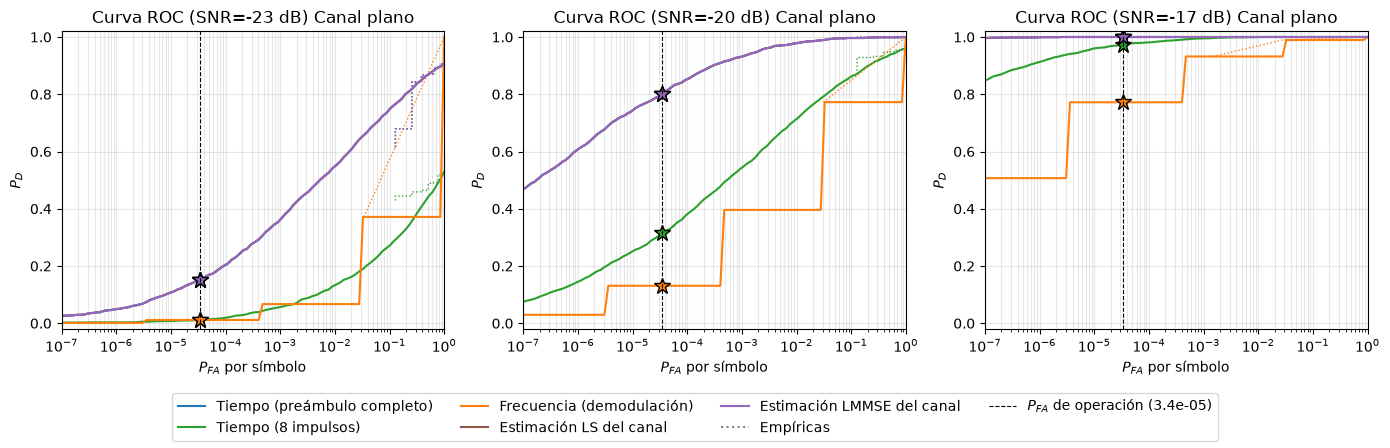

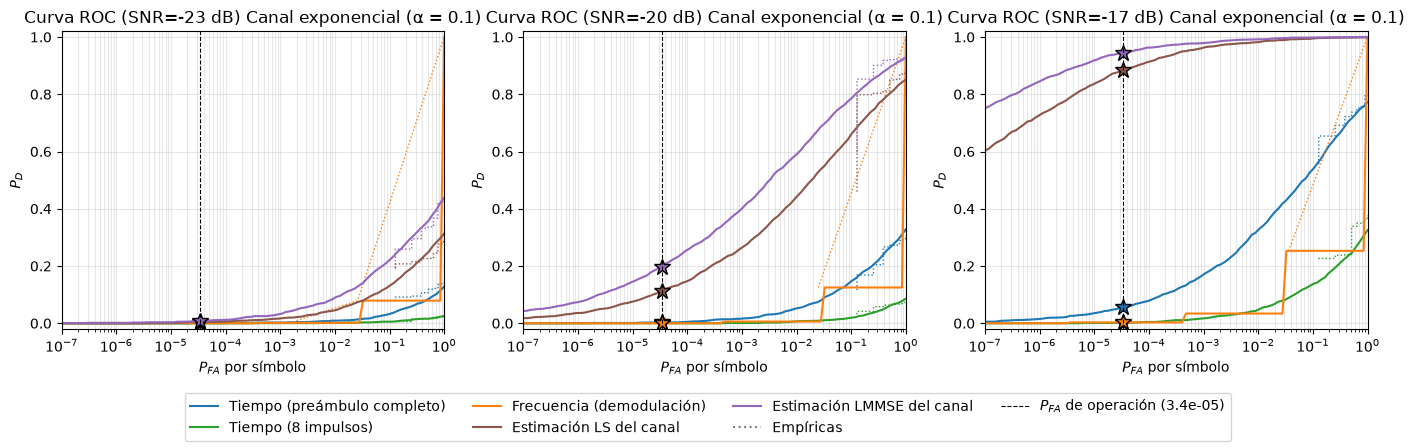

In [235]:
SNRs_roc_dB = [-23.0, -20.0, -17.0]  # Un gráfico por SNR, en el rango donde cambia la detección
simulaciones_roc = 2000  # Realizaciones por hipótesis
P_FA_eje = np.logspace(-7, 0, 100)  # P_FA por símbolo

# Una figura por canal: en el plano LS y LMMSE coinciden con el preámbulo completo (L = 1), en el
# exponencial con alfa = 0.1 la energía se reparte entre 16 caminos y los cinco métodos se separan
for nombre_canal, h_canal in (
    ("Canal plano", CANAL_PLANO),
    ("Canal exponencial (α = 0.1)", CANAL_EXP_LENTO),
):
    curvas = {
        SNR: curvas_roc(SF, B, SNR, simulaciones_roc, P_FA_eje, P_FA, h_canal)
        for SNR in SNRs_roc_dB
    }
    graficar_roc(curvas, P_FA_eje, P_FA, nombre_canal)

**Observaciones**:
- En el canal plano y en el punto de operación, a $-20$ dB, la correlación con el preámbulo completo detecta con $P_D \approx 0.8$, la búsqueda de 8 impulsos con $\approx 0.3$ y la demodulación con $\approx 0.13$. LS y LMMSE coinciden con la correlación con el preámbulo completo, que queda por encima de las otras dos para cualquier $P_{FA}$ y SNR.
- En el canal exponencial LMMSE y LS quedan por encima de los demás. A $-17$ dB detectan con $P_D \approx 0.95$ y $\approx 0.88$, contra $\approx 0.05$ de la correlación con el preámbulo completo.
- El test en una posición funciona a menor SNR que la detección del inicio. A $-20$ dB en el canal plano la correlación con el preámbulo completo tiene $P_D \approx 0.8$ pero un FER de $\approx 0.3$, y a $-17$ dB en el canal exponencial LS tiene $P_D \approx 0.88$ pero un FER de $\approx 0.75$, porque encontrar el inicio exige además que la posición correcta supere a las vecinas.

## 6. Prueba en el SDR

Hasta acá el receptor se evaluó por simulación. En este capítulo se prueba con un SDR (*software defined radio*), un equipo que transmite y recibe las muestras que genera y procesa la PC, en tres pasos:

1. **Loopback digital**: el SDR devuelve las muestras transmitidas sin pasar por el canal, y se verifica el software sin ruido.
2. **SNR y FER según la atenuación del TX**: se mide el SNR del equipo con distintas potencias de transmisión, para saber si llega al rango donde cambia el FER.
3. **FER por el aire**: se baja la señal hasta que la limite el ruido térmico del RX, y se compara el FER medido con la simulación.

Se usa un solo detector, la correlación con el preámbulo completo, que fue el de menor FER en la simulación (ver *Frame Error Rate (FER)*).

### 6.1 Configuración del experimento

El SDR es un ADALM-Pluto del laboratorio, al que se accede por una VPN. El mismo equipo transmite (TX) y recibe (RX), así que ambos comparten el oscilador local y la señal llega sin corrimiento de frecuencia.

Se usan los mismos parámetros que en la sección del FER, $SF = 8$ y tramas de 10 símbolos de *payload*, con una portadora de 905 MHz. El ancho de banda es $B = 1$ MHz, con una muestra por *chip*, dentro del rango de muestreo del Pluto (de 521 kHz a 61.44 MHz según el material del laboratorio). El SNR de la simulación es por muestra, así que $B$ solo cambia la curva de FER vs SNR a través de la $P_{FA}$ por símbolo, que con la misma tasa de falsas alarmas es 8 veces menor que con 125 kHz. La curva simulada con la que se comparan las mediciones usa este mismo $B$ (ver *FER por el aire*).

El TX repite sin pausa un buffer de varias tramas, 50 para medir el SNR y 200 para el FER. Antes de cada trama hay un silencio de largo al azar, de 5 a 10 símbolos, para que el receptor no pueda predecir dónde empieza la siguiente. El RX graba una captura que contiene todas las tramas del buffer.

El receptor recorre la captura sin saber dónde están las tramas. En cada tramo busca un preámbulo con el detector y, si lo encuentra, estima el inicio de la trama. El umbral del detector se calcula con la potencia del ruido medida en los silencios, como si el receptor la estimara mientras el canal está libre. La medición, que sí conoce lo transmitido, ubica el buffer en la captura y compara el inicio real de cada trama con el inicio detectado más cercano. Los detalles de la transmisión y del recorrido de la captura están en *Anexo B: transmisión y recepción de las tramas*.

In [236]:
# False: usa las capturas guardadas en captures/ (no necesita el SDR ni la VPN)
# True: mide con el SDR del laboratorio y sobrescribe captures/
USAR_SDR = False
URI = "ip:192.168.1.32" if USAR_SDR else None

SF_sdr = 8
B_sdr = 1e6  # Ancho de banda y frecuencia de muestreo del SDR
rango_silencio = (5, 10)  # Largo del silencio antes de cada trama, en símbolos
P_FA_sdr = R_FA * 2**SF_sdr / B_sdr  # Una falsa alarma por minuto, como en la simulación
n_tramas = 200  # Tramas por punto del FER
rango_fer_dB = (-22.0, -10.0)  # Donde el FER simulado pasa de 1 a 10^-3

In [237]:
# Conexión con el ADALM-Pluto. La biblioteca pyadi-iio (adi) solo hace falta con USAR_SDR = True.
# Los atributos del Pluto (sample_rate, tx_lo, rx(), ...) son los nombres de pyadi-iio

FRECUENCIA_LO = 905e6  # Portadora
ATENUACION_TX_dB = -10  # Atenuación del TX al conectar
RANGO_ATENUACION_TX_dB = (-89, -3)  # Con menos de 3 dB de atenuación se puede dañar el receptor

ESCALA_TX = 2**14  # Pico de I y Q del TX: pyadi espera muestras en ±2^14
FONDO_DE_ESCALA_ADC = 2**11  # El ADC del AD9363 es de 12 bits: muestras en ±2048
OBJETIVO_AGC_dB = -11  # Valor eficaz que busca el AGC slow_attack, en dB del fondo de escala
PISO_RUIDO_ADC = 1 / 6  # Ruido de cuantización complejo, 2 Δ²/12 con Δ = 1

DESCARTE = 5  # Buffers del RX descartados después de cambiar el TX. Subir si FER = 1 en loopback
ASENTAMIENTO_AGC = 15  # Buffers para que el AGC converja. Subir si la ganancia elegida varía
LARGO_DESCARTE = 2**13  # Muestras de los buffers descartados: cortos, para no traerlos por la VPN


def fijar_atenuacion_tx(pluto, atenuacion_dB: float) -> None:
    """
    Fija la atenuación del TX; da error si está fuera de RANGO_ATENUACION_TX_dB.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
        atenuacion_dB: Atenuación, en dB (negativa).
    """

    # La potencia máxima del TX es 10 dBm: con -10 dB transmite 0 dBm (1 mW)
    minima, maxima = RANGO_ATENUACION_TX_dB
    if not minima <= atenuacion_dB <= maxima:
        raise ValueError(f"Atenuación del TX fuera de [{minima}, {maxima}] dB: {atenuacion_dB}")
    pluto.tx_hardwaregain_chan0 = float(atenuacion_dB)  # pyadi rechaza los enteros de numpy


def liberar(pluto) -> None:
    """
    Deja el SDR sin interferir: máxima atenuación, TX y RX separados y TX en ceros.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
    """

    # El TX del Pluto no se puede apagar
    pluto.tx_destroy_buffer()
    fijar_atenuacion_tx(pluto, RANGO_ATENUACION_TX_dB[0])
    pluto.tx_lo = int(2400e6)
    pluto.rx_lo = int(950e6)
    pluto.tx(np.zeros(2048, dtype=complex))


@contextmanager
def sesion(uri: str, B: float, loopback: int):
    """
    Abre y configura el Pluto para usarlo con `with`; al salir, lo libera.

    Parámetros:
        uri: Dirección del SDR, por ejemplo 'ip:192.168.1.32'.
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        loopback: 0 = por el aire, 1 = loopback digital.

    Devuelve:
        El SDR configurado, en `with sesion(...) as pluto`.
    """

    # El RX queda en control automático de ganancia. Al salir del bloque `with`, aunque haya un
    # error, libera el SDR. El loopback digital no pasa por el ADC ni el DAC
    import adi

    pluto = adi.Pluto(uri)
    pluto.loopback = loopback
    pluto.sample_rate = int(B)
    pluto.tx_rf_bandwidth = int(B)
    pluto.rx_rf_bandwidth = int(B)
    pluto.tx_lo = int(FRECUENCIA_LO)
    pluto.rx_lo = int(FRECUENCIA_LO)
    fijar_atenuacion_tx(pluto, ATENUACION_TX_dB)
    pluto.gain_control_mode_chan0 = "slow_attack"
    pluto.tx_cyclic_buffer = True
    try:
        yield pluto
    finally:
        liberar(pluto)


class PlutoSimulado:
    """
    Pluto ideal para probar sin hardware: canal plano, sin ruido, con el ADC saturado.
    """

    # Pluto ideal, para probar sin hardware: rx() devuelve el buffer del TX repetido a partir de
    # una muestra al azar (canal plano, sin ruido propio ni corrimiento de frecuencia), saturado y
    # cuantizado como en el ADC. Con la ganancia GANANCIA_REF_dB el pico del TX llega a la mitad
    # del fondo de escala, como en el loopback digital del Pluto. En "slow_attack" la ganancia
    # lleva el valor eficaz a OBJETIVO_AGC_dB, como el AGC
    GANANCIA_REF_dB = 30.0
    rx_buffer_size = 0
    rx_hardwaregain_chan0 = GANANCIA_REF_dB
    gain_control_mode_chan0 = "manual"

    def tx(self, x):
        """
        Guarda el buffer que transmite el TX.

        Parámetros:
            x: Muestras a transmitir.
        """

        self.x = x

    def rx(self):
        """
        Captura rx_buffer_size muestras del buffer repetido, como las da el ADC.

        Devuelve:
            La captura.
        """

        if self.gain_control_mode_chan0 == "slow_attack":
            potencia_tx_dB = 10 * np.log10(potencia(self.x) / (2 * ESCALA_TX) ** 2)
            ganancia_dB = self.GANANCIA_REF_dB + OBJETIVO_AGC_dB - potencia_tx_dB
            self.rx_hardwaregain_chan0 = round(ganancia_dB)

        # El buffer repetido desde una muestra al azar, escalado por la ganancia del RX
        r = np.resize(np.roll(self.x, rng.integers(self.x.size)), self.rx_buffer_size)
        ganancia = 10 ** ((self.rx_hardwaregain_chan0 - self.GANANCIA_REF_dB) / 20)
        r = np.round(r * FONDO_DE_ESCALA_ADC / (2 * ESCALA_TX) * ganancia)

        # Saturación del ADC
        minimo, maximo = -FONDO_DE_ESCALA_ADC, FONDO_DE_ESCALA_ADC - 1
        return np.clip(np.real(r), minimo, maximo) + 1j * np.clip(np.imag(r), minimo, maximo)

    def tx_destroy_buffer(self):
        """
        No hace nada: está para tener los métodos del Pluto.
        """

    def rx_destroy_buffer(self):
        """
        No hace nada: está para tener los métodos del Pluto.
        """

In [238]:
# Transmisión y captura de tramas con el SDR. Las claves de los metadatos ("symbols", "gaps",
# "gain", ...) son las de los archivos de captures/


def buffer_de_tramas(simbolos: np.ndarray, silencios: np.ndarray, SF: int, B: float) -> np.ndarray:
    """
    Arma el buffer del TX: cada trama con su silencio, preámbulo y payload.

    Parámetros:
        simbolos: Payload de cada trama, una fila por trama.
        silencios: Muestras de silencio antes de cada trama.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        Las muestras del buffer, sin ruido.
    """

    chirps = tabla_de_chirps(SF, B)
    partes = []
    for simbolos_trama, silencio in zip(simbolos, silencios):
        partes.append(np.zeros(silencio))
        partes.append(preambulo(SF, B))
        for s in simbolos_trama:
            partes.append(chirps[s])
    return np.concatenate(partes)


def pico_adc(x: np.ndarray) -> float:
    """
    Mayor valor absoluto de I y Q.

    Parámetros:
        x: Señal.

    Devuelve:
        El pico.
    """

    return float(max(np.abs(x.real).max(), np.abs(x.imag).max()))


def grabar(
    pluto, x: np.ndarray, n_muestras: int, calibrar: bool = True, escala_dB: float = 0.0
) -> tuple[np.ndarray, float]:
    """
    Transmite x en forma cíclica y captura n_muestras muestras.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
        x: Buffer a transmitir.
        n_muestras: Largo de la captura.
        calibrar: Fijar la ganancia del RX con el AGC antes de capturar.
        escala_dB: Escala del TX respecto del pico ESCALA_TX, en dB.

    Devuelve:
        La captura y la ganancia del RX, en dB.
    """

    # Si `calibrar`, deja actuar al control automático de ganancia (AGC) y después fija la
    # ganancia que eligió: con el AGC activo, el silencio y la trama se recibirían con ganancias
    # distintas
    pluto.tx_destroy_buffer()
    pluto.rx_destroy_buffer()
    pluto.rx_buffer_size = LARGO_DESCARTE
    pluto.tx(x / pico_adc(x) * ESCALA_TX * 10 ** (escala_dB / 20))

    if calibrar:
        pluto.gain_control_mode_chan0 = "slow_attack"
        for _ in range(ASENTAMIENTO_AGC):
            pluto.rx()
        ganancia = pluto.rx_hardwaregain_chan0
        pluto.gain_control_mode_chan0 = "manual"
        pluto.rx_hardwaregain_chan0 = ganancia

    for _ in range(DESCARTE):  # Buffers con la señal anterior
        pluto.rx()
    pluto.rx_destroy_buffer()
    pluto.rx_buffer_size = n_muestras
    return pluto.rx(), pluto.rx_hardwaregain_chan0


def medir(
    pluto,
    SF: int,
    B: float,
    n_tramas: int,
    n_simbolos: int,
    rango_silencio: tuple[int, int],
    calibrar: bool = True,
    escala_dB: float = 0.0,
):
    """
    Transmite y captura un buffer de tramas con payloads y silencios al azar.

    Parámetros:
        pluto: SDR (o PlutoSimulado).
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        n_tramas: Tramas del buffer.
        n_simbolos: Símbolos del payload por trama.
        rango_silencio: Silencio mínimo y máximo antes de cada trama, en símbolos.
        calibrar: Fijar la ganancia del RX con el AGC antes de capturar.
        escala_dB: Escala del TX respecto del pico ESCALA_TX, en dB.

    Devuelve:
        Símbolos, silencios (en muestras), captura y ganancia del RX.
    """

    # Cada silencio dura entre rango_silencio[0] y rango_silencio[1] símbolos:
    # el receptor no puede predecir dónde empieza la trama siguiente. escala_dB baja la señal del
    # TX respecto del pico ESCALA_TX sin bajar el ruido del RX
    N = 2**SF
    simbolos = rng.integers(0, N, size=(n_tramas, n_simbolos))
    silencios = rng.integers(rango_silencio[0] * N, rango_silencio[1] * N, size=n_tramas)
    # Con un buffer de largo impar el TX del Pluto agrega una muestra en cada repetición
    silencios[0] += silencios.sum() % 2  # El preámbulo y el payload tienen largo par
    x = buffer_de_tramas(simbolos, silencios, SF, B)

    # La captura tiene el buffer completo y por lo menos tres períodos más (silencio y trama),
    # para que cada trama aparezca entera al menos una vez después de los dos primeros (evaluar).
    # Su largo no depende de los silencios, así que las capturas se pueden apilar
    mas_larga = rango_silencio[1] * N + muestras_por_trama(SF, n_simbolos)
    r, ganancia = grabar(pluto, x, (n_tramas + 3) * mas_larga, calibrar, escala_dB)
    return simbolos, silencios, r, ganancia


def apilar(corridas: list, **meta) -> tuple[np.ndarray, dict]:
    """
    Junta las salidas de medir de un barrido en capturas y metadatos.

    Parámetros:
        corridas: Salidas de medir, una por punto del barrido.
        meta: Metadatos adicionales del barrido.

    Devuelve:
        Las capturas y un diccionario con los metadatos.
    """

    simbolos, silencios, capturas, ganancias = map(np.array, zip(*corridas))
    return capturas, {"symbols": simbolos, "gaps": silencios, "gain": ganancias, **meta}


def guardar_capturas(ruta: str, capturas: np.ndarray, **meta) -> None:
    """
    Guarda capturas y metadatos en un archivo .npz.

    Parámetros:
        ruta: Archivo.
        capturas: Capturas complejas.
        meta: Metadatos.
    """

    # Las muestras del ADC son enteras: van en int16
    iq = np.stack([np.real(capturas), np.imag(capturas)], axis=-1).round().astype(np.int16)
    Path(ruta).parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(ruta, iq=iq, **meta)


def cargar_capturas(ruta: str) -> tuple[np.ndarray, dict]:
    """
    Carga un archivo .npz de guardar_capturas.

    Parámetros:
        ruta: Archivo.

    Devuelve:
        Las capturas y los metadatos.
    """

    with np.load(ruta) as archivo:
        datos = dict(archivo)
    iq = datos.pop("iq").astype(float)
    return iq[..., 0] + 1j * iq[..., 1], datos


def adquirir(
    ruta: str, medicion, B: float, uri: str | None, loopback: int = 0
) -> tuple[np.ndarray, dict]:
    """
    Mide con el SDR y guarda las capturas, o carga las guardadas.

    Parámetros:
        ruta: Archivo de las capturas.
        medicion: Función medicion(pluto) que devuelve capturas y metadatos.
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        uri: Dirección del SDR, o None para no usarlo.
        loopback: 0 = por el aire, 1 = loopback digital.

    Devuelve:
        Las capturas y los metadatos.
    """

    # Con `uri`, mide con el SDR
    # (medicion(pluto) devuelve capturas y metadatos) y las guarda en `ruta`. Sin `uri`, carga las
    # guardadas o, si no hay, mide con PlutoSimulado sin guardar
    if uri is not None:
        with sesion(uri, B, loopback) as pluto:
            capturas, meta = medicion(pluto)
        guardar_capturas(ruta, capturas, **meta)
    elif not Path(ruta).exists():
        print(f"Sin {ruta}: Pluto simulado (canal plano, sin ruido ni distorsión del equipo)")
        return medicion(PlutoSimulado())
    return cargar_capturas(ruta)

In [239]:
# Recepción y medición de las capturas (no necesita el SDR)


def recibir(
    r: np.ndarray, SF: int, B: float, sigma2: float, P_FA: float, n_simbolos: int
) -> np.ndarray:
    """
    Receptor: busca las tramas en una captura sin saber dónde están.

    Parámetros:
        r: Captura.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        sigma2: Potencia del ruido por muestra (sigma^2).
        P_FA: Probabilidad de falsa alarma por símbolo.
        n_simbolos: Símbolos del payload por trama.

    Devuelve:
        La muestra de inicio de cada trama detectada.
    """

    # Recorre la captura con una ventana de dos tramas de largo y busca un
    # preámbulo en ella. Si lo encuentra, la ventana siguiente empieza donde termina la trama. Si
    # no, avanza una trama: una trama que empieza en la primera mitad de la ventana entra entera en
    # ella, y la que empieza en la segunda mitad, en la ventana siguiente
    N = 2**SF
    largo_trama = muestras_por_trama(SF, n_simbolos)

    # La primera ventana empieza en el símbolo de menor energía de las dos primeras tramas de
    # largo, que con SNR alto cae en un silencio: si empezara a mitad de un payload, podría
    # confundir sus chirps con el preámbulo
    energia = np.convolve(np.abs(r[: 2 * largo_trama]) ** 2, np.ones(N), "valid")
    pos = int(np.argmin(energia))

    inicios = []
    while r.size - pos >= largo_trama:
        ventana = r[pos : pos + 2 * largo_trama]
        inicio = detectar_completo(ventana, SF, B, sigma2, P_FA)
        if inicio is None:
            pos += largo_trama
            continue
        pos += inicio + largo_trama
        if pos > r.size:
            break  # Trama cortada al final de la captura
        inicios.append(pos - largo_trama)
    return np.array(inicios, dtype=int)


def snr_medido(r: np.ndarray, x: np.ndarray) -> float:
    """
    Estima el SNR de una captura alineada con el buffer transmitido.

    Parámetros:
        r: Captura alineada con x.
        x: Buffer transmitido, sin ruido.

    Devuelve:
        El SNR, en dB.
    """

    # SNR de una captura r alineada con el buffer transmitido sin ruido x, respecto de la potencia
    # de la trama (como en la simulación). Se estima por mínimos cuadrados la amplitud compleja de
    # la señal recibida (ganancia y fase del canal), y lo que queda al restarla es el ruido,
    # incluida la distorsión del equipo
    a = np.vdot(x, r) / np.vdot(x, x)
    ruido = max(potencia(r - a * x), PISO_RUIDO_ADC)
    return float(10 * np.log10(np.abs(a) ** 2 * potencia(x[x != 0]) / ruido))


class Evaluacion(NamedTuple):
    """
    Resultado de evaluar una captura.
    """

    errores: np.ndarray  # Por trama transmitida: inicio no detectado en la muestra exacta
    error_inicio: np.ndarray  # Inicio detectado menos inicio real, en muestras, de las detectadas
    snr: float  # SNR medido, en dB


def evaluar(
    r: np.ndarray, simbolos: np.ndarray, silencios: np.ndarray, SF: int, B: float, P_FA: float
) -> Evaluacion:
    """
    Pasa una captura por el receptor y la compara con lo transmitido.

    Parámetros:
        r: Captura de medir.
        simbolos: Símbolos transmitidos, una fila por trama.
        silencios: Silencio antes de cada trama, en muestras.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        Errores, error del inicio y SNR.
    """

    # El receptor no sabe dónde están las tramas; la medición sí: ubica el buffer transmitido en la captura con el
    # máximo de la correlación circular, y de ahí sale el inicio real de cada trama
    n_simbolos = simbolos.shape[1]
    x = buffer_de_tramas(simbolos, silencios, SF, B)
    largo_buffer = x.size
    largo_trama = muestras_por_trama(SF, n_simbolos)
    mas_larga = silencios.max() + largo_trama

    # Inicio de cada trama en el buffer: los silencios hasta ella inclusive y las tramas anteriores
    en_buffer = np.cumsum(silencios) + np.arange(len(silencios)) * largo_trama
    # Retardo de la captura: la muestra i del buffer está en la muestra (i + retardo) mod largo_buffer
    correlacion_circular = np.fft.ifft(np.fft.fft(r[:largo_buffer]) * np.conj(np.fft.fft(x)))
    retardo = int(np.argmax(np.abs(correlacion_circular)))
    # Inicio real de cada trama, una vez cada una, después de los dos primeros períodos más
    # largos: el receptor se sincroniza en ellos y puede perder alguna trama
    reales = 2 * mas_larga + (en_buffer + retardo - 2 * mas_larga) % largo_buffer

    # La potencia del ruido se estima en el silencio antes de cada trama, donde solo hay ruido
    silencios_rx = [r[real - silencio : real] for real, silencio in zip(reales, silencios)]
    ruido = max(potencia(np.concatenate(silencios_rx)), PISO_RUIDO_ADC)

    inicios = recibir(r, SF, B, ruido, P_FA, n_simbolos)
    snr = snr_medido(np.roll(r[:largo_buffer], -retardo), x)
    if inicios.size == 0:
        return Evaluacion(np.ones(len(simbolos), dtype=bool), inicios, snr)

    # Cada trama transmitida se compara con la detección más cercana a su inicio real
    mas_cercana = np.abs(inicios[:, None] - reales).argmin(axis=0)
    error_inicio = inicios[mas_cercana] - reales
    encontradas = np.abs(error_inicio) < largo_trama // 2
    return Evaluacion(error_inicio != 0, error_inicio[encontradas], snr)


def evaluar_todas(
    capturas: np.ndarray, meta: dict, SF: int, B: float, P_FA: float
) -> list[Evaluacion]:
    """
    Evalúa cada captura de un barrido.

    Parámetros:
        capturas: Capturas de apilar.
        meta: Metadatos de apilar.
        SF: Factor de ensanchamiento (spreading factor).
        B: Ancho de banda y frecuencia de muestreo, en Hz.
        P_FA: Probabilidad de falsa alarma por símbolo.

    Devuelve:
        Una Evaluacion por captura.
    """

    evaluaciones = []
    for r, simbolos, silencios in zip(capturas, meta["symbols"], meta["gaps"]):
        evaluaciones.append(evaluar(r, simbolos, silencios, SF, B, P_FA))
    return evaluaciones

### 6.2 Loopback digital

En loopback digital, el Pluto devuelve al RX las muestras del TX sin convertirlas en una señal analógica, así que no hay ruido ni canal. Se espera detectar el inicio de todas las tramas en la muestra exacta, y cualquier error indica una falla del software.

In [240]:
def medir_loopback(pluto):
    """
    Mide 10 tramas en loopback digital, sin calibrar la ganancia.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        La captura y los metadatos.
    """

    simbolos, silencios, r, _ = medir(
        pluto, SF_sdr, B_sdr, 10, n_simbolos, rango_silencio, calibrar=False
    )
    return r, {"symbols": simbolos, "gaps": silencios}


r_loop, meta_loop = adquirir("captures/loopback.npz", medir_loopback, B_sdr, URI, loopback=1)
ev_loop = evaluar(r_loop, meta_loop["symbols"], meta_loop["gaps"], SF_sdr, B_sdr, P_FA_sdr)
print(f"Loopback digital: {ev_loop.errores.sum()} de {ev_loop.errores.size} tramas perdidas")

Loopback digital: 0 de 10 tramas perdidas


### 6.3 SNR y FER según la atenuación del TX

En la simulación, el FER pasa de casi 1 a casi 0 entre $-22$ y $-10$ dB de SNR (ver *Frame Error Rate (FER)*). Para saber si el equipo llega a ese rango, se transmiten 50 tramas con cada atenuación del TX y se miden el SNR y el FER. La ganancia del RX la elige el control automático de ganancia (AGC) del Pluto antes de cada captura, y después queda fija para que el silencio, donde se estima la potencia del ruido para el umbral, y la trama se reciban con la misma ganancia (ver *Anexo B: fondo de escala del ADC*).

El SNR se estima comparando la captura con lo transmitido. Con el buffer transmitido $x$ y la captura $r$ alineada con él, ambos de $N$ muestras, la amplitud compleja $\hat a$ con que llega la señal se estima por mínimos cuadrados, y lo que queda al restar la señal es el ruido:

$$
\hat a = \frac{\langle x, r \rangle}{\langle x, x \rangle}, \qquad
\hat\sigma^2 = \frac{\| r - \hat a\, x \|^2}{N}, \qquad
SNR = \frac{|\hat a|^2 P_{trama}}{\hat\sigma^2}
$$

donde $P_{trama}$ es la potencia de la trama, la misma referencia que en la simulación. El ruido estimado $\hat\sigma^2$ incluye el ruido térmico del RX, la cuantización y la distorsión del equipo, todo lo que no es la señal transmitida.

Si el SNR queda por encima del rango aun con la máxima atenuación, hace falta bajar la señal de otra forma.

Atenuación  -10 dB: ganancia 17 dB, SNR  17.2 dB, FER 0.00
Atenuación  -30 dB: ganancia 38 dB, SNR  15.0 dB, FER 0.00
Atenuación  -50 dB: ganancia 55 dB, SNR  15.2 dB, FER 0.00
Atenuación  -70 dB: ganancia 73 dB, SNR  15.0 dB, FER 0.00
Atenuación  -89 dB: ganancia 73 dB, SNR   9.3 dB, FER 0.00


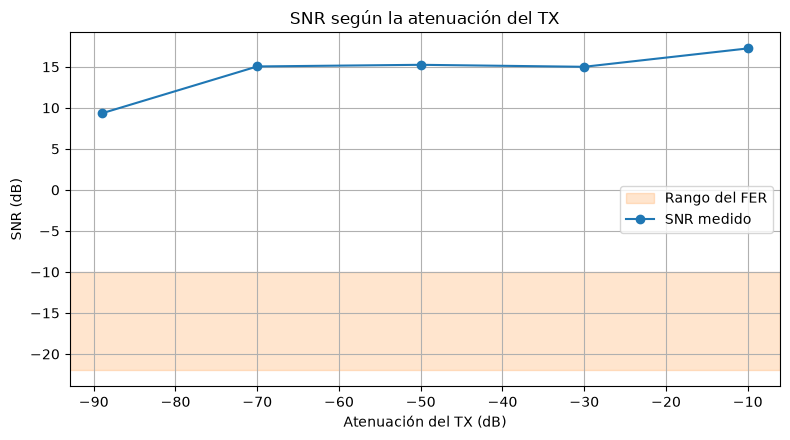

In [241]:
ATENUACIONES_dB = np.array([-10.0, -30.0, -50.0, -70.0, -89.0])


def medir_atenuaciones(pluto):
    """
    Mide 50 tramas con cada atenuación del TX de ATENUACIONES_dB.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        Las capturas y los metadatos.
    """

    corridas = []
    for atenuacion_dB in ATENUACIONES_dB:
        fijar_atenuacion_tx(pluto, atenuacion_dB)
        corridas.append(medir(pluto, SF_sdr, B_sdr, 50, n_simbolos, rango_silencio))
    return apilar(corridas, attens_dB=ATENUACIONES_dB)


def graficar_snr_vs_atenuacion(
    atenuaciones_dB: np.ndarray, snr_dB: np.ndarray, rango_fer_dB: tuple[float, float]
):
    """
    Grafica el SNR medido vs la atenuación del TX, con el rango del FER.

    Parámetros:
        atenuaciones_dB: Atenuaciones del TX.
        snr_dB: SNR medido con cada atenuación.
        rango_fer_dB: SNR donde el FER simulado pasa de casi 1 a casi 0.

    Devuelve:
        La figura.
    """

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.axhspan(min(rango_fer_dB), max(rango_fer_dB), color="C1", alpha=0.2, label="Rango del FER")
    ax.plot(atenuaciones_dB, snr_dB, "o-", label="SNR medido")
    ax.set(
        title="SNR según la atenuación del TX", xlabel="Atenuación del TX (dB)", ylabel="SNR (dB)"
    )
    ax.grid(True)
    ax.legend()
    fig.tight_layout()
    return fig


c_att, meta_att = adquirir("captures/atten.npz", medir_atenuaciones, B_sdr, URI)
evs_att = evaluar_todas(c_att, meta_att, SF_sdr, B_sdr, P_FA_sdr)
for atenuacion_dB, ganancia, ev in zip(meta_att["attens_dB"], meta_att["gain"], evs_att):
    print(
        f"Atenuación {atenuacion_dB:4.0f} dB: ganancia {ganancia:2.0f} dB, SNR {ev.snr:5.1f} dB, "
        f"FER {ev.errores.mean():.2f}"
    )
snr_att = np.array([ev.snr for ev in evs_att])
graficar_snr_vs_atenuacion(meta_att["attens_dB"], snr_att, rango_fer_dB);

**Observaciones**:
- El SNR queda entre 9 y 17 dB con cualquier atenuación del TX. Entre $-30$ y $-70$ dB casi no cambia ($\approx 15$ dB), porque el AGC sube la ganancia lo mismo que baja la señal, y lo que limita el SNR es proporcional a la señal, como la distorsión del equipo, y no el ruido del RX. Con $-70$ dB la ganancia llega a 73 dB, su máximo, y con $-89$ dB ya no puede compensar, el ruido del RX empieza a pesar y el SNR baja a 9.3 dB.
- El SNR nunca llega al rango donde cambia el FER, de $-22$ a $-10$ dB, y las 250 tramas se detectan con el inicio en la muestra exacta. Como $-89$ dB es la máxima atenuación del TX, la señal se baja reduciendo la amplitud de las muestras (ver *FER por el aire*).

### 6.4 FER por el aire

Para medir el FER en el rango de la simulación, la señal tiene que llegar por debajo del ruido. Ese ruido tiene que ser el térmico del RX, que es gaussiano y es el que limita a un receptor real cuando la señal llega débil.

Con la máxima atenuación del TX la señal todavía llega por encima del ruido (ver *SNR y FER según la atenuación del TX*). Por eso se mantiene esa atenuación y además se multiplican las muestras por una escala de $-27$ a $-36$ dB, en pasos de 1 dB, antes de transmitirlas. La señal baja y el ruido del RX no cambia. La atenuación tiene que ser la máxima porque el TX también emite su propio ruido y la fuga de su oscilador local, que la escala no reduce y que tienen que llegar por debajo del ruido del RX.

Que la señal quede por debajo del ruido no es un problema para el ADC mientras el ruido ocupe varios niveles, porque entonces la cuantización agrega poco frente a él. Otra forma de llegar al rango del FER sería sumar ruido blanco gaussiano a las muestras antes de transmitirlas, con el mismo modelo que la simulación. No se usa porque ese ruido se genera en la PC y no es el que limita a un receptor real.

El FER medido se compara con el simulado en el canal plano, con el mismo detector y los mismos parámetros. Se espera que los puntos queden sobre la curva simulada, porque en el laboratorio las reflexiones recorren a lo sumo algunos metros más que el camino directo, unas decenas de ns, mucho menos que un *chip* de 1 µs, y el canal se comporta como plano. Si quedaran a la derecha (más SNR para el mismo FER), la diferencia sería una pérdida del equipo real. La curva simulada sigue el criterio de *BER en función del SNR*. Las mediciones no, porque juntar 100 tramas perdidas con un FER de $10^{-2}$ lleva $10^4$ tramas, cincuenta veces las de un punto medido, y el tiempo de medición por la VPN sería excesivo. Con 200 tramas por punto solo los puntos con FER mayor a 0.5 juntan 100 errores, y en los demás el intervalo de confianza muestra cuánto puede variar el FER medido. El menor FER que se puede medir es $1/200 = 5 \cdot 10^{-3}$. Un punto sin errores no entra en la escala logarítmica, y se dibuja en ese valor como cota superior.

In [242]:
# Escala digital del TX, con la máxima atenuación: lleva el SNR al rango del FER, un punto por dB
ESCALAS_dB = np.arange(-36.0, -26.0)  # -36 a -27 dB


def medir_ruido_termico(pluto):
    """
    Mide n_tramas tramas con cada escala de ESCALAS_dB y la máxima atenuación.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        Las capturas y los metadatos.
    """

    fijar_atenuacion_tx(pluto, RANGO_ATENUACION_TX_dB[0])
    corridas = []
    for escala_dB in ESCALAS_dB:
        corrida = medir(
            pluto, SF_sdr, B_sdr, n_tramas, n_simbolos, rango_silencio, escala_dB=escala_dB
        )
        corridas.append(corrida)
    return apilar(corridas, scales_dB=ESCALAS_dB)


c_termica, meta_termica = adquirir("captures/thermal.npz", medir_ruido_termico, B_sdr, URI)
evs_termica = evaluar_todas(c_termica, meta_termica, SF_sdr, B_sdr, P_FA_sdr)
for escala_dB, ganancia, r, ev in zip(
    meta_termica["scales_dB"], meta_termica["gain"], c_termica, evs_termica
):
    no_detectadas = ev.errores.size - ev.error_inicio.size
    print(
        f"Escala {escala_dB:5.1f} dB: SNR medido {ev.snr:5.1f} dB, ganancia {ganancia:2.0f} dB, "
        f"valor eficaz {np.sqrt(potencia(r)):4.0f} niveles del ADC, "
        f"FER {ev.errores.mean():.3f} ({no_detectadas} no detectadas)"
    )

error_inicio = np.concatenate([ev.error_inicio for ev in evs_termica])
valores, cantidades = np.unique(error_inicio, return_counts=True)
print(
    "Error del inicio detectado (muestras: tramas):",
    dict(zip(valores.tolist(), cantidades.tolist())),
)

Escala -36.0 dB: SNR medido -25.8 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.995 (198 no detectadas)
Escala -35.0 dB: SNR medido -24.9 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.985 (196 no detectadas)
Escala -34.0 dB: SNR medido -22.5 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.850 (164 no detectadas)
Escala -33.0 dB: SNR medido -22.6 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.910 (177 no detectadas)
Escala -32.0 dB: SNR medido -20.4 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.465 (74 no detectadas)
Escala -31.0 dB: SNR medido -19.5 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.330 (40 no detectadas)
Escala -30.0 dB: SNR medido -19.7 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.340 (46 no detectadas)
Escala -29.0 dB: SNR medido -17.5 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.045 (4 no detectadas)
Escala -28.0 dB: SNR medido -16.5 dB, ganancia 73 dB,

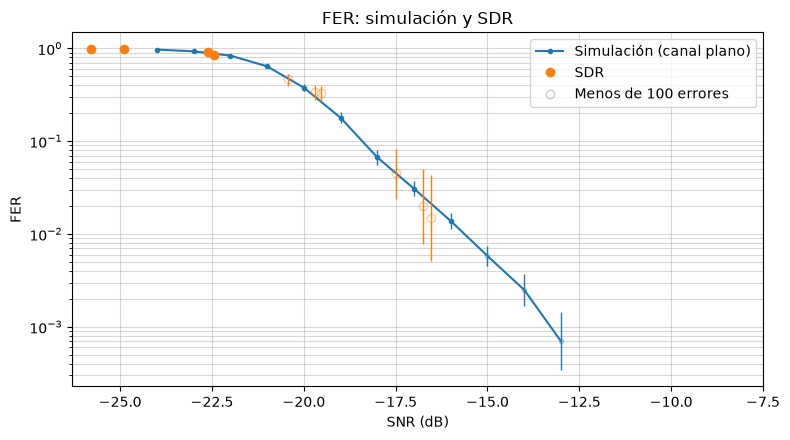

In [243]:
def graficar_fer_sdr(
    SNRs_sim_dB: np.ndarray,
    fer_sim: tuple[np.ndarray, np.ndarray],
    snr: np.ndarray,
    fer: tuple[np.ndarray, np.ndarray],
):
    """
    Grafica el FER medido con el SDR sobre el FER simulado.

    Parámetros:
        SNRs_sim_dB: SNR simulados, en dB.
        fer_sim: Tramas perdidas y simuladas en cada SNR (fer_vs_snr).
        snr: SNR medido de cada punto del SDR.
        fer: Tramas perdidas y medidas en cada punto del SDR.

    Devuelve:
        La figura.
    """

    # FER medido con el SDR sobre la curva simulada en canal plano, los dos con su intervalo de
    # confianza. Los puntos medidos sin errores no entran en la escala logarítmica: se dibujan en
    # 1 / tramas medidas, el menor FER que se puede medir, como cota superior
    fig, ax = plt.subplots(figsize=(8, 4.5))
    # Un punto por SNR simulado, para distinguirlos de los tramos interpolados
    graficar_tasa_de_error(ax, SNRs_sim_dB, *fer_sim, ms=3, label="Simulación (canal plano)")
    perdidas, tramas = fer
    graficar_tasa_de_error(ax, snr, perdidas, tramas, ls="none", color="C1", label="SDR")
    sin_errores = perdidas == 0
    if np.any(sin_errores):
        ax.plot(
            snr[sin_errores],
            1 / tramas[sin_errores],
            "v",
            color="C1",
            mfc="none",
            label=f"SDR, sin errores en {tramas[sin_errores][0]} tramas",
        )
    leyenda_puntos_huecos(ax)
    ax.set_yscale("log", nonpositive="mask")
    snrs = np.concatenate([SNRs_sim_dB, snr])
    ax.set_xlim(snrs.min() - 0.5, snrs.max() + 0.5)
    ax.set(title="FER: simulación y SDR", xlabel="SNR (dB)", ylabel="FER")
    ax.grid(True, which="both", alpha=0.5)
    ax.legend()
    fig.tight_layout()
    return fig


# Referencia: FER simulado en canal plano con el mismo detector y los mismos parámetros, con
# al menos 1000 tramas por SNR, y después hasta juntar 100 tramas perdidas o llegar a 10000
SNRs_sim_dB = np.arange(-24.0, -7.0, 1.0)
fer_sim = fer_vs_snr(
    SF_sdr,
    B_sdr,
    SNRs_sim_dB,
    CANAL_PLANO,
    detectar_completo,
    P_FA_sdr,
    n_simbolos,
    rango_silencio[0],
    min_tramas=1000,
    max_tramas=10_000,
)
snr_termica = np.array([ev.snr for ev in evs_termica])
# FER medido: tramas perdidas y medidas en cada punto
perdidas_termica = np.array([ev.errores.sum() for ev in evs_termica])
tramas_termica = np.array([ev.errores.size for ev in evs_termica])
graficar_fer_sdr(SNRs_sim_dB, fer_sim, snr_termica, (perdidas_termica, tramas_termica));

**Observaciones**:
- El FER medido sigue la curva simulada en todo el rango, de $\approx 1$ a $-26$ dB a $\approx 0.02$ cerca de $-16.5$ dB, y el intervalo de confianza de cada punto medido alcanza la curva. El ruido térmico del RX se comporta como el ruido blanco gaussiano de la simulación, y el equipo no agrega pérdidas al receptor.
- La ganancia del RX queda en su máximo (73 dB) y el valor eficaz de la captura en 15 o 16 niveles del ADC en todos los puntos. El ruido no cambia con la señal, por lo que es el del RX, y ocupa varios niveles, así que la cuantización del ADC no pesa.
- Las 92 tramas detectadas con el inicio corrido lo tienen corrido un número entero de símbolos, 79 de ellas un símbolo ($\pm 256$ muestras), por los impulsos laterales de $T[k]$ (ver *Método 1: Correlación con el preámbulo completo*).

## Anexo A: la Ec. 2 del paper

El notebook usa el *chirp* de LoRa de *Conformador de onda* y no la Ec. 2 tal como está escrita en el paper, que omite el factor $1/2$ del término cuadrático de la fase ([Chiani y Elzanaty, sección II](https://doi.org/10.1109/JIOT.2019.2919151)). Con la misma banda centrada, las muestras de la Ec. 2 son

$$
c_V(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left(s(nT_s) + k\right) \frac{k}{2^{SF}}}\,(-1)^k = c(nT_s + kT)\, e^{\,j\pi \frac{k^2}{2^{SF}}}
$$

Las dos señales difieren en el factor $e^{j\pi k^2/2^{SF}}$, que tiene módulo 1 y es el mismo para todos los símbolos. Si el receptor multiplica por el *down-chirp* de la misma señal que se transmitió, ese factor se cancela. Las señales de símbolos distintos siguen siendo ortogonales (Ec. 4 a 8) y el ruido blanco gaussiano conserva su estadística, así que en el canal plano el BER es el mismo y los resultados del paper valen también para el *chirp* de LoRa. Si el receptor usa el *down-chirp* de la otra señal, el factor queda sin cancelar y la demodulación falla.

Para comprobarlo se simula el BER de las dos modulaciones, cada una con su demodulador, con los mismos parámetros que en *BER en función del SNR*, de donde se toman las curvas del *chirp* de LoRa. Se incluye el canal selectivo en frecuencia, donde el argumento anterior no alcanza porque el eco llega retrasado. Se agrega una curva en el canal plano con el *chirp* de LoRa en el transmisor y el demodulador de la Ec. 16 sin adaptar en el receptor, que es lo que pasaría si un receptor construido según la Ec. 2 recibiera una señal LoRa.

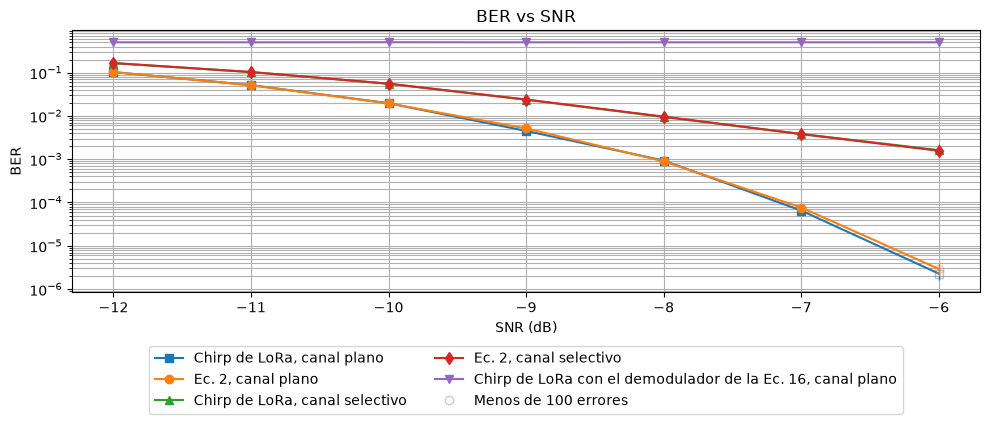

In [244]:
def conformador_ec2(simbolos: np.ndarray, SF: int) -> np.ndarray:
    """
    Genera la señal de la Ec. 2 tal como está escrita en el paper, con la banda centrada.

    Parámetros:
        simbolos: Símbolos a transmitir, entre 0 y 2^SF - 1.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Los chips de todos los símbolos, uno tras otro (2^SF por símbolo).
    """

    # c_V = e^{j2π (s + k) k / 2^SF} (-1)^k / sqrt(2^SF): la fase crece con k^2 y no con k^2/2 como
    # en el chirp de LoRa. En las muestras el mod de la Ec. 2 cambia la fase en un número entero de
    # ciclos, así que se omite. El (-1)^k centra la banda, igual que en conformador_de_onda
    N = 2**SF
    s = simbolos.reshape(-1, 1)  # Una fila por símbolo
    k = np.arange(N)
    return (np.exp(1j * 2 * np.pi * (s + k) * k / N) * (-1.0) ** k / np.sqrt(N)).ravel()


def demodulador_ec16(recibido: np.ndarray, SF: int) -> np.ndarray:
    """
    Demodula con la Ec. 16 tal como está escrita en el paper: de-chirpeado, FFT y máximo.

    Parámetros:
        recibido: Señal recibida.
        SF: Factor de ensanchamiento (spreading factor).

    Devuelve:
        Los símbolos demodulados.
    """

    # El down-chirp de la Ec. 16, e^{-j2π k^2 / 2^SF}, es el conjugado del símbolo 0 de la Ec. 2,
    # con el mismo (-1)^k de la banda centrada
    N = 2**SF
    k = np.arange(N)
    d = recibido.reshape(-1, N) * np.exp(-1j * 2 * np.pi * k**2 / N) * (-1.0) ** k
    return np.argmax(np.abs(np.fft.fft(d)) ** 2, axis=1)


# El anexo no depende de la secuencia aleatoria de los capítulos anteriores
rng = np.random.default_rng(0)
SF_a = 7
SNRs_a_dB = np.arange(-12.0, -5.0)  # -12 a -6 dB, como en BER en función del SNR
# Transmisiones por SNR como en BER en función del SNR
min_tx_a, max_tx_a = 500, 20_000

bers_a = {}
for nombre, curva, h_canal in (
    ("plano", "Canal plano", CANAL_PLANO),
    ("selectivo", "Canal selectivo en frecuencia", CANAL_SELECTIVO),
):
    # Las curvas del chirp de LoRa son las de BER en función del SNR
    bers_a[f"Chirp de LoRa, canal {nombre}"] = bers[curva]
    bers_a[f"Ec. 2, canal {nombre}"] = ber_vs_snr(
        SF_a,
        B,
        SNRs_a_dB,
        h_canal,
        min_tx_a,
        max_tx_a,
        conformar=lambda s: conformador_ec2(s, SF_a),
        demodular=demodulador_ec16,
    )
bers_a["Chirp de LoRa con el demodulador de la Ec. 16, canal plano"] = ber_vs_snr(
    SF_a, B, SNRs_a_dB, CANAL_PLANO, min_tx_a, max_tx_a, demodular=demodulador_ec16
)
graficar_ber_vs_snr(SNRs_a_dB, bers_a);

**Observaciones**:
- Con su propio demodulador, las dos modulaciones tienen el mismo BER en los dos canales. Las curvas solo se separan en $-8$ y $-7$ dB del canal plano, donde la estimación se apoya en pocos símbolos errados.
- Con el demodulador de la Ec. 16 sin adaptar, el BER de una señal LoRa es 0.5 con cualquier SNR. El *down-chirp* deja sin cancelar un término $e^{-j\pi k^2/2^{SF}}$, así que $d$ no es una exponencial de frecuencia constante, su energía se reparte entre los bins y la decisión es al azar.

## Anexo B: prueba en el SDR

### B.1 Transmisión y recepción de las tramas

**Transmisión**: cada trama mide $F = 5184$ muestras, el preámbulo de 10.25 símbolos y 10 símbolos de *payload*, y la precede un silencio de 5 a 10 símbolos. El TX repite sin pausa un buffer de 50 o 200 tramas.

**Captura**: empieza en un punto cualquiera del buffer, porque depende de la demora de la red y del equipo. Por eso dura un buffer completo, en el que cada trama empieza exactamente una vez, más tres tramas de margen. Las dos primeras dan lugar a que el receptor encuentre el primer preámbulo y no se cuentan, y la tercera deja lugar para que la última trama termine dentro de la captura.

**Receptor**: recorre la captura con una ventana de $2F$ muestras, como si las muestras le llegaran de a poco, y en cada ventana busca un preámbulo con el detector. Si lo encuentra, guarda el inicio y la ventana siguiente empieza donde termina esa trama. Si no, la ventana avanza $F$ muestras, de modo que cada trama entra entera en alguna ventana.

### B.2 Fondo de escala del ADC

El ADC del Pluto representa cada muestra de I y de Q con 12 bits. El mayor valor que puede representar es el fondo de escala, y si la señal lo supera, el ADC la recorta. El ruido de cuantización tiene una potencia fija, así que la relación señal-ruido de cuantización (SQNR) es de $6.02 \cdot 12 + 1.76 \approx 74$ dB para un tono que llega justo al fondo de escala, y baja 1 dB por cada dB que la señal queda por debajo.

La ganancia del RX la elige el AGC, que no lleva la señal al fondo de escala sino que deja un margen para los valores más grandes. Para medir ese margen y ver qué ruido domina se transmite un tono de $\approx 125$ kHz, de amplitud constante, y se captura con la ganancia que eligió el AGC, con menos ganancia y con 16 dB más. De cada captura se grafican el espectro y el plano I/Q, donde un tono sin distorsión es un círculo. En el espectro aparecen, además del tono, su imagen en $-125$ kHz, causada por el desbalance entre I y Q, y la fuga del oscilador local en 0 Hz.

Si el ruido fuera solo el de cuantización, que no depende de la ganancia, con menos ganancia el SNR del tono bajaría lo mismo que la ganancia. Con ganancia de más se espera que I y Q se recorten.

Ganancia 13 dB: nivel -11.0 dB respecto del fondo de escala, amplitud máxima  28%, SNR del tono  50 dB
Ganancia  0 dB: nivel -23.8 dB respecto del fondo de escala, amplitud máxima   7%, SNR del tono  45 dB
Ganancia 29 dB: nivel   1.4 dB respecto del fondo de escala, amplitud máxima 100%, SNR del tono  13 dB


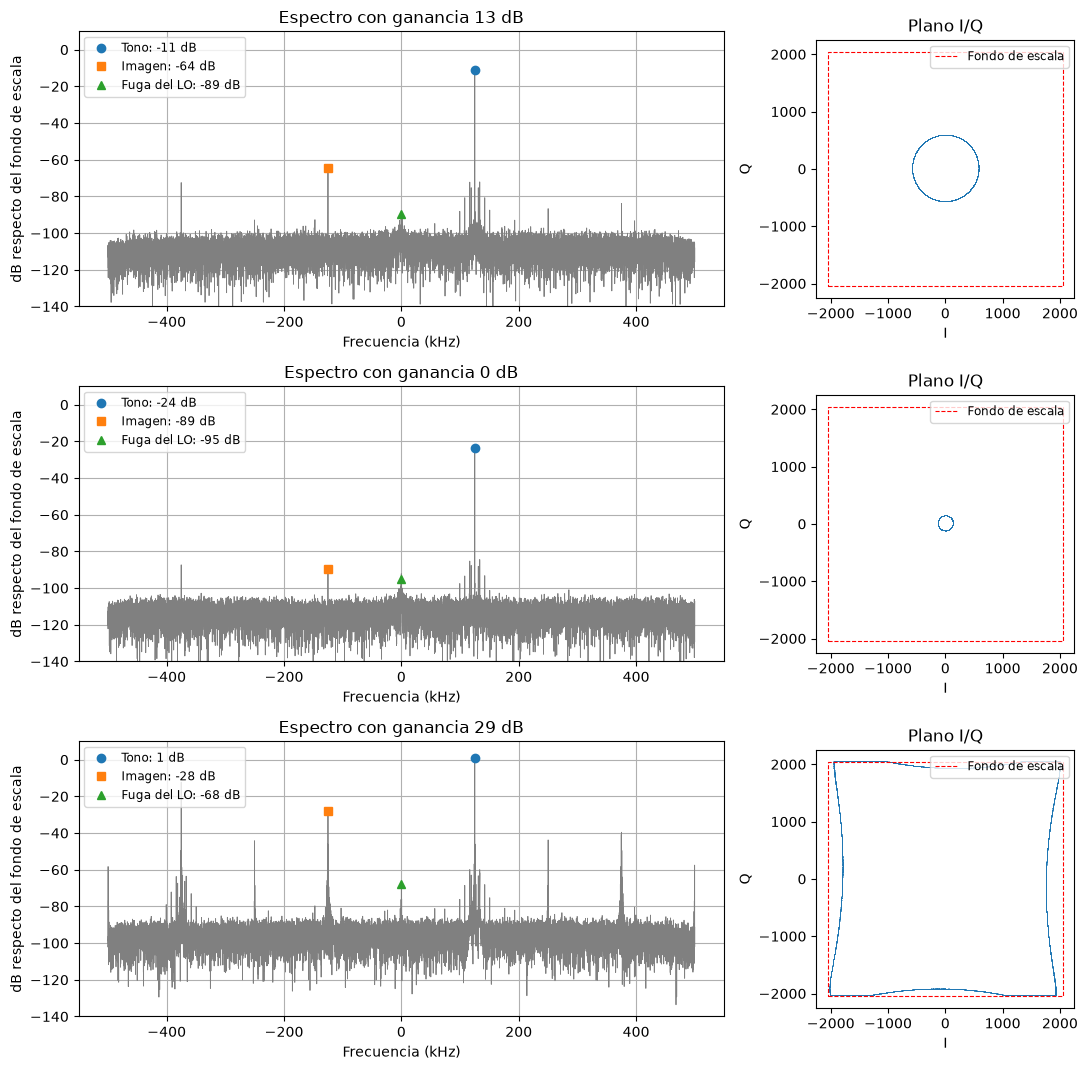

In [ ]:
# Tono de ~125 kHz con un número entero de ciclos en el buffer, para que el TX cíclico no tenga
# saltos. K_TONO impar: el error de cuantización no se repite cada pocas muestras
N_TONO, K_TONO = 2**14, 2**11 + 1
DESVIOS_GANANCIA_dB = np.array([0, -20, 16])  # Respecto de la ganancia del AGC
tono = np.exp(2j * np.pi * K_TONO * np.arange(N_TONO) / N_TONO)


def medir_tono(pluto):
    """
    Captura el tono con la ganancia que elige el AGC y con dos ganancias más.

    Parámetros:
        pluto: SDR (o PlutoSimulado).

    Devuelve:
        Las capturas y las ganancias del RX.
    """

    _, ganancia_agc = grabar(pluto, tono, N_TONO)  # El AGC elige la ganancia
    ganancias = np.clip(ganancia_agc + DESVIOS_GANANCIA_dB, 0, 70)  # Rango de ganancia del RX
    capturas = []
    for ganancia in ganancias:
        pluto.rx_hardwaregain_chan0 = float(ganancia)
        capturas.append(grabar(pluto, tono, N_TONO, calibrar=False)[0])
    return np.array(capturas), {"gains_dB": ganancias}


def graficar_tono_sdr(capturas: np.ndarray, ganancias_dB: np.ndarray, k: int, B: float):
    """
    Grafica el espectro y el plano I/Q de cada captura del tono.

    Parámetros:
        capturas: Capturas del tono, una por fila.
        ganancias_dB: Ganancia del RX de cada captura.
        k: Bin del tono en la FFT.
        B: Ancho de banda y frecuencia de muestreo, en Hz.

    Devuelve:
        La figura.
    """

    # Capturas de un tono en el bin k de la FFT con distintas ganancias del RX, una por fila:
    # espectro y plano I/Q contra el fondo de escala del ADC
    fig, axs = plt.subplots(
        len(capturas), 2, figsize=(11, 3.6 * len(capturas)), width_ratios=[2.5, 1], squeeze=False
    )
    cuadrado = FONDO_DE_ESCALA_ADC * np.array([-1, 1, 1, -1, -1])
    for r, ganancia, (ax_f, ax_iq) in zip(capturas, ganancias_dB, axs):
        X = np.abs(np.fft.fftshift(np.fft.fft(r))) / r.size / FONDO_DE_ESCALA_ADC
        X_dB = 20 * np.log10(X + 1e-12)
        f = np.fft.fftshift(np.fft.fftfreq(r.size, 1 / B)) / 1e3
        ax_f.plot(f, X_dB, color="gray", lw=0.6)
        marcas = [(k, "Tono", "o"), (-k, "Imagen", "s"), (0, "Fuga del LO", "^")]
        for bin_, nombre, marcador in marcas:
            i = r.size // 2 + bin_  # Índice después de fftshift
            ax_f.plot(f[i], X_dB[i], marcador, label=f"{nombre}: {X_dB[i]:.0f} dB")
        ax_f.set(
            title=f"Espectro con ganancia {ganancia:.0f} dB",
            xlabel="Frecuencia (kHz)",
            ylabel="dB respecto del fondo de escala",
            ylim=(-140, 10),
        )
        ax_f.grid(True)
        ax_f.legend(loc="upper left", fontsize="small")

        ax_iq.plot(np.real(r), np.imag(r), ",", alpha=0.5)
        ax_iq.plot(cuadrado, np.roll(cuadrado, 1), "r--", lw=0.8, label="Fondo de escala")
        ax_iq.set(title="Plano I/Q", xlabel="I", ylabel="Q", aspect="equal")
        ax_iq.legend(loc="upper right", fontsize="small")
    fig.tight_layout()
    return fig


c_tono, meta_tono = adquirir("captures/tone.npz", medir_tono, B_sdr, URI)
for r, ganancia in zip(c_tono, meta_tono["gains_dB"]):
    P = np.abs(np.fft.fft(r)) ** 2  # Tono en K_TONO, imagen en -K_TONO y fuga del LO en 0
    snr_tono_dB = 10 * np.log10(P[K_TONO] / (P.sum() - P[K_TONO] - P[-K_TONO] - P[0]))
    nivel_dB = 10 * np.log10(potencia(r) / FONDO_DE_ESCALA_ADC**2)
    print(
        f"Ganancia {ganancia:2.0f} dB: nivel {nivel_dB:5.1f} dB respecto del fondo de escala, "
        f"amplitud máxima {pico_adc(r) / FONDO_DE_ESCALA_ADC:4.0%}, SNR del tono {snr_tono_dB:3.0f} dB"
    )
graficar_tono_sdr(c_tono, meta_tono["gains_dB"], K_TONO, B_sdr);

**Observaciones**:
- Con la ganancia del AGC (13 dB) el tono queda a $-11$ dB del fondo de escala, con la amplitud máxima en el 28 % del rango. El AGC deja $\approx 11$ dB de margen para los valores más grandes.
- El SNR del tono es de 50 dB, menos que los $\approx 63$ dB de SQNR que corresponden a ese nivel ($74 - 11$). La captura con menos ganancia quedó en el mínimo del RX, 0 dB, 13 dB menos que la del AGC, y su SNR bajó solo 5 dB. El ruido que domina no es el de cuantización sino el analógico del RX, que la ganancia amplifica junto con el tono.
- Con 16 dB más (29 dB) I y Q se recortan, el círculo se vuelve un cuadrado, aparecen armónicos del tono y la imagen sube a 29 dB debajo del tono. El SNR cae a 13 dB.

## Anexo C: ejes para profundizar

Existen ciertos ejes que exceden el alcance del trabajo práctico pero que resultarían interesantes de analizar, entre ellos:

- **Efecto del $SF$ sobre el SNR necesario para un mismo FER**: la detección se evaluó con $SF = 8$. Cada unidad de $SF$ duplica la duración del símbolo y, a igual SNR por muestra, su energía, por lo que se espera que las curvas de FER se desplacen $\approx 3$ dB por unidad. Simularlo para varios $SF$ mostraría si los cinco métodos se desplazan lo mismo.
- **Tiempo de ejecución y memoria**: el costo de los métodos se comparó por la cantidad de operaciones (ver *Frame Error Rate (FER)*). Medir el tiempo y la memoria que usa cada uno permitiría evaluar cuál conviene en un receptor de bajo consumo.
- **Falsas alarmas con solo ruido**: los umbrales se fijan con la $P_{FA}$ teórica de cada estadístico. Aplicar cada método a una señal larga de solo ruido, simulada y también capturada con el SDR mientras el TX está en silencio, permitiría comprobar que la fracción de cruces del umbral coincide con la $P_{FA}$ pedida.